## Segmentación de canciones de Spotify mediante Clustering


## Universidad Nacional de Colombia

- Fernando Novoa Salazar
- Eduar Mauricio Méndez Méndez
- Leticia Martínez Sánchez
- Saidy Julieth Bonilla Cachaya

## Profesora:
- Elizabeth León Guzmán

**Minería de datos 2026-1**

**Facultad de Ingeniería**

**9 de junio de 2026**



### Objetivo general
Analizar un conjunto de datos de canciones de Spotify mediante técnicas de minería de datos, con el fin de identificar segmentos musicales orientados a estados de ánimo mediante algoritmos de clustering y descubrir patrones de co-ocurrencia entre características acústicas mediante reglas de asociación.

### Objetivos específicos
- Comprender la estructura y calidad del dataset.
- Identificar patrones y relaciones entre variables acústicas.
- Detectar y tratar valores atípicos (outliers).
- Limpiar datos (duplicados, nulos, inconsistencias).
- Transformar y escalar variables, incluyendo codificación cíclica para variables tonales y rítmicas.
- Reducir dimensionalidad mediante PCA para facilitar el análisis y mejorar el desempeño de los modelos.
- Descubrir reglas de asociación entre atributos acústicos discretizados mediante los algoritmos Apriori y FP-Growth.
- Segmentar las canciones en grupos de estados de ánimo mediante cuatro algoritmos de clustering: K-Means, GMM, clustering jerárquico aglomerativo y HDBSCAN.
- Comparar y validar los modelos de clustering mediante métricas internas (silueta, Davies-Bouldin, Calinski-Harabasz) y validación externa con géneros musicales.
- Interpretar semánticamente los clusters obtenidos en el marco del modelo circunflejo de Russell (1980).
- Clasificar el género musical (`track_genre`) a partir de descriptores acústicos mediante Random Forest y comparar su desempeño con Histogram Gradient Boosting y regresión logística multinomial.

## Conjunto de datos
[Ver en Google Sheets.](https://docs.google.com/spreadsheets/d/1xnXEg3NimMehGJ9j8kHVbXv54rnW7WiDMP07xrEL_rE/edit?gid=1646456706#gid=1646456706)

[Fuente del conjunto en Kaggle.](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)


## Carga de datos

El conjunto de datos se descarga desde Kaggle mediante `kagglehub` en la siguiente celda. No es necesario cargar manualmente `dataset.csv` ni montar Google Drive.

**Fuente:** [Spotify Tracks Dataset en Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset).


## Entorno

Este notebook está preparado para ejecutarse en Jupyter o Google Colab. Las dependencias se instalan desde `requirements.txt`; los archivos derivados se guardan en `outputs/`.


In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import trim_mean, skew
from numpy import mean, absolute
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.decomposition import PCA
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [70]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_dataframe(dataframe, filename, description="dataset"):
    """Guarda un DataFrame como CSV dentro de outputs/."""
    output_path = OUTPUT_DIR / filename
    dataframe.to_csv(output_path, index=False)
    print(f"{description} guardado en: {output_path}")
    print(f"Tamaño del DataFrame: {dataframe.shape}")

print(f"Directorio de resultados: {OUTPUT_DIR.resolve()}")


Directorio de resultados: C:\Users\USUARIO\Downloads\spotify-song-segmentation-starter\spotify-song-segmentation\notebooks\outputs


In [71]:
# @title Carga del dataset (descarga manual desde Kaggle)
# El archivo dataset.csv debe estar descargado manualmente desde:
# https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset
# y ubicado en la carpeta Descargas del usuario.
import pandas as pd

RUTA_DATASET = r"C:\Users\USUARIO\Downloads\archive\dataset.csv"#C:\Users\USUARIO\Downloads\archive

df = pd.read_csv(
    RUTA_DATASET,
    encoding="latin1",
    low_memory=False,
)

print(f"Dataset cargado: {df.shape}")
df.head()

Dataset cargado: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Clasificación de variables

### Tipos generales
- **int64 y float64 → Variables numéricas**
- **object → Variables categóricas**
- **bool → Variables booleanas (True / False)**

---

## Variables categóricas (cualitativas)
- **track_id:** Identificador único *(Nominal)*  
- **artists:** Nombre del artista *(Nominal)*  
- **album_name:** Nombre del álbum *(Nominal)*  
- **track_name:** Nombre de la canción *(Nominal)*  
- **track_genre:** Género musical *(Nominal)*  

---

## Variables numéricas (cuantitativas)

### Binarias
- **mode:** modalidad musical
- **explicit:** Contenido explícito *(Binaria / Booleana)*  

### Discretas
- **popularity:** Popularidad (0–100)  
- **duration_ms:** Duración en milisegundos  
- **time_signature:** Compas de la canción
- **key:** Tonalidad musical

### Continuas
- **danceability:** Facilidad para bailar (0.0–1.0)  
- **energy:** Nivel de energía (0.0–1.0)  
- **loudness:** Volumen en decibeles  
- **speechiness:** Presencia de palabras habladas  
- **acousticness:** Nivel de acústica  
- **instrumentalness:** Probabilidad de ser instrumental  
- **liveness:** Presencia de audiencia/en vivo  
- **valence:** Positividad musical  
- **tempo:** Ritmo en BPM  

---

## Variables técnicas
- **Unnamed: 0:** Índice original del archivo *(eliminable)*

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

### Pasos para la limpieza

1. Datos faltantes en algunas celdas.
2. Columnas irrelevantes.
3. Registros repetidos.
4. Valores extremos (outliers) en el caso de las variables numéricas. Revisar porque no necesariamente la solución es eliminar.


### Columnas irrelevantes
1. Las columnas irrelevantes son aquellas que no aportan información relevante para el análisis.
 En este caso, las columnas "Unnamed: 0", "id", "track_id", 'album_name' y 'track_name' no aportan información relevante para el análisis, por lo que se eliminan.
2. Una columna categórica pero con solo un nivel, es decir todos los registros son iguales, no aporta información relevante para el análisis, por lo que se elimina (ej. Si todos los registros son "Masculino" o "Femenino").
3. Una columna numérica con un solo nivel, es decir todos los registros son iguales, no aporta información relevante para el análisis, por lo que se elimina (ej. Si todos los registros son 1).
4. Columnas con información redundante, es decir que se repite la información de otra columna, no aporta información relevante para el análisis, por lo que se elimina (ej. Si la columna "nombre" y "apellido" son la misma información).

Si se duda sobre una columan es relevante o no, lo mejor es dejarla.

Verificar que no haya columnas categóricas con un solo nivel o columnas numéricas con un único valor.

In [75]:
# Eliminar duplicados por track_id, conservando la primera ocurrencia
df = df.drop_duplicates(subset=["track_id"], keep="first")
print(f"Shape tras eliminar duplicados: {df.shape}")

Shape tras eliminar duplicados: (89741, 21)


In [76]:
cols_to_drop = ["Unnamed: 0", "track_id", "album_name", "track_name"]
df = df.drop(columns=cols_to_drop, errors='ignore')
print("Columnas eliminadas:", cols_to_drop)
print("Columnas restantes:", df.columns.tolist())
print("Shape:", df.shape)

Columnas eliminadas: ['Unnamed: 0', 'track_id', 'album_name', 'track_name']
Columnas restantes: ['artists', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
Shape: (89741, 17)


In [77]:
null_percent = df.isnull().sum() / len(df) * 100
print(null_percent.sort_values(ascending=False))

artists             0.001114
speechiness         0.000000
time_signature      0.000000
tempo               0.000000
valence             0.000000
liveness            0.000000
instrumentalness    0.000000
acousticness        0.000000
mode                0.000000
popularity          0.000000
loudness            0.000000
key                 0.000000
energy              0.000000
danceability        0.000000
explicit            0.000000
duration_ms         0.000000
track_genre         0.000000
dtype: float64


---
# Preprocesamiento

In [79]:
columnas_categoricas = df.select_dtypes(include=["object"]).columns.tolist()
print("Variables categóricas:", columnas_categoricas)
print("\nNúmero de niveles por variable categórica:")
print(df[columnas_categoricas].nunique())

Variables categóricas: ['artists', 'track_genre']

Número de niveles por variable categórica:
artists        31437
track_genre      113
dtype: int64


In [80]:
print("Estadísticas descriptivas:")
df.describe()

Estadísticas descriptivas:


,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,89741.000000,8.974100e+04,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000
mean,33.198438,2.291418e+05,0.562166,0.634458,5.283549,-8.499004,0.636966,0.087442,0.328289,0.173413,0.216970,0.469477,122.058316,3.897427
std,20.580824,1.129477e+05,0.176691,0.256605,3.559897,5.221490,0.480877,0.113277,0.338321,0.323848,0.194884,0.262864,30.117532,0.453435
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,1.730400e+05,0.450000,0.457000,2.000000,-10.322000,0.000000,0.036000,0.017100,0.000000,0.098200,0.249000,99.264000,4.000000
50%,33.000000,2.132930e+05,0.576000,0.676000,5.000000,-7.185000,1.000000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,4.000000
75%,49.000000,2.642930e+05,0.692000,0.853000,8.000000,-5.108000,1.000000,0.085900,0.625000,0.097600,0.279000,0.682000,140.077000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


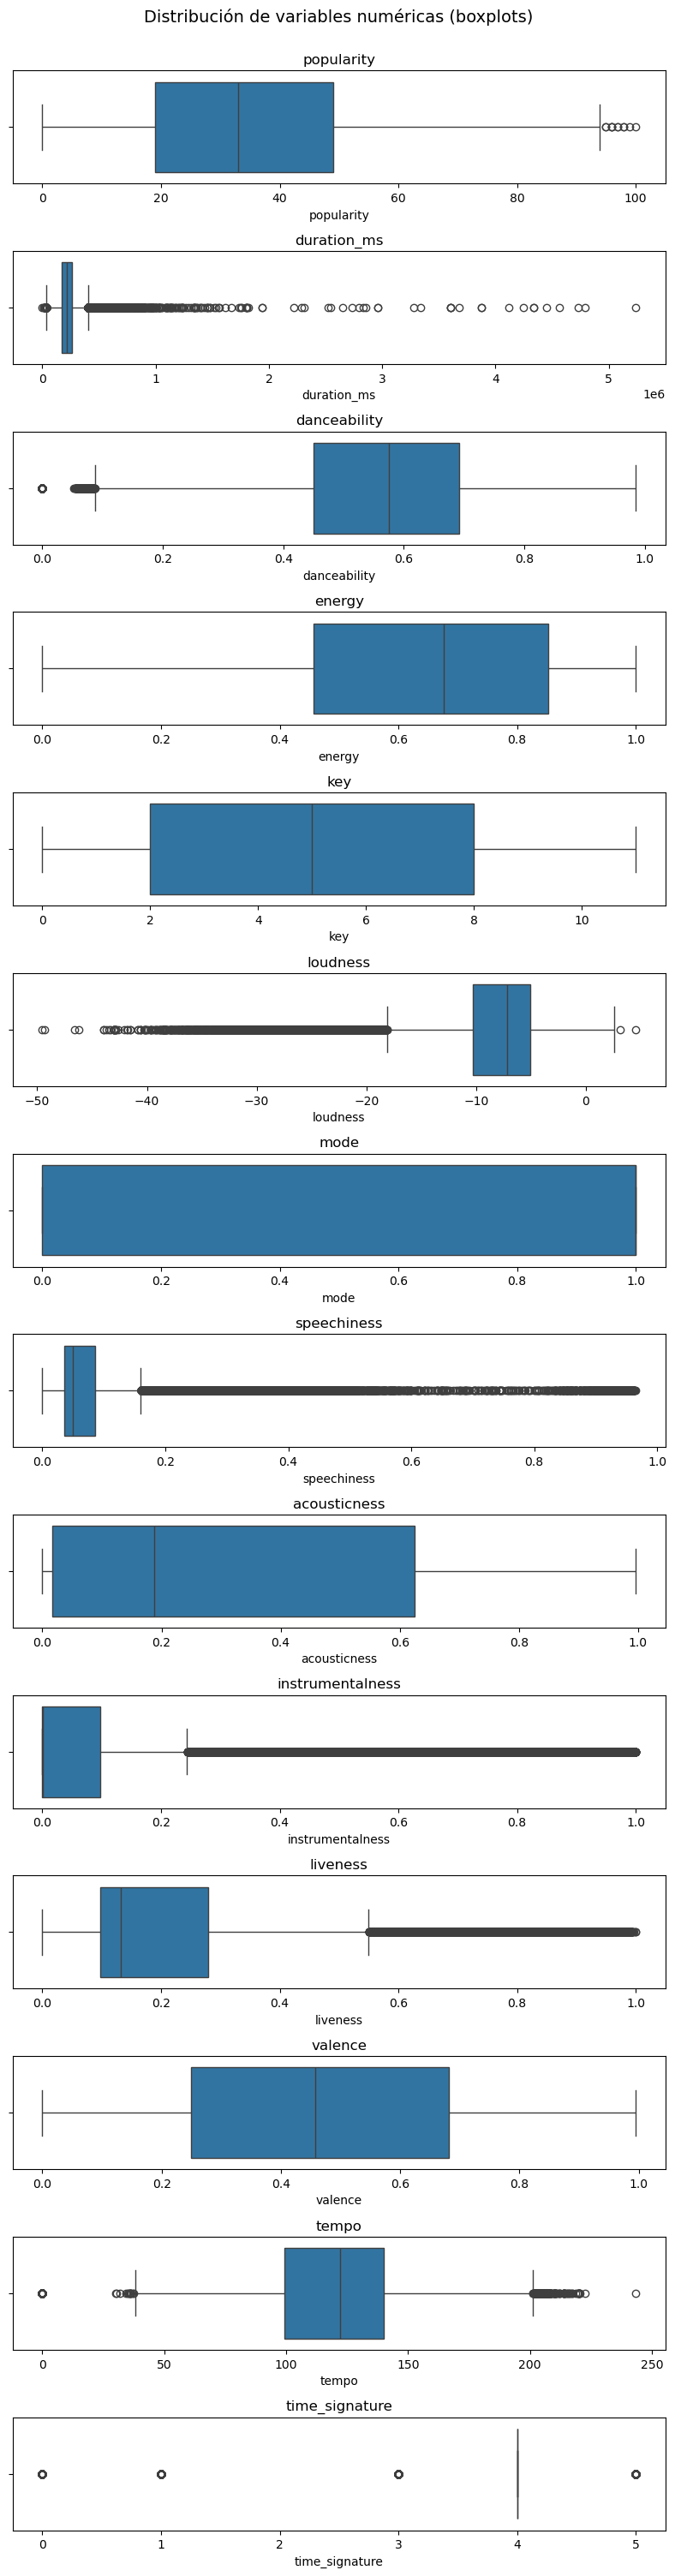

In [81]:
columnas_numericas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

fig, ax = plt.subplots(nrows=len(columnas_numericas), ncols=1, figsize=(8, 30))
fig.subplots_adjust(hspace=1)

for i, col in enumerate(columnas_numericas):
    sns.boxplot(x=col, data=df, ax=ax[i])
    ax[i].set_title(col)

plt.suptitle("Distribución de variables numéricas (boxplots)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

### Filtrado de `time_signature`

Se eliminan los registros con valores de `time_signature` inválidos (0 y 1), ya que no corresponden a compases musicales reales.

In [83]:
print("Valores únicos de time_signature:", df["time_signature"].unique())
num_incorrectos = (df['time_signature'].isin([0, 1])).sum()
print(f"Registros con valores erróneos: {num_incorrectos}")

df = df[df['time_signature'].isin([3, 4, 5, 7])]
print("Valores válidos restantes:", df['time_signature'].unique())
print("Shape:", df.shape)

Valores únicos de time_signature: [4 3 1 5 0]
Registros con valores erróneos: 1008
Valores válidos restantes: [4 3 5]
Shape: (88733, 17)


### Filtrado de `duration_ms`

El objetivo de análisis son canciones individuales, por lo que se eliminan pistas con duración inferior a 1 minuto o superior a 8 minutos.

In [85]:
df = df[(df["duration_ms"] >= 60_000) & (df["duration_ms"] <= 480_000)]
print(f"Shape tras filtrar duración: {df.shape}")

Shape tras filtrar duración: (86327, 17)


### Filtrado de `loudness`

`loudness` tiene rango teórico [−60, 0] dB. Se eliminan los 87 registros con valores mayores a 0, ya que representan valores físicamente imposibles. La normalización se aplicará posteriormente junto con las demás variables.

In [87]:
print(f"Registros con loudness > 0: {len(df[df['loudness'] > 0])}")
df = df[df["loudness"] <= 0]
print(f"Shape tras filtrar loudness: {df.shape}")

Registros con loudness > 0: 67
Shape tras filtrar loudness: (86260, 17)


### Filtrado de `speechiness`

`speechiness` mide la presencia de palabras habladas (rango [0.0, 1.0]). Se eliminan los registros con valor ≥ 0.9, ya que es muy probable que no sean canciones sino contenido hablado puro (podcasts, audiolibros, etc.).

In [89]:
print(f"Shape antes: {df.shape}")
df = df[df['speechiness'] < 0.9]
print(f"Shape tras filtrar speechiness: {df.shape}")

Shape antes: (86260, 17)
Shape tras filtrar speechiness: (85724, 17)


### Filtrado de `tempo`

Se eliminan registros con `tempo` ≤ 0, ya que corresponden a valores indetectables o erróneos.

In [91]:
print(df["tempo"].describe())
df = df[df["tempo"] > 0]
print(f"Shape tras filtrar tempo: {df.shape}")

count    85724.000000
mean       122.664384
std         29.650563
min         30.200000
25%         99.952750
50%        122.267500
75%        140.733000
max        243.372000
Name: tempo, dtype: float64
Shape tras filtrar tempo: (85724, 17)


## Análisis de asimetría (Skewness) y transformaciones

Variables como `instrumentalness`, `speechiness` y `liveness` suelen tener distribuciones muy sesgadas como pudimos oberservar en el bloxplot (la mayoría de valores concentrados cerca de 0). Esto es problemático para algoritmos basados en distancia como K-Means, que asumen distribuciones relativamente simétricas.

Analizamos la asimetría de cada variable numérica acústica:
- **|skewness| > 1**: asimetría fuerte, se recomienda transformación logarítmica `log(1+x)`.
- **|skewness| 0.5–1**: asimetría moderada, considerar raíz cuadrada.
- **|skewness| < 0.5**: aproximadamente normal, sin transformación necesaria.

In [93]:
columnas_numericas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
skewness = df[columnas_numericas].skew()
print("Asimetría por variable:")
print(skewness)

variables_problematicas = skewness[skewness.abs() > 1]
print(f"\nVariables con asimetría problemática (|skew| > 1):")
print(variables_problematicas)

Asimetría por variable:
popularity          0.045343
duration_ms         0.747368
danceability       -0.366106
energy             -0.560721
key                -0.004722
loudness           -2.000540
mode               -0.564776
speechiness         3.588643
acousticness        0.688012
instrumentalness    1.648169
liveness            2.126667
valence             0.115830
tempo               0.290925
time_signature     -1.595406
dtype: float64

Variables con asimetría problemática (|skew| > 1):
loudness           -2.000540
speechiness         3.588643
instrumentalness    1.648169
liveness            2.126667
time_signature     -1.595406
dtype: float64


La variable loudness presenta asimetría negativa, sin embargo no se le aplicará transformación logarítmica debido a que contiene valores negativos en escala de decibeles, lo que invalida el uso directo del logaritmo. En su lugar, se manejará mediante estandarización. En contraste, variables como speechiness, instrumentalness y liveness, que presentan alta asimetría en rango [0,1], por lo que serán transformadas con logaritmo para mejorar su distribución.

In [95]:
variables_log = ['speechiness', 'instrumentalness', 'liveness']
df[variables_log] = np.log1p(df[variables_log])

print("Asimetría tras transformación logarítmica:")
print(df[variables_log].skew())

Asimetría tras transformación logarítmica:
speechiness         2.969624
instrumentalness    1.568801
liveness            1.747393
dtype: float64


Las variables speechiness, instrumentalness y liveness presentan alta asimetría positiva. Tras aplicar transformación logarítmica, se observa una reducción significativa del skewness, aunque este no desaparece completamente debido a la naturaleza intrínseca de los datos. Esta transformación mejora la representación estadística sin eliminar patrones relevantes.

## Circular Encoding para variables cíclicas

Las variables `key` (tonalidad) y `time_signature` (compás) tienen estructura **cíclica**: en el caso de `key`, la nota C (0) y B (11) son adyacentes en el círculo cromático, pero numéricamente están lejos. Codificarlas con `sin` y `cos` preserva esta proximidad real.

La variable `mode` (mayor/menor) es binaria y se mantiene como 0/1.

In [98]:
# key: 12 notas musicales en el círculo cromático
df["key_sin"] = np.sin(2 * np.pi * df["key"] / 12)
df["key_cos"] = np.cos(2 * np.pi * df["key"] / 12)

# time_signature: compás con máximo 7
df['time_sig_sin'] = np.sin(2 * np.pi * df['time_signature'] / 7)
df['time_sig_cos'] = np.cos(2 * np.pi * df['time_signature'] / 7)

print("Circular encoding aplicado — primeras 5 filas:")
print(df[["key", "key_sin", "key_cos"]].head())
print()
print(df[["time_signature", "time_sig_sin", "time_sig_cos"]].head())

Circular encoding aplicado — primeras 5 filas:
   key   key_sin   key_cos
0    1  0.500000  0.866025
1    1  0.500000  0.866025
2    0  0.000000  1.000000
3    0  0.000000  1.000000
4    2  0.866025  0.500000

   time_signature  time_sig_sin  time_sig_cos
0               4     -0.433884     -0.900969
1               4     -0.433884     -0.900969
2               4     -0.433884     -0.900969
3               3      0.433884     -0.900969
4               4     -0.433884     -0.900969


In [99]:
# Eliminar las columnas originales reemplazadas por su codificación cíclica
df = df.drop(columns=['key', 'time_signature'])
print(f"Shape final del dataset limpio: {df.shape}")
df.head()

Shape final del dataset limpio: (85724, 19)


,artists,popularity,duration_ms,explicit,danceability,energy,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,track_genre,key_sin,key_cos,time_sig_sin,time_sig_cos
0,Gen Hoshino,73,230666,False,0.676,0.4610,-6.746,0,0.133656,0.0322,0.000001,0.306013,0.715,87.917,acoustic,0.500000,0.866025,-0.433884,-0.900969
1,Ben Woodward,55,149610,False,0.420,0.1660,-17.235,1,0.073529,0.9240,0.000006,0.096219,0.267,77.489,acoustic,0.500000,0.866025,-0.433884,-0.900969
2,Ingrid Michaelson;ZAYN,57,210826,False,0.438,0.3590,-9.734,1,0.054204,0.2100,0.000000,0.110647,0.120,76.332,acoustic,0.000000,1.000000,-0.433884,-0.900969
3,Kina Grannis,71,201933,False,0.266,0.0596,-18.515,1,0.035657,0.9050,0.000071,0.123986,0.143,181.740,acoustic,0.000000,1.000000,0.433884,-0.900969
4,Chord Overstreet,82,198853,False,0.618,0.4430,-9.681,1,0.051263,0.4690,0.000000,0.079643,0.167,119.949,acoustic,0.866025,0.500000,-0.433884,-0.900969


---
# **Análisis de asociación**

`df_asoc` será el DataFrame construido específicamente para minar reglas de asociación. Este DataFrem es hecho a partir de una copia del `df` original, el cual actualmente está sin outliers, pero también sin estandarización.  
A diferencia del clustering, la asociación requiere datos en **formato transaccional**: cada canción es una transacción y sus atributos discretizados son los ítems.

Las variables continuas se discretizan en tres niveles (bajo / medio / alto) mediante `pd.qcut`, que usa cuantiles para garantizar clases equilibradas. Las variables binarias y el género musical se incorporan directamente como ítems.

In [101]:
# @title Procesamiento para asociación — Discretización de variables

# Partimos de df (con variables originales, sin estandarizar, ya preprocesadas)
df_asoc = df.copy()

# --- Variables continuas → 3 niveles por cuantiles ---
bins_vars = {
    'energy':        ['energy_baja',         'energy_media',         'energy_alta'],
    'danceability':  ['danceabilidad_baja',   'danceabilidad_media',  'danceabilidad_alta'],
    'valence':       ['valencia_baja',        'valencia_media',       'valencia_alta'],
    'acousticness':  ['acusticidad_baja',     'acusticidad_media',    'acusticidad_alta'],
    'tempo':         ['tempo_lento',          'tempo_medio',          'tempo_rapido'],
    'popularity':    ['popularidad_baja',     'popularidad_media',    'popularidad_alta'],
    'loudness':      ['volumen_bajo',         'volumen_medio',        'volumen_alto'],
}

for col, labels in bins_vars.items():
    df_asoc[f'{col}_item'] = pd.qcut(
        df_asoc[col], q=3, labels=labels, duplicates='drop'
    )

# --- Variables binarias ---
df_asoc['explicit_item'] = df_asoc['explicit'].map(
    {True: 'contenido_explicito', False: 'contenido_no_explicito'}
)
df_asoc['mode_item'] = df_asoc['mode'].map(
    {0: 'modo_menor', 1: 'modo_mayor'}
)

# --- Género: solo los 15 más frecuentes para evitar explosión combinatoria ---
top_genres = df_asoc['track_genre'].value_counts().head(15).index
df_asoc['genre_item'] = df_asoc['track_genre'].apply(
    lambda x: f'genero_{x}' if x in top_genres else None
)

print("Distribución de ítems discretizados:")
for col in bins_vars:
    print(f"\n{col}_item:")
    print(df_asoc[f'{col}_item'].value_counts())

Distribución de ítems discretizados:

energy_item:
energy_item
energy_baja     28647
energy_media    28629
energy_alta     28448
Name: count, dtype: int64

danceability_item:
danceability_item
danceabilidad_media    28645
danceabilidad_baja     28580
danceabilidad_alta     28499
Name: count, dtype: int64

valence_item:
valence_item
valencia_baja     28596
valencia_media    28586
valencia_alta     28542
Name: count, dtype: int64

acousticness_item:
acousticness_item
acusticidad_baja     28579
acusticidad_media    28579
acusticidad_alta     28566
Name: count, dtype: int64

tempo_item:
tempo_item
tempo_lento     28575
tempo_rapido    28575
tempo_medio     28574
Name: count, dtype: int64

popularity_item:
popularity_item
popularidad_baja     29549
popularidad_media    28623
popularidad_alta     27552
Name: count, dtype: int64

loudness_item:
loudness_item
volumen_bajo     28584
volumen_medio    28584
volumen_alto     28556
Name: count, dtype: int64


### Exportar datos para reglas de asociación

In [103]:
# Exportar df_asoc que contiene las variables discretizadas y los ítems para el análisis de asociación.
save_dataframe(df_asoc, "spotify_association_data.csv", "DataFrame para asociación")

DataFrame para asociación guardado en: outputs\spotify_association_data.csv
Tamaño del DataFrame: (85724, 29)


In [104]:
# @title Procesamiento para asociación — Construcción de transacciones

# Excluimos explicit e items con soporte >0.85 para evitar reglas triviales
EXCLUIR_ITEMS = {'contenido_no_explicito', 'contenido_explicito'}

columnas_items = (
    [f'{col}_item' for col in bins_vars]
    + ['mode_item', 'genre_item']   # explicit_item eliminado
)

def fila_a_transaccion(row):
    return [
        str(item) for item in row
        if pd.notna(item) and str(item) not in EXCLUIR_ITEMS
    ]

transactions = (
    df_asoc[columnas_items]
    .apply(fila_a_transaccion, axis=1)
    .tolist()
)

n_transacciones = len(transactions)
long_promedio   = sum(len(t) for t in transactions) / n_transacciones

print(f"Transacciones construidas  : {n_transacciones:,}")
print(f"Ítems promedio por transac.: {long_promedio:.2f}")
print(f"\nEjemplo — transacción 0:\n  {transactions[0]}")
print(f"\nEjemplo — transacción 100:\n  {transactions[100]}")

Transacciones construidas  : 85,724
Ítems promedio por transac.: 8.17

Ejemplo — transacción 0:
  ['energy_baja', 'danceabilidad_alta', 'valencia_alta', 'acusticidad_baja', 'tempo_lento', 'popularidad_alta', 'volumen_medio', 'modo_menor', 'genero_acoustic']

Ejemplo — transacción 100:
  ['energy_media', 'danceabilidad_media', 'valencia_media', 'acusticidad_alta', 'tempo_lento', 'popularidad_alta', 'volumen_medio', 'modo_mayor', 'genero_acoustic']


Ítems únicos en el vocabulario: 38

Top 20 ítems más frecuentes:


,item,frecuencia,soporte
0,modo_mayor,54510,0.635878
1,modo_menor,31214,0.364122
2,popularidad_baja,29549,0.344699
3,energy_baja,28647,0.334177
4,danceabilidad_media,28645,0.334154
5,energy_media,28629,0.333967
6,popularidad_media,28623,0.333897
7,valencia_baja,28596,0.333582
8,valencia_media,28586,0.333466
9,volumen_bajo,28584,0.333442


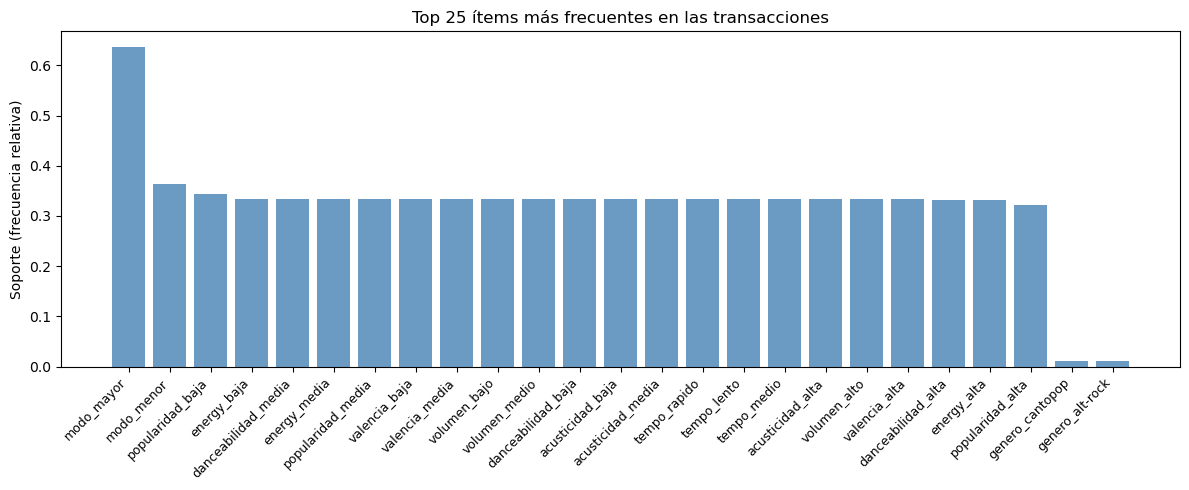

In [105]:
# @title Procesamiento para asociación — Exploración del espacio de ítems

from collections import Counter

# Frecuencia absoluta de cada ítem
conteo_items = Counter(item for t in transactions for item in t)
df_items_freq = (
    pd.DataFrame(conteo_items.items(), columns=['item', 'frecuencia'])
    .sort_values('frecuencia', ascending=False)
    .reset_index(drop=True)
)
df_items_freq['soporte'] = df_items_freq['frecuencia'] / n_transacciones

print(f"Ítems únicos en el vocabulario: {len(df_items_freq)}\n")
print("Top 20 ítems más frecuentes:")
display(df_items_freq.head(20))

# Visualización
plt.figure(figsize=(12, 5))
plt.bar(
    df_items_freq['item'].head(25),
    df_items_freq['soporte'].head(25),
    color='steelblue', alpha=0.8
)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.ylabel('Soporte (frecuencia relativa)')
plt.title('Top 25 ítems más frecuentes en las transacciones')
plt.tight_layout()
plt.show()

El ítem `contenido_no_explicito` tiene soporte muy alto (≈ 0.92), lo que generaría reglas triviales. Por ello se excluye del conjunto de transacciones junto con `contenido_explicito`.

In [107]:
# Las dependencias del análisis de asociación están en requirements.txt.
# Instala el entorno una sola vez antes de ejecutar el notebook.


In [108]:
# @title Instalación de dependencias para reglas de asociación
# Instala efficient-apriori (Apriori) y pyfpgrowth (FP-Growth).
# Ejecutar una sola vez por entorno; requiere reiniciar el kernel después.
!pip install efficient-apriori pyfpgrowth
import efficient_apriori
import pyfpgrowth
print("efficient_apriori:", efficient_apriori.__version__ if hasattr(efficient_apriori, '__version__') else "OK")
print("pyfpgrowth: OK")

efficient_apriori: 2.0.6
pyfpgrowth: OK


In [109]:
# @title Asociación — Algoritmo Apriori
from efficient_apriori import apriori
import time

MIN_SUPPORT    = 0.15   # antes 0.30
MIN_CONFIDENCE = 0.65   # antes 0.70

print(f"Parámetros: soporte mínimo = {MIN_SUPPORT}, confianza mínima = {MIN_CONFIDENCE}")
print(f"Total de transacciones: {len(transactions):,}\n")

t0 = time.time()
itemsets_ap, rules_ap = apriori(
    transactions,
    min_support=MIN_SUPPORT,
    min_confidence=MIN_CONFIDENCE
)
t_apriori = time.time() - t0

print(f"Tiempo de ejecución Apriori: {t_apriori:.2f} s")
print(f"Itemsets frecuentes encontrados: {sum(len(v) for v in itemsets_ap.values())}")
print(f"Reglas generadas              : {len(rules_ap)}\n")

# --- Convertir reglas a DataFrame ---
rows_ap = []
for r in rules_ap:
    rows_ap.append({
        'antecedente':  set(r.lhs),
        'consecuente':  set(r.rhs),
        'soporte':      round(r.support, 4),
        'confianza':    round(r.confidence, 4),
        'lift':         round(r.lift, 4),
    })

df_rules_ap = (
    pd.DataFrame(rows_ap)
      .sort_values('lift', ascending=False)
      .reset_index(drop=True)
)

print(f"=== Top 20 reglas por lift (Apriori) ===")
display(df_rules_ap.head(20))

Parámetros: soporte mínimo = 0.15, confianza mínima = 0.65
Total de transacciones: 85,724

Tiempo de ejecución Apriori: 1.27 s
Itemsets frecuentes encontrados: 62
Reglas generadas              : 21

=== Top 20 reglas por lift (Apriori) ===


,antecedente,consecuente,soporte,confianza,lift
0,"{volumen_bajo, acusticidad_alta}",{energy_baja},0.1897,0.9087,2.7192
1,"{energy_baja, acusticidad_alta}",{volumen_bajo},0.1897,0.7897,2.3685
2,"{energy_baja, volumen_bajo}",{acusticidad_alta},0.1897,0.7692,2.3083
3,"{modo_mayor, volumen_bajo}",{energy_baja},0.1687,0.7650,2.2891
4,"{energy_baja, modo_mayor}",{acusticidad_alta},0.1700,0.7389,2.2173
5,{volumen_bajo},{energy_baja},0.2466,0.7395,2.2130
6,{energy_baja},{volumen_bajo},0.2466,0.7379,2.2130
7,"{energy_baja, modo_mayor}",{volumen_bajo},0.1687,0.7332,2.1988
8,"{modo_mayor, acusticidad_alta}",{energy_baja},0.1700,0.7328,2.1929
9,{acusticidad_alta},{energy_baja},0.2402,0.7208,2.1568


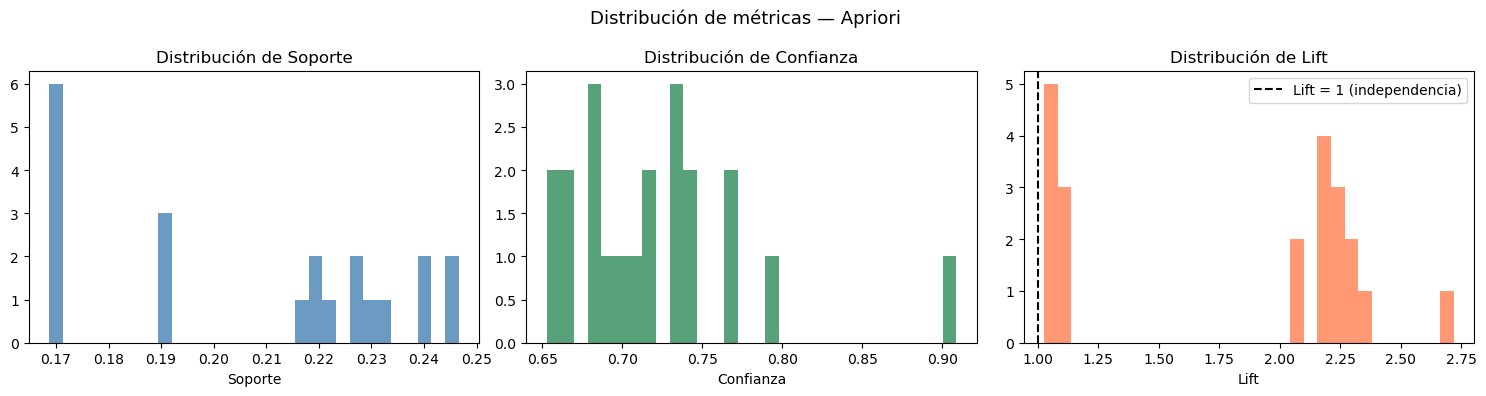

Reglas tras filtrar triviales (lift > 1.05, sin ítems triviales): 18

=== Reglas más significativas — Apriori ===


,antecedente,consecuente,soporte,confianza,lift
0,"{volumen_bajo, acusticidad_alta}",{energy_baja},0.1897,0.9087,2.7192
1,"{energy_baja, acusticidad_alta}",{volumen_bajo},0.1897,0.7897,2.3685
2,"{energy_baja, volumen_bajo}",{acusticidad_alta},0.1897,0.7692,2.3083
3,"{modo_mayor, volumen_bajo}",{energy_baja},0.1687,0.7650,2.2891
4,"{energy_baja, modo_mayor}",{acusticidad_alta},0.1700,0.7389,2.2173
5,{volumen_bajo},{energy_baja},0.2466,0.7395,2.2130
6,{energy_baja},{volumen_bajo},0.2466,0.7379,2.2130
7,"{energy_baja, modo_mayor}",{volumen_bajo},0.1687,0.7332,2.1988
8,"{modo_mayor, acusticidad_alta}",{energy_baja},0.1700,0.7328,2.1929
9,{acusticidad_alta},{energy_baja},0.2402,0.7208,2.1568


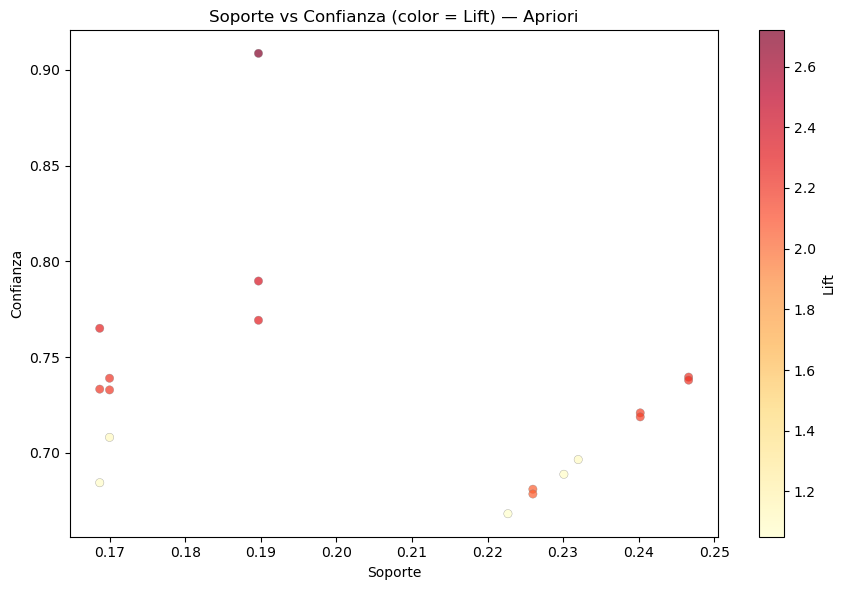

In [110]:
# @title Asociación — Análisis de reglas Apriori

# --- Distribución de métricas ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_rules_ap['soporte'],    bins=30, color='steelblue',  alpha=0.8)
axes[0].set_title('Distribución de Soporte')
axes[0].set_xlabel('Soporte')

axes[1].hist(df_rules_ap['confianza'],  bins=30, color='seagreen',   alpha=0.8)
axes[1].set_title('Distribución de Confianza')
axes[1].set_xlabel('Confianza')

axes[2].hist(df_rules_ap['lift'],       bins=30, color='coral',      alpha=0.8)
axes[2].set_title('Distribución de Lift')
axes[2].set_xlabel('Lift')
axes[2].axvline(x=1, color='black', linestyle='--', label='Lift = 1 (independencia)')
axes[2].legend()

plt.suptitle('Distribución de métricas — Apriori', fontsize=13)
plt.tight_layout()
plt.show()

# --- Reglas más significativas (lift > 1, sin ítems triviales) ---
ITEMS_TRIVIALES = {'contenido_no_explicito'}

df_rules_ap_filtradas = df_rules_ap[
    (df_rules_ap['lift'] > 1.05) &
    (~df_rules_ap['antecedente'].apply(lambda s: bool(s & ITEMS_TRIVIALES))) &
    (~df_rules_ap['consecuente'].apply(lambda s: bool(s & ITEMS_TRIVIALES)))
].reset_index(drop=True)

print(f"Reglas tras filtrar triviales (lift > 1.05, sin ítems triviales): {len(df_rules_ap_filtradas)}\n")
print("=== Reglas más significativas — Apriori ===")
display(df_rules_ap_filtradas.head(15))

# --- Scatter soporte vs confianza coloreado por lift ---
plt.figure(figsize=(9, 6))
sc = plt.scatter(
    df_rules_ap_filtradas['soporte'],
    df_rules_ap_filtradas['confianza'],
    c=df_rules_ap_filtradas['lift'],
    cmap='YlOrRd', alpha=0.7, edgecolors='grey', linewidths=0.3
)
plt.colorbar(sc, label='Lift')
plt.xlabel('Soporte')
plt.ylabel('Confianza')
plt.title('Soporte vs Confianza (color = Lift) — Apriori')
plt.tight_layout()
plt.show()

In [111]:
# @title Asociación — Algoritmo FP-Growth
import pyfpgrowth

# pyfpgrowth recibe soporte como conteo absoluto
MIN_SUPPORT_COUNT = int(MIN_SUPPORT * len(transactions))
print(f"Soporte mínimo absoluto: {MIN_SUPPORT_COUNT:,}  ({MIN_SUPPORT*100:.0f}% de {len(transactions):,})")
print(f"Confianza mínima       : {MIN_CONFIDENCE}\n")

t0 = time.time()
patterns_fp = pyfpgrowth.find_frequent_patterns(transactions, MIN_SUPPORT_COUNT)
rules_fp_raw = pyfpgrowth.generate_association_rules(patterns_fp, MIN_CONFIDENCE)
t_fpgrowth = time.time() - t0

print(f"Tiempo de ejecución FP-Growth: {t_fpgrowth:.2f} s")
print(f"Patrones frecuentes encontrados: {len(patterns_fp)}")
print(f"Reglas generadas               : {len(rules_fp_raw)}\n")

# --- Convertir reglas a DataFrame (FP-Growth) ---
# Construimos un diccionario de soporte individual desde conteo_items
# para evitar el bug de pyfpgrowth con tuplas de un solo elemento
soporte_individual = {
    item: freq / n_transacciones
    for item, freq in conteo_items.items()
}

def soporte_itemset(itemset_tuple):
    """Busca el soporte de un itemset en patterns_fp con clave ordenada."""
    key = tuple(sorted(itemset_tuple))
    return patterns_fp.get(key, 0) / n_transacciones

rows_fp = []
for antec, (consec, confianza) in rules_fp_raw.items():
    antec_set  = set(antec)
    consec_set = set(consec)

    # Soporte del itemset completo (antecedente ∪ consecuente)
    union   = tuple(sorted(antec_set | consec_set))
    soporte = soporte_itemset(union)

    # Soporte del consecuente: usar lookup individual si es un solo ítem
    if len(consec_set) == 1:
        soporte_c = soporte_individual.get(next(iter(consec_set)), 0)
    else:
        soporte_c = soporte_itemset(tuple(consec))

    lift = round(confianza / soporte_c, 4) if soporte_c > 0 else None

    rows_fp.append({
        'antecedente': antec_set,
        'consecuente': consec_set,
        'soporte':     round(soporte,    4),
        'confianza':   round(confianza,  4),
        'lift':        lift,
    })

df_rules_fp = (
    pd.DataFrame(rows_fp)
      .dropna(subset=['lift'])
      .sort_values('lift', ascending=False)
      .reset_index(drop=True)
)

print("=== Top 20 reglas por lift (FP-Growth) ===")
display(df_rules_fp.head(20))

Soporte mínimo absoluto: 12,858  (15% de 85,724)
Confianza mínima       : 0.65

Tiempo de ejecución FP-Growth: 6.20 s
Patrones frecuentes encontrados: 53
Reglas generadas               : 9

=== Top 20 reglas por lift (FP-Growth) ===


,antecedente,consecuente,soporte,confianza,lift
0,"{volumen_bajo, acusticidad_alta}",{energy_baja},0.1897,0.9087,2.7192
1,"{modo_mayor, volumen_bajo}",{energy_baja},0.1687,0.7650,2.2891
2,"{energy_baja, modo_mayor}",{volumen_bajo},0.1687,0.7332,2.1988
3,"{modo_mayor, acusticidad_alta}",{energy_baja},0.1700,0.7328,2.1929
4,"{energy_baja, acusticidad_alta}",{modo_mayor},0.1700,0.7080,1.1134
5,{energy_baja},{modo_mayor},0.2301,0.6887,1.0831
6,"{energy_baja, volumen_bajo}",{modo_mayor},0.1687,0.6843,1.0761
7,{danceabilidad_media},{modo_mayor},0.2186,0.6542,1.0288
8,{popularidad_media},{modo_mayor},0.2179,0.6527,1.0265


=== Comparación de algoritmos ===


,Algoritmo,Tiempo (s),Reglas totales,Lift máximo,Lift promedio,Confianza promedio
0,Apriori,1.27,21,2.7192,1.7922,0.7204
1,FP-Growth,6.20,9,2.7192,1.6364,0.7253



Reglas significativas FP-Growth (lift > 1.05, sin triviales): 7

=== Top 15 reglas significativas — FP-Growth ===


,antecedente,consecuente,soporte,confianza,lift
0,"{volumen_bajo, acusticidad_alta}",{energy_baja},0.1897,0.9087,2.7192
1,"{modo_mayor, volumen_bajo}",{energy_baja},0.1687,0.7650,2.2891
2,"{energy_baja, modo_mayor}",{volumen_bajo},0.1687,0.7332,2.1988
3,"{modo_mayor, acusticidad_alta}",{energy_baja},0.1700,0.7328,2.1929
4,"{energy_baja, acusticidad_alta}",{modo_mayor},0.1700,0.7080,1.1134
5,{energy_baja},{modo_mayor},0.2301,0.6887,1.0831
6,"{energy_baja, volumen_bajo}",{modo_mayor},0.1687,0.6843,1.0761


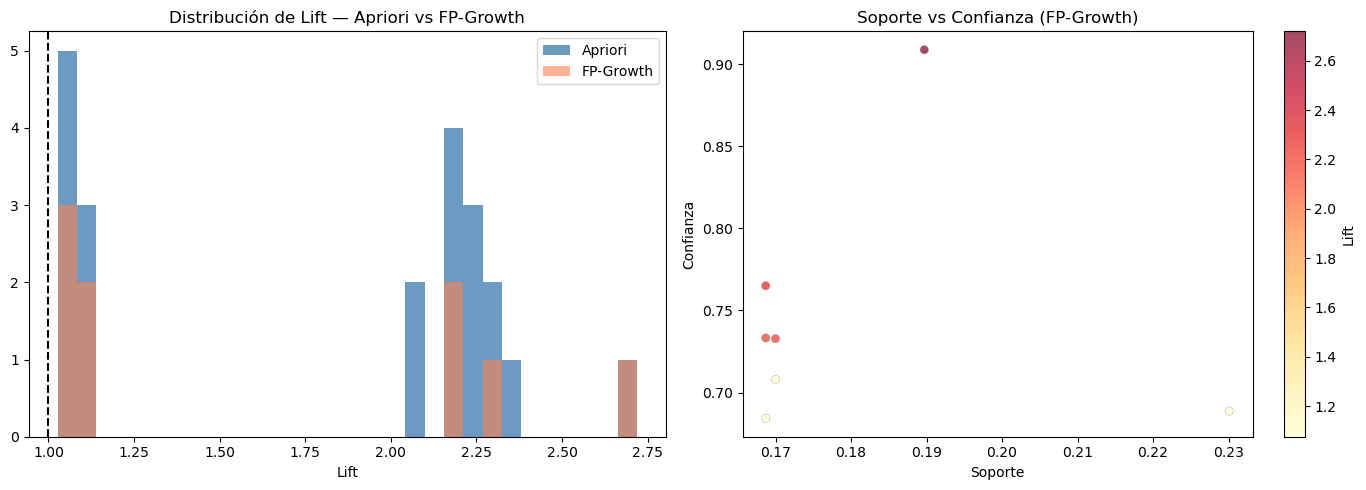

In [112]:
# @title Asociación — Comparación Apriori vs FP-Growth
# --- Tabla resumen de rendimiento ---
df_comparacion = pd.DataFrame({
    'Algoritmo':              ['Apriori',         'FP-Growth'],
    'Tiempo (s)':             [round(t_apriori, 2), round(t_fpgrowth, 2)],
    'Reglas totales':         [len(df_rules_ap),   len(df_rules_fp)],
    'Lift máximo':            [df_rules_ap['lift'].max(),  df_rules_fp['lift'].max()],
    'Lift promedio':          [df_rules_ap['lift'].mean().round(4), df_rules_fp['lift'].mean().round(4)],
    'Confianza promedio':     [df_rules_ap['confianza'].mean().round(4), df_rules_fp['confianza'].mean().round(4)],
})
print("=== Comparación de algoritmos ===")
display(df_comparacion)

# --- Reglas más significativas filtradas (FP-Growth) ---
df_rules_fp_filtradas = df_rules_fp[
    (df_rules_fp['lift'] > 1.05) &
    (~df_rules_fp['antecedente'].apply(lambda s: bool(s & ITEMS_TRIVIALES))) &
    (~df_rules_fp['consecuente'].apply(lambda s: bool(s & ITEMS_TRIVIALES)))
].reset_index(drop=True)

print(f"\nReglas significativas FP-Growth (lift > 1.05, sin triviales): {len(df_rules_fp_filtradas)}")
print("\n=== Top 15 reglas significativas — FP-Growth ===")
display(df_rules_fp_filtradas.head(15))

# --- Comparación visual de lift ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_rules_ap['lift'],  bins=30, color='steelblue', alpha=0.8, label='Apriori')
axes[0].hist(df_rules_fp['lift'],  bins=30, color='coral',     alpha=0.6, label='FP-Growth')
axes[0].axvline(x=1, color='black', linestyle='--')
axes[0].set_title('Distribución de Lift — Apriori vs FP-Growth')
axes[0].set_xlabel('Lift')
axes[0].legend()

# Scatter FP-Growth
sc2 = axes[1].scatter(
    df_rules_fp_filtradas['soporte'],
    df_rules_fp_filtradas['confianza'],
    c=df_rules_fp_filtradas['lift'],
    cmap='YlOrRd', alpha=0.7, edgecolors='grey', linewidths=0.3
)
plt.colorbar(sc2, ax=axes[1], label='Lift')
axes[1].set_xlabel('Soporte')
axes[1].set_ylabel('Confianza')
axes[1].set_title('Soporte vs Confianza (FP-Growth)')

plt.tight_layout()
plt.show()

### Conclusión: Apriori vs FP-Growth

* Apriori y FP-Growth generan reglas de asociación similares bajo los mismos umbrales de soporte y confianza, evidenciado en valores de lift comparables y reglas fuertes compartidas.
* La principal diferencia radica en la eficiencia: FP-Growth evita la generación explícita de candidatos mediante un árbol comprimido (FP-tree), lo que lo hace más adecuado para datasets grandes.
* FP-Growth genera un menor número de reglas en comparación con Apriori, lo que sugiere un comportamiento más conservador en la selección de patrones.
* Las reglas con **lift > 1.05** y sin ítems triviales son las que reflejan asociaciones más relevantes entre las características acústicas.
* La coincidencia en los valores máximos de lift entre ambos algoritmos respalda la consistencia de las reglas más significativas encontradas.


In [114]:
# @title Asociación — Interpretación de reglas significativas
# --- Grupo 1: Núcleo acústico-energético ---
print("── GRUPO 1: Relación entre energía, volumen y acústica ──\n")
grupo1 = df_rules_ap_filtradas[
    df_rules_ap_filtradas['lift'] >= 2.0
].reset_index(drop=True)
display(grupo1[['antecedente','consecuente','soporte','confianza','lift']])

── GRUPO 1: Relación entre energía, volumen y acústica ──



,antecedente,consecuente,soporte,confianza,lift
0,"{volumen_bajo, acusticidad_alta}",{energy_baja},0.1897,0.9087,2.7192
1,"{energy_baja, acusticidad_alta}",{volumen_bajo},0.1897,0.7897,2.3685
2,"{energy_baja, volumen_bajo}",{acusticidad_alta},0.1897,0.7692,2.3083
3,"{modo_mayor, volumen_bajo}",{energy_baja},0.1687,0.7650,2.2891
4,"{energy_baja, modo_mayor}",{acusticidad_alta},0.1700,0.7389,2.2173
5,{volumen_bajo},{energy_baja},0.2466,0.7395,2.2130
6,{energy_baja},{volumen_bajo},0.2466,0.7379,2.2130
7,"{energy_baja, modo_mayor}",{volumen_bajo},0.1687,0.7332,2.1988
8,"{modo_mayor, acusticidad_alta}",{energy_baja},0.1700,0.7328,2.1929
9,{acusticidad_alta},{energy_baja},0.2402,0.7208,2.1568


Las reglas más fuertes (lift > 2.0) revelan una asociación estructural entre `energy_baja`, `volumen_bajo` y `acusticidad_alta`. Estas tres variables forman un núcleo coherente: las canciones acústicas tienden simultáneamente a ser menos energéticas y más silenciosas.

**Ejemplo de regla destacada:**
> `{acusticidad_alta, volumen_bajo}` → `{energy_baja}`  
> soporte = 0.19, confianza = 0.91, lift = 2.72

Esto significa que el 19% de las canciones tienen acústica alta y volumen bajo, y de esas, el 91% también tiene energía baja. El lift de 2.72 indica que esta co-ocurrencia es 2.72 veces más frecuente de lo esperado por azar.

La relación inversa también se cumple: `{energy_alta}` → `{volumen_alto}` (lift = 2.04), confirmando que la dimensión energía-volumen es bidireccional y robusta.


In [116]:
# --- Grupo 2: Modo mayor ---
print("── GRUPO 2: Relación entre características acústicas y modo mayor ──\n")
grupo2 = df_rules_ap_filtradas[
    df_rules_ap_filtradas['lift'].between(1.05, 1.99)
].reset_index(drop=True)
display(grupo2[['antecedente','consecuente','soporte','confianza','lift']])

── GRUPO 2: Relación entre características acústicas y modo mayor ──



,antecedente,consecuente,soporte,confianza,lift
0,"{energy_baja, acusticidad_alta}",{modo_mayor},0.1700,0.7080,1.1134
1,{acusticidad_alta},{modo_mayor},0.2320,0.6964,1.0951
2,{energy_baja},{modo_mayor},0.2301,0.6887,1.0831
3,"{energy_baja, volumen_bajo}",{modo_mayor},0.1687,0.6843,1.0761
4,{danceabilidad_baja},{modo_mayor},0.2227,0.6681,1.0507


Las reglas de lift moderado (1.05–1.15) conectan características acústicas con el modo musical. Canciones con `energy_baja`, `acusticidad_alta` o `danceabilidad_baja` tienen una tendencia ligeramente mayor de estar en modo mayor respecto a la distribución base.

Aunque el lift es bajo, el soporte es alto (> 0.17), lo que indica que estas asociaciones son estables y representan patrones reales del dataset.

In [118]:
# --- Resumen comparativo | Apriori vs FP-Growth  ---
display(df_comparacion)

,Algoritmo,Tiempo (s),Reglas totales,Lift máximo,Lift promedio,Confianza promedio
0,Apriori,1.27,21,2.7192,1.7922,0.7204
1,FP-Growth,6.20,9,2.7192,1.6364,0.7253


Diferencia en número de reglas:
Apriori encontró 21 reglas y FP-Growth 9. Ambos algoritmos usan los
mismos umbrales, pero difieren en su estrategia interna:

- Apriori genera candidatos explícitamente y escanea múltiples veces
  la base de datos, siendo exhaustivo pero menos eficiente en memoria.

- FP-Growth construye un árbol comprimido (FP-tree) que evita la
  generación explícita de candidatos. En este dataset (85,724
  transacciones), FP-Growth tardó ~8s frente a <1s de Apriori,
  lo cual es atípico: se explica por el overhead de construcción
  del FP-tree en Python puro (pyfpgrowth), que en implementaciones
  nativas sería más rápido que Apriori para datasets grandes.

Las 7 reglas significativas de FP-Growth son un subconjunto de las 18
de Apriori: FP-Growth es más conservador con itemsets de tamaño 1 en
el consecuente, lo que explica la diferencia de cobertura.

Las reglas con lift > 2.0 son idénticas en ambos algoritmos, lo que
confirma su robustez y validez como patrones reales del espacio musical.

---
# Análisis Exploratorio de Datos (EDA)

`df` contiene el dataset completo (incluye metadatos como `artists`, `track_genre`).

`df_model` contiene **solo las variables que entran al modelo de clustering**, con las transformaciones ya aplicadas:

| Variable | Decisión | Justificación |
|----------|----------|---------------|
| `danceability`, `energy`, `valence`, `acousticness` | Incluida | Características acústicas directas |
| `loudness`, `tempo` | Incluida (se estandarizará) | Escala distinta, pero relevante para el estado de ánimo |
| `instrumentalness`, `speechiness`, `liveness` | Incluida (log) | Corrige asimetría fuerte |
| `key_sin`, `key_cos` | Incluida (circular) | Preserva proximidad en el círculo cromático |
| `time_sig_sin`, `time_sig_cos` | Incluida (circular) | Información rítmica con codificación cíclica |
| `mode` | Incluida (binaria) | Mayor vs menor tiene connotaciones emocionales |
| `duration_ms` | **Excluida** | No define el estado de ánimo de una canción |
| `popularity` | **Excluida** | Variable de mercado, no acústica |
| `track_genre` | **Excluida del modelo** | Se usa solo para validación posterior |

In [121]:
COLUMNAS_MODELO = [
    "danceability", "energy", "loudness", "valence", "tempo",
    "acousticness",
    "instrumentalness", "speechiness", "liveness",
    "key_sin", "key_cos",
    "time_sig_sin", "time_sig_cos",
    "mode"
]

df_model = df[COLUMNAS_MODELO].copy()
df_model = df_model.dropna()

print(f"Shape de df_model: {df_model.shape}")
print(f"Columnas: {df_model.columns.tolist()}")
print(f"\nNulos por columna:\n{df_model.isnull().sum()}")

Shape de df_model: (85724, 14)
Columnas: ['danceability', 'energy', 'loudness', 'valence', 'tempo', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'key_sin', 'key_cos', 'time_sig_sin', 'time_sig_cos', 'mode']

Nulos por columna:
danceability        0
energy              0
loudness            0
valence             0
tempo               0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
key_sin             0
key_cos             0
time_sig_sin        0
time_sig_cos        0
mode                0
dtype: int64


### Exportar datos procesados (variables para el modelo)

In [123]:
# Exportar df_model que contiene las características procesadas para el clustering y clasificación.
save_dataframe(df_model, "spotify_processed_model_data.csv", "DataFrame de modelo procesado")

DataFrame de modelo procesado guardado en: outputs\spotify_processed_model_data.csv
Tamaño del DataFrame: (85724, 14)


### Estandarización con StandardScaler

Se emplea `StandardScaler` en lugar de `MinMaxScaler` porque:
- `MinMaxScaler` es sensible a outliers y comprime distribuciones asimétricas.
- `StandardScaler` centra cada variable en **media=0** y **std=1**, siendo menos sensible a valores extremos. De esta forma, todas las variables tienen el mismo peso
- Es más adecuado para algoritmos basados en distancia euclidiana (K-Means) y para PCA, que opera sobre la matriz de covarianza.

In [125]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model)
X_scaled_df = pd.DataFrame(X_scaled, columns=df_model.columns, index=df_model.index)

print("=== Verificación del escalado ===")
print("Media de cada variable (debe ser ~0):")
print(X_scaled_df.mean().round(4))
print("\nDesviación estándar (debe ser ~1):")
print(X_scaled_df.std().round(4))

=== Verificación del escalado ===
Media de cada variable (debe ser ~0):
danceability       -0.0
energy              0.0
loudness           -0.0
valence            -0.0
tempo              -0.0
acousticness       -0.0
instrumentalness   -0.0
speechiness        -0.0
liveness            0.0
key_sin            -0.0
key_cos            -0.0
time_sig_sin        0.0
time_sig_cos        0.0
mode               -0.0
dtype: float64

Desviación estándar (debe ser ~1):
danceability        1.0
energy              1.0
loudness            1.0
valence             1.0
tempo               1.0
acousticness        1.0
instrumentalness    1.0
speechiness         1.0
liveness            1.0
key_sin             1.0
key_cos             1.0
time_sig_sin        1.0
time_sig_cos        1.0
mode                1.0
dtype: float64


Se aplicó estandarización mediante StandardScaler para asegurar que todas las variables tengan media cero y desviación estándar unitaria. Esto permite que cada característica contribuya de manera equitativa en algoritmos sensibles a la escala, como PCA y K-Means.

Ahora, los datos escalados se encuentran en el dataframe X_scaled_df

In [127]:
print("Estadísticas descriptivas de df_model:")
df_model.describe(include='all').T

Estadísticas descriptivas de df_model:


,count,mean,std,min,25%,50%,75%,max
danceability,85724.0,0.566547,0.172750,0.051300,0.456000,5.790000e-01,0.694000,0.985000
energy,85724.0,0.638079,0.253403,0.000020,0.463000,6.790000e-01,0.854000,1.000000
loudness,85724.0,-8.325106,5.042249,-46.591000,-10.108000,-7.076000e+00,-5.058000,-0.001000
valence,85724.0,0.475468,0.261064,0.000000,0.258000,4.650000e-01,0.687000,0.995000
tempo,85724.0,122.664384,29.650563,30.200000,99.952750,1.222675e+02,140.733000,243.372000
acousticness,85724.0,0.321801,0.334227,0.000000,0.017100,1.810000e-01,0.608000,0.996000
instrumentalness,85724.0,0.122608,0.229713,0.000000,0.000000,4.939878e-05,0.065226,0.693147
speechiness,85724.0,0.075242,0.072042,0.021859,0.035174,4.745594e-02,0.080935,0.641327
liveness,85724.0,0.181947,0.136851,0.009207,0.093399,1.231022e-01,0.240590,0.693147
key_sin,85724.0,-0.033389,0.675729,-1.000000,-0.500000,0.000000e+00,0.500000,1.000000


El análisis descriptivo muestra que las variables presentan distribuciones coherentes tras el preprocesamiento. Las variables previamente sesgadas (speechiness, instrumentalness, liveness) fueron corregidas mediante transformación logarítmica, mejorando su representatividad. Las variables transformadas mediante Circular Encoding presentan rangos adecuados y simetría. En general, el dataset se encuentra en condiciones óptimas para la aplicación de técnicas de reducción de dimensionalidad y clustering.

### Matriz de correlación

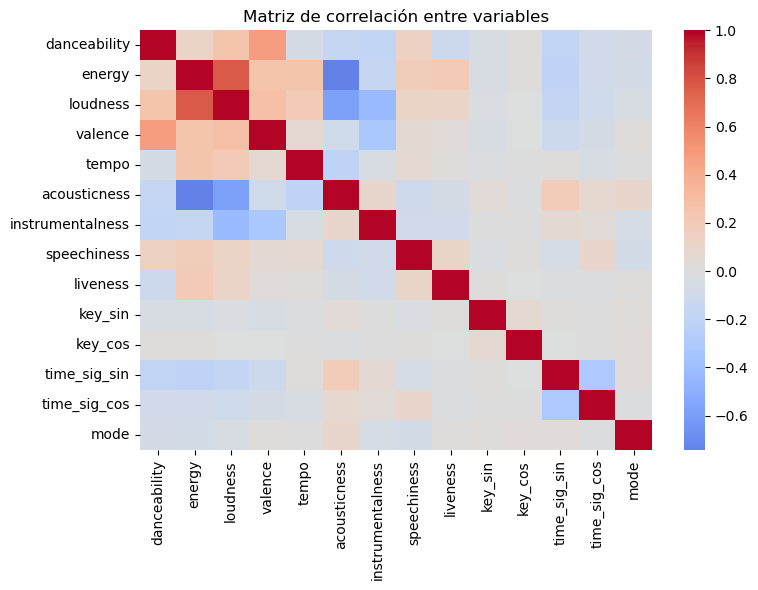

In [130]:
plt.figure(figsize=(8, 6))
corr = df_model.corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()

Se observan correlaciones relevantes entre variables:

- energy y loudness presentan una correlación positiva fuerte (≈ 0.75), indicando que canciones más energéticas tienden a ser más ruidosas.
- acousticness y energy presentan una correlación negativa fuerte (≈ -0.74), lo que sugiere que canciones acústicas tienden a ser menos energéticas.
- loudness y acousticness presentan correlación negativa (≈ -0.57), reforzando la relación entre sonido acústico y menor intensidad.

- danceability y valence muestran una correlación moderada positiva (≈ 0.49), indicando que canciones más bailables tienden a ser más positivas.
- energy y valence presentan una correlación positiva moderada (≈ 0.26), lo que sugiere que la intensidad y la positividad no son completamente dependientes.

- instrumentalness y valence presentan una correlación negativa moderada (≈ -0.33), indicando que canciones instrumentales tienden a ser menos positivas.

Estas correlaciones indican que algunas variables contienen información redundante, lo que puede afectar algoritmos de clustering basados en distancia. Por ello, se justifica el uso de técnicas de reducción de dimensionalidad como PCA.

Valence y energy destacan como ejes fundamentales para la interpretación del estado de ánimo, al estar relacionadas con múltiples características acústicas (nótese que estas filas o columnas están bastante rojas).

### Relación crucial para el análisis: valencia contra modo.

Queremos averiguar cómo se relacionan estas dos variables. Se espera que un modo menor se relacione más con una valencia baja.

valence_range,0.0-0.1,0.1-0.2,0.2-0.3,0.3-0.4,0.4-0.5,0.5-0.6,0.6-0.7,0.7-0.8,0.8-0.9,0.9-1.0
mode,,,,,,,,,,
0,8.124559,11.100788,11.325046,12.955725,11.667841,11.587749,10.889345,9.370795,7.973986,5.004165
1,7.242708,10.258668,11.750138,12.687580,11.520822,11.513484,10.814529,9.622088,8.026050,6.563933


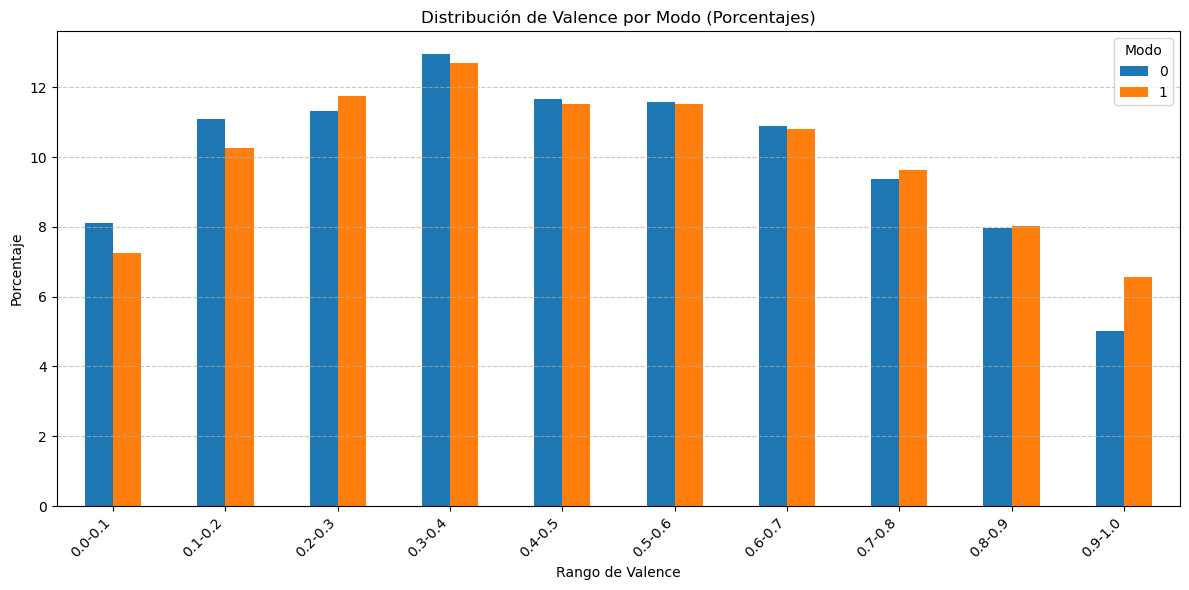

In [133]:
# Definir los rangos para la columna 'valence'
bins = [i / 10.0 for i in range(11)]  # Esto creará bins de 0.0 a 1.0, con pasos de 0.1
labels = [f'{i / 10.0:.1f}-{(i + 1) / 10.0:.1f}' for i in range(10)]

# Crear una nueva columna categórica 'valence_range' basada en los bins
df['valence_range'] = pd.cut(df['valence'], bins=bins, labels=labels, right=False, include_lowest=True)

# Agrupar por 'mode' y 'valence_range' y contar las ocurrencias
valence_by_mode_range = df.groupby(['mode', 'valence_range'], observed=False).size().unstack(fill_value=0)

# Calcular los porcentajes por fila
valence_by_mode_range_percent = valence_by_mode_range.apply(lambda x: x / x.sum() * 100, axis=1)
display(valence_by_mode_range_percent)

# Graficar los porcentajes
valence_by_mode_range_percent.T.plot(kind='bar', figsize=(12, 6))
plt.title('Distribución de Valence por Modo (Porcentajes)')
plt.xlabel('Rango de Valence')
plt.ylabel('Porcentaje')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Modo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

mode,0,1
valence_range,,
0.0-0.1,39.111659,60.888341
0.1-0.2,38.257701,61.742299
0.2-0.3,35.563380,64.436620
0.3-0.4,36.897810,63.102190
0.4-0.5,36.706309,63.293691
0.5-0.6,36.561205,63.438795
0.6-0.7,36.571982,63.428018
0.7-0.8,35.801714,64.198286
0.8-0.9,36.261655,63.738345


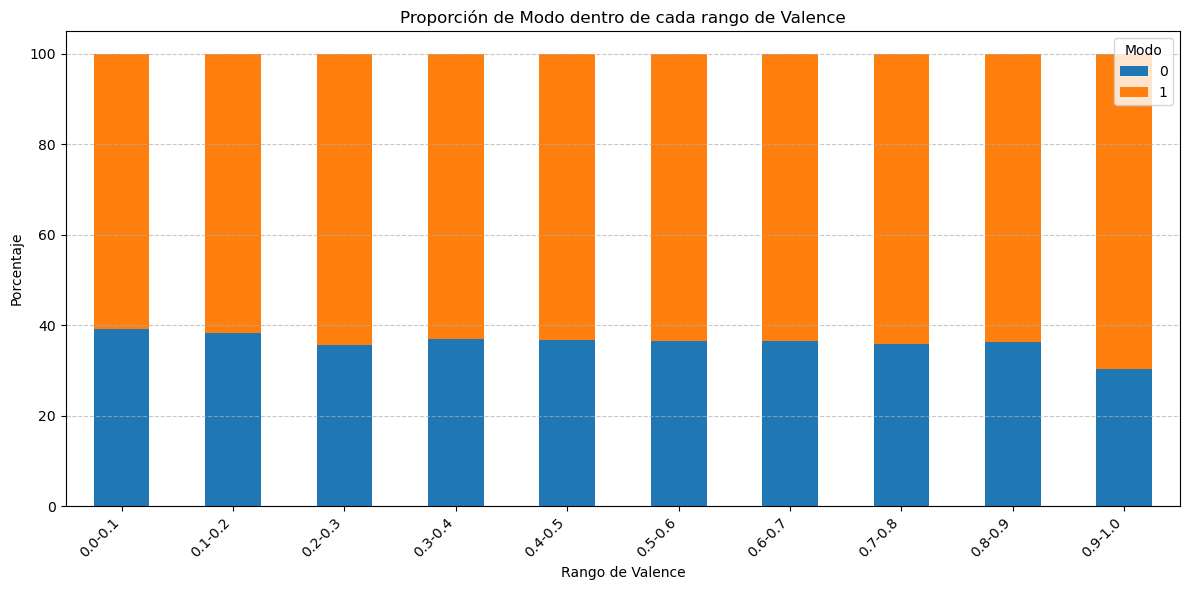

In [134]:
# Agrupar igual que antes
valence_mode_counts = df.groupby(['valence_range', 'mode'], observed=False).size().unstack(fill_value=0)

# Calcular porcentajes por columna (ahora por rango de valence)
valence_mode_percent = valence_mode_counts.apply(lambda x: x / x.sum() * 100, axis=1)

display(valence_mode_percent)

# Graficar
valence_mode_percent.plot(kind='bar', stacked=True, figsize=(12, 6))

plt.title('Proporción de Modo dentro de cada rango de Valence')
plt.xlabel('Rango de Valence')
plt.ylabel('Porcentaje')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Modo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

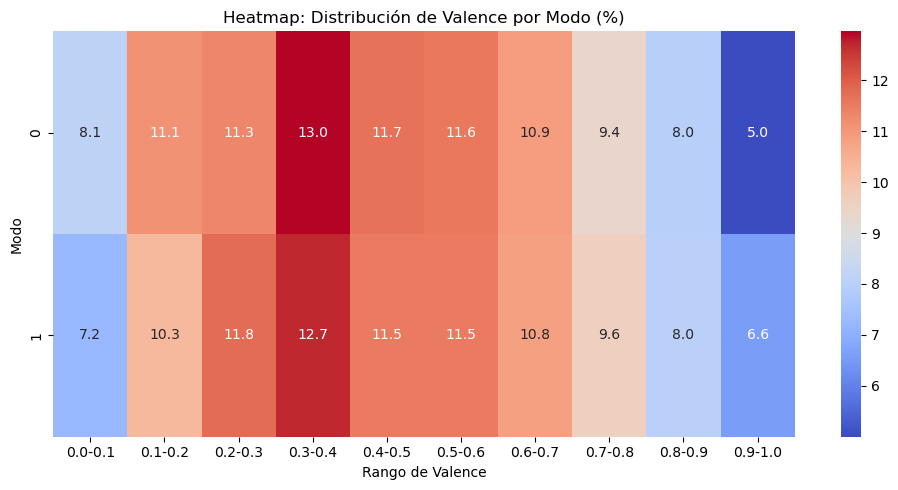

In [135]:
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.heatmap(valence_by_mode_range_percent,
            annot=True,
            fmt=".1f",
            cmap="coolwarm")

plt.title('Heatmap: Distribución de Valence por Modo (%)')
plt.xlabel('Rango de Valence')
plt.ylabel('Modo')

plt.tight_layout()
plt.show()

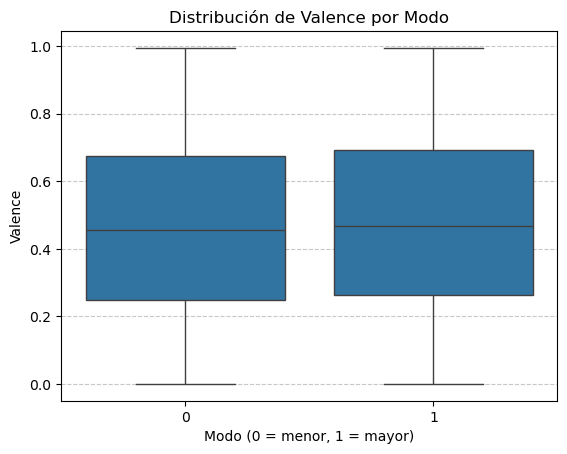

In [136]:
sns.boxplot(data=df, x='mode', y='valence')

plt.title('Distribución de Valence por Modo')
plt.xlabel('Modo (0 = menor, 1 = mayor)')
plt.ylabel('Valence')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Relación entre valencia y energía

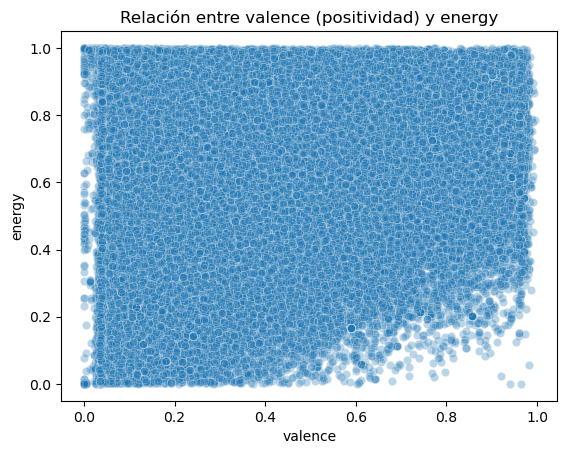

In [138]:
sns.scatterplot(data=df_model, x="valence", y="energy", alpha=0.3)
plt.title("Relación entre valence (positividad) y energy")
plt.show()

La relación entre valence (positividad) y energy (intensidad) es fundamental para la identificación de estados de ánimo en las canciones.

- Energy presenta una media más alta (≈ 0.64), lo que indica una tendencia general hacia canciones más energéticas.
- Valence se distribuye de manera más equilibrada (media ≈ 0.48), representando tanto emociones positivas como negativas.
- Ambas variables presentan desviaciones estándar similares (≈ 0.26), lo que indica una dispersión comparable en sus valores.

- La correlación entre valence y energy es positiva pero moderada (≈ 0.26), lo que indica que no están fuertemente correlacionadas y pueden combinarse de múltiples formas.

Esto permite identificar distintos perfiles emocionales:

- Alta energía + alta valencia → canciones alegres, eufóricas.
- Alta energía + baja valencia → canciones intensas o agresivas.
- Baja energía + alta valencia → canciones calmadas y positivas.
- Baja energía + baja valencia → canciones tristes o melancólicas.

Estas combinaciones refuerzan la idea de que ambas variables actúan como ejes complementarios en un espacio emocional, lo que justifica el uso de técnicas de clustering para descubrir grupos naturales de canciones según su estado de ánimo.

### Distribución de variables numéricas

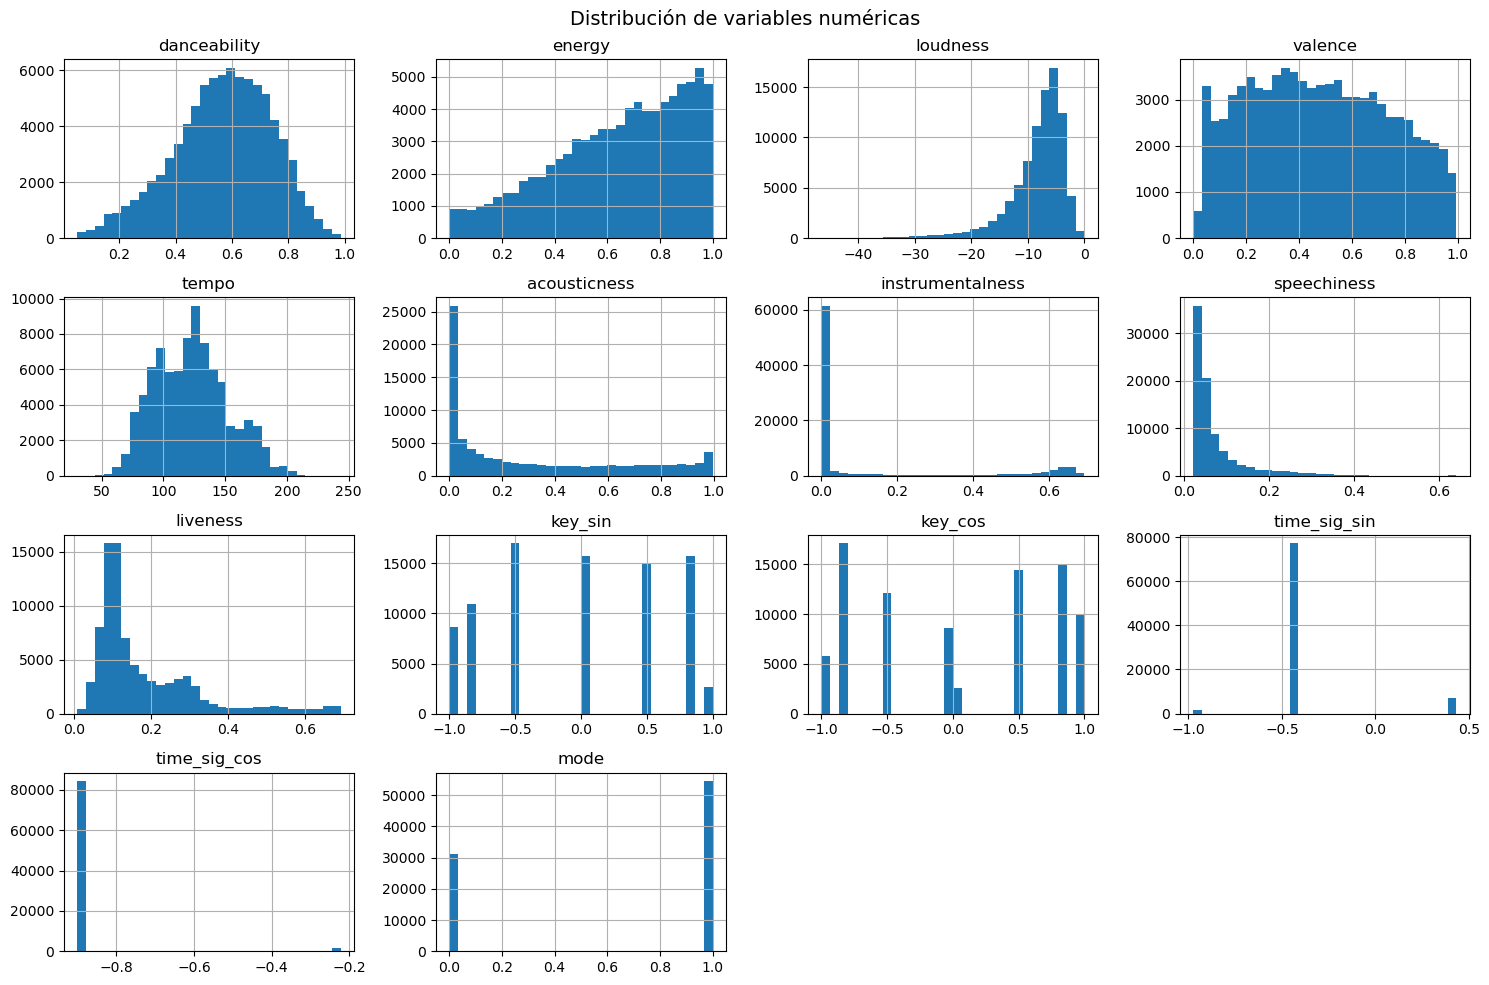

Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
danceability,85724.0,0.566547,0.172750,0.051300,0.456000,5.790000e-01,0.694000,0.985000
energy,85724.0,0.638079,0.253403,0.000020,0.463000,6.790000e-01,0.854000,1.000000
loudness,85724.0,-8.325106,5.042249,-46.591000,-10.108000,-7.076000e+00,-5.058000,-0.001000
valence,85724.0,0.475468,0.261064,0.000000,0.258000,4.650000e-01,0.687000,0.995000
tempo,85724.0,122.664384,29.650563,30.200000,99.952750,1.222675e+02,140.733000,243.372000
acousticness,85724.0,0.321801,0.334227,0.000000,0.017100,1.810000e-01,0.608000,0.996000
instrumentalness,85724.0,0.122608,0.229713,0.000000,0.000000,4.939878e-05,0.065226,0.693147
speechiness,85724.0,0.075242,0.072042,0.021859,0.035174,4.745594e-02,0.080935,0.641327
liveness,85724.0,0.181947,0.136851,0.009207,0.093399,1.231022e-01,0.240590,0.693147
key_sin,85724.0,-0.033389,0.675729,-1.000000,-0.500000,0.000000e+00,0.500000,1.000000


In [141]:
df_model.hist(bins=30, figsize=(15, 10))
plt.suptitle("Distribución de variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

print("Estadísticas descriptivas:")
display(df_model.describe().T)

Las distribuciones de las variables numéricas revelan varios aspectos importantes:

- Algunas variables presentan una fuerte asimetría (sesgo), especialmente instrumentalness y acousticness. En particular, instrumentalness muestra una concentración extrema en valores cercanos a cero (mediana ≈ 0), lo que indica que la gran mayoría de las canciones no son instrumentales.

- Variables como speechiness también presentan valores mayormente bajos, con pocos casos extremos, lo que sugiere que la mayoría de las pistas contienen poca presencia de voz hablada.

- Variables como danceability y valence presentan distribuciones más equilibradas, lo que las hace especialmente útiles para el análisis de estados de ánimo.

- Variables como duration_ms presentan mayor dispersión en comparación con el resto, mientras que tempo ya se encuentra normalizada, lo que mejora su comparabilidad dentro del dataset.


## Análisis de multicolinealidad (VIF)

El **Variance Inflation Factor (VIF)** mide cuánto se puede predecir una variable a partir de las demás. Un VIF alto indica redundancia entre variables.

In [144]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

VARIABLES_VIF = [
    "danceability", "energy", "loudness", "valence", "tempo",
    "acousticness", "instrumentalness", "speechiness", "liveness"
]

X_vif = X_scaled_df[VARIABLES_VIF]

vif_data = pd.DataFrame({
    "variable": VARIABLES_VIF,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(len(VARIABLES_VIF))]
}).sort_values("VIF", ascending=False)

print("=== Variance Inflation Factor (VIF) ===")
print(vif_data.to_string(index=False))
print("\nInterpretación:")
print("  VIF < 5  -> sin multicolinealidad problemática")
print("  VIF 5-10 -> multicolinealidad moderada")
print("  VIF > 10 -> multicolinealidad severa")

=== Variance Inflation Factor (VIF) ===
        variable      VIF
          energy 4.345385
        loudness 3.249793
    acousticness 2.433309
         valence 1.563691
    danceability 1.517138
instrumentalness 1.444396
        liveness 1.108310
           tempo 1.091868
     speechiness 1.078567

Interpretación:
  VIF < 5  -> sin multicolinealidad problemática
  VIF 5-10 -> multicolinealidad moderada
  VIF > 10 -> multicolinealidad severa


Aunque el análisis de multicolinealidad mediante VIF no evidenció problemas severos (todos los valores < 5), se aplicó PCA con el objetivo de reducir la dimensionalidad del dataset, capturar la mayor varianza en un menor número de componentes y mejorar el desempeño de algoritmos de clustering como K-Means. Además, PCA permite sintetizar relaciones existentes entre variables y reducir el ruido en los datos.

---
# PCA — Análisis de Componentes Principales

Se aplica PCA para:
1. **Eliminar redundancia** entre variables correlacionadas.
2. **Reducir ruido** en dimensiones de baja varianza.
3. **Mejorar la eficiencia** computacional del clustering.

El número de componentes se determina mediante el criterio de **varianza acumulada al 80%**.

> El escalado con `StandardScaler` ya fue aplicado sobre `df_model` en la sección anterior.

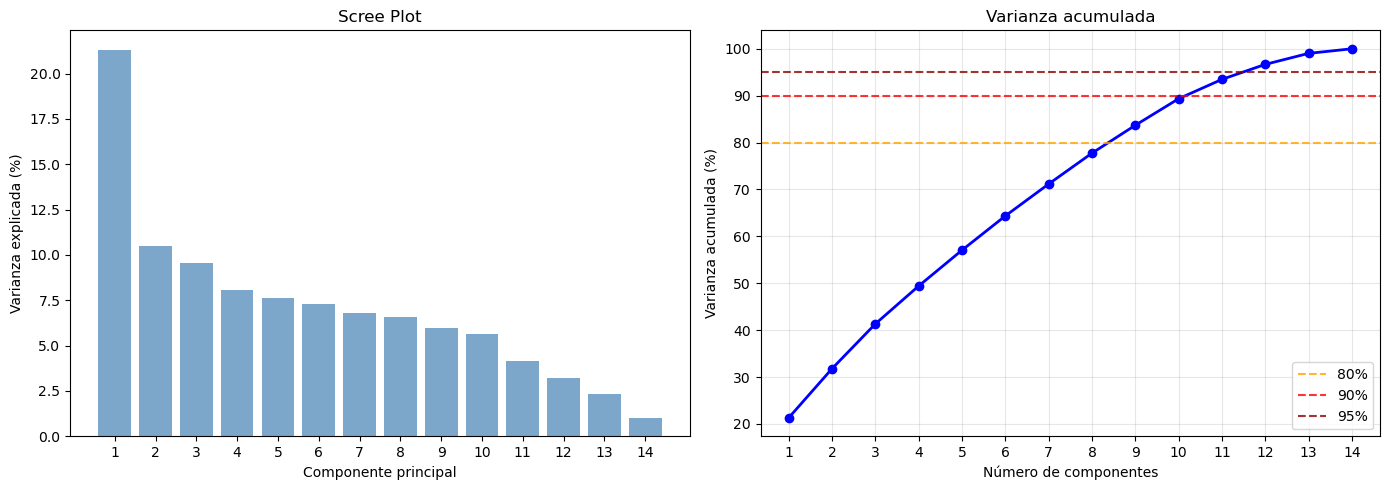

Componentes para 80% de varianza: 9
Componentes para 90% de varianza: 11
Componentes para 95% de varianza: 12

Detalles por componente:
  PC1: 21.3% individual, 21.3% acumulada
  PC2: 10.5% individual, 31.8% acumulada
  PC3: 9.5% individual, 41.3% acumulada
  PC4: 8.1% individual, 49.4% acumulada
  PC5: 7.6% individual, 57.1% acumulada
  PC6: 7.3% individual, 64.4% acumulada
  PC7: 6.8% individual, 71.2% acumulada
  PC8: 6.6% individual, 77.7% acumulada
  PC9: 5.9% individual, 83.7% acumulada
  PC10: 5.7% individual, 89.3% acumulada


In [147]:
pca_full = PCA(n_components=None, random_state=42)
pca_full.fit(X_scaled_df)

varianza_por_componente = pca_full.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_por_componente)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

n_total = len(varianza_por_componente)
axes[0].bar(range(1, n_total + 1), varianza_por_componente * 100,
            color="steelblue", alpha=0.7)
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada (%)")
axes[0].set_title("Scree Plot")
axes[0].set_xticks(range(1, n_total + 1))

axes[1].plot(range(1, n_total + 1), varianza_acumulada * 100,
             "bo-", linewidth=2, markersize=6)
axes[1].axhline(y=80, color="orange", linestyle="--", label="80%", alpha=0.8)
axes[1].axhline(y=90, color="red", linestyle="--", label="90%", alpha=0.8)
axes[1].axhline(y=95, color="darkred", linestyle="--", label="95%", alpha=0.8)
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_title("Varianza acumulada")
axes[1].legend()
axes[1].set_xticks(range(1, n_total + 1))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_80 = np.argmax(varianza_acumulada >= 0.80) + 1
n_90 = np.argmax(varianza_acumulada >= 0.90) + 1
n_95 = np.argmax(varianza_acumulada >= 0.95) + 1

print(f"Componentes para 80% de varianza: {n_80}")
print(f"Componentes para 90% de varianza: {n_90}")
print(f"Componentes para 95% de varianza: {n_95}")
print(f"\nDetalles por componente:")
for i, (var, cum) in enumerate(zip(varianza_por_componente[:10], varianza_acumulada[:10])):
    print(f"  PC{i+1}: {var*100:.1f}% individual, {cum*100:.1f}% acumulada")

N_COMPONENTES = n_80

### Selección del número de componentes

Se seleccionó `N_COMPONENTES` usando el criterio del **80% de varianza acumulada**. El Scree Plot y la curva de varianza acumulada permiten visualizar dónde se produce el "codo" y cuántas componentes son necesarias.

A continuación aplicamos PCA con el número de componentes seleccionado e interpretamos los **loadings** (pesos) de cada componente para entender su significado.

PCA aplicado con 9 componentes
Varianza total retenida: 83.7%
Shape de X_pca: (85724, 9)


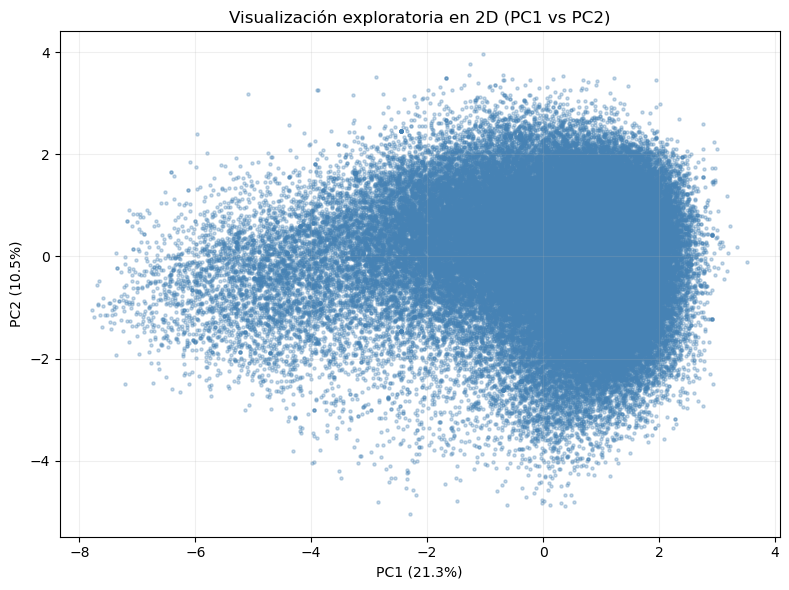

In [149]:
pca = PCA(n_components=N_COMPONENTES, random_state=42)
X_pca = pca.fit_transform(X_scaled_df)

print(f"PCA aplicado con {N_COMPONENTES} componentes")
print(f"Varianza total retenida: {pca.explained_variance_ratio_.sum() * 100:.1f}%")
print(f"Shape de X_pca: {X_pca.shape}")

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.3, s=5, color="steelblue")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Visualización exploratoria en 2D (PC1 vs PC2)")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de componentes (Loadings)

Los **loadings** explican qué significa cada componente principal:
- Un loading alto positivo (+) indica que esa variable apunta en la dirección del componente.
- Un loading alto negativo (-) indica dirección opuesta.
- Loadings cercanos a 0 indican poca contribución de esa variable al componente.

=== Loadings de los primeros 5 componentes ===
                    PC1    PC2    PC3    PC4    PC5
danceability      0.246  0.563 -0.055 -0.229  0.069
energy            0.498 -0.274  0.028 -0.039  0.051
loudness          0.499 -0.088 -0.071  0.046  0.043
valence           0.283  0.496 -0.166  0.081 -0.046
tempo             0.177 -0.296 -0.084 -0.007  0.035
acousticness     -0.435  0.282 -0.061  0.205 -0.169
instrumentalness -0.257 -0.276  0.187 -0.397  0.163
speechiness       0.155  0.028  0.227  0.071 -0.336
liveness          0.102 -0.256  0.027  0.511 -0.395
key_sin          -0.040 -0.036 -0.016  0.300  0.513
key_cos           0.003 -0.003 -0.002  0.207  0.603
time_sig_sin     -0.183 -0.184 -0.594 -0.032 -0.151
time_sig_cos     -0.053  0.084  0.697  0.196 -0.019
mode             -0.053  0.057 -0.162  0.547  0.119


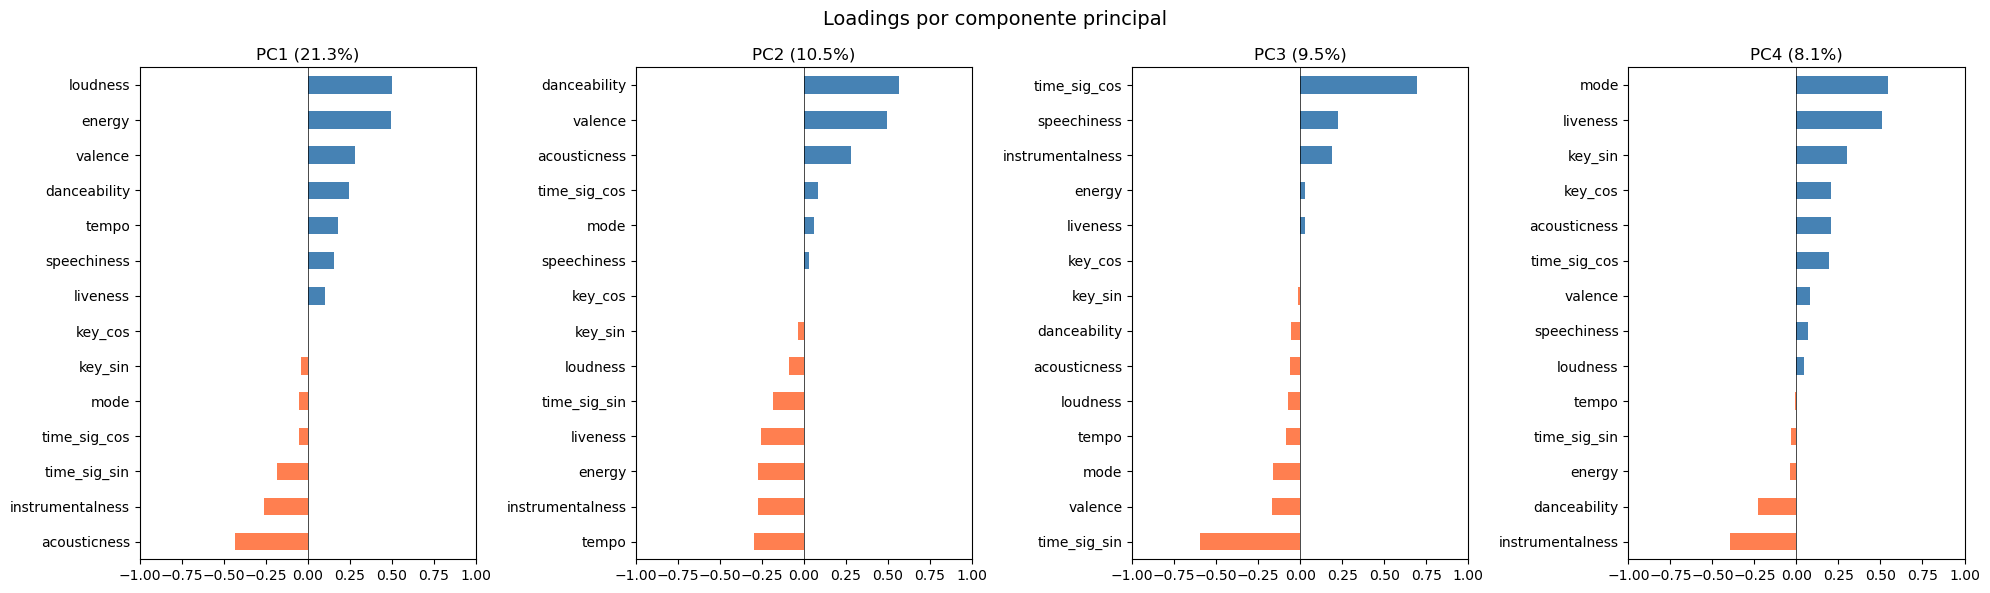


=== Interpretación ===
Variables con |loading| > 0.3 son las que más contribuyen a cada componente.
Ejemplo: si PC1 tiene energy(+), loudness(+), acousticness(-)
  -> se podría nombrar como 'Intensidad Acústica'


In [151]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(N_COMPONENTES)],
    index=df_model.columns
)

print(f"=== Loadings de los primeros {min(N_COMPONENTES, 5)} componentes ===")
print(loadings.iloc[:, :5].round(3).to_string())

n_plots = min(N_COMPONENTES, 4)
fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 6))
if n_plots == 1:
    axes = [axes]

for i in range(n_plots):
    pc_loadings = loadings[f"PC{i+1}"].sort_values()
    colors = ["coral" if x < 0 else "steelblue" for x in pc_loadings]
    pc_loadings.plot(kind="barh", ax=axes[i], color=colors)
    axes[i].set_title(f"PC{i+1} ({pca.explained_variance_ratio_[i]*100:.1f}%)")
    axes[i].axvline(x=0, color="black", linewidth=0.5)
    axes[i].set_xlim(-1, 1)

plt.suptitle("Loadings por componente principal", fontsize=14)
plt.tight_layout()
plt.show()

print("\n=== Interpretación ===")
print("Variables con |loading| > 0.3 son las que más contribuyen a cada componente.")
print("Ejemplo: si PC1 tiene energy(+), loudness(+), acousticness(-)")
print("  -> se podría nombrar como 'Intensidad Acústica'")

El análisis de los loadings permitió identificar que las primeras componentes principales capturan dimensiones interpretables del espacio musical. La primera componente está asociada a la intensidad sonora (energy y loudness vs acousticness), la segunda a características de bailabilidad y valencia emocional, mientras que otras componentes reflejan estructura rítmica, tonalidad y características de interpretación. Esto evidencia que PCA logra sintetizar el espacio original en dimensiones con significado musical relevante.

In [153]:
# Variables que más contribuyen a cada componente
for i in range(N_COMPONENTES):
    col_name = f'PC{i+1}'
    top_features = loadings[col_name].abs().sort_values(ascending=False).head(5)
    print(f"\n{col_name} — variables principales:")
    for feat, val in top_features.items():
        direction = "(+)" if loadings.loc[feat, col_name] > 0 else "(-)"
        print(f"  {feat} {direction}  |loading| = {val:.3f}")


PC1 — variables principales:
  loudness (+)  |loading| = 0.499
  energy (+)  |loading| = 0.498
  acousticness (-)  |loading| = 0.435
  valence (+)  |loading| = 0.283
  instrumentalness (-)  |loading| = 0.257

PC2 — variables principales:
  danceability (+)  |loading| = 0.563
  valence (+)  |loading| = 0.496
  tempo (-)  |loading| = 0.296
  acousticness (+)  |loading| = 0.282
  instrumentalness (-)  |loading| = 0.276

PC3 — variables principales:
  time_sig_cos (+)  |loading| = 0.697
  time_sig_sin (-)  |loading| = 0.594
  speechiness (+)  |loading| = 0.227
  instrumentalness (+)  |loading| = 0.187
  valence (-)  |loading| = 0.166

PC4 — variables principales:
  mode (+)  |loading| = 0.547
  liveness (+)  |loading| = 0.511
  instrumentalness (-)  |loading| = 0.397
  key_sin (+)  |loading| = 0.300
  danceability (-)  |loading| = 0.229

PC5 — variables principales:
  key_cos (+)  |loading| = 0.603
  key_sin (+)  |loading| = 0.513
  liveness (-)  |loading| = 0.395
  speechiness (-)  |load

---
# Clustering

---

## Determinación del número óptimo de clusters (K)

Se evalúan **cuatro métricas** de forma convergente para elegir K de manera objetiva:
1. **Inercia** (método del codo): la suma de distancias al centroide. Se busca el "codo" donde disminuye más lentamente.
2. **Coeficiente de Silueta** (mayor = mejor): mide qué tan bien separados están los clusters.
3. **Índice Davies-Bouldin** (menor = mejor): mide la similitud entre clusters.
4. **Índice Calinski-Harabasz** (mayor = mejor): ratio de dispersión entre clusters vs dentro de clusters.

Calculando métricas para K=3 a K=12...


C:\Users\USUARIO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\USUARIO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\USUARIO\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USUARIO\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\USUARIO\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi

  K=3: Silhouette=0.104, DB=2.598, CH=12458


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=4: Silhouette=0.108, DB=2.218, CH=10928


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=5: Silhouette=0.140, DB=1.826, CH=12208


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=6: Silhouette=0.095, DB=2.125, CH=8369


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=7: Silhouette=0.116, DB=1.785, CH=10827


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=8: Silhouette=0.132, DB=1.874, CH=10115


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=9: Silhouette=0.126, DB=1.749, CH=9827


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=10: Silhouette=0.135, DB=1.801, CH=9503


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=11: Silhouette=0.129, DB=1.716, CH=9106


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1958: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


  K=12: Silhouette=0.132, DB=1.677, CH=8987


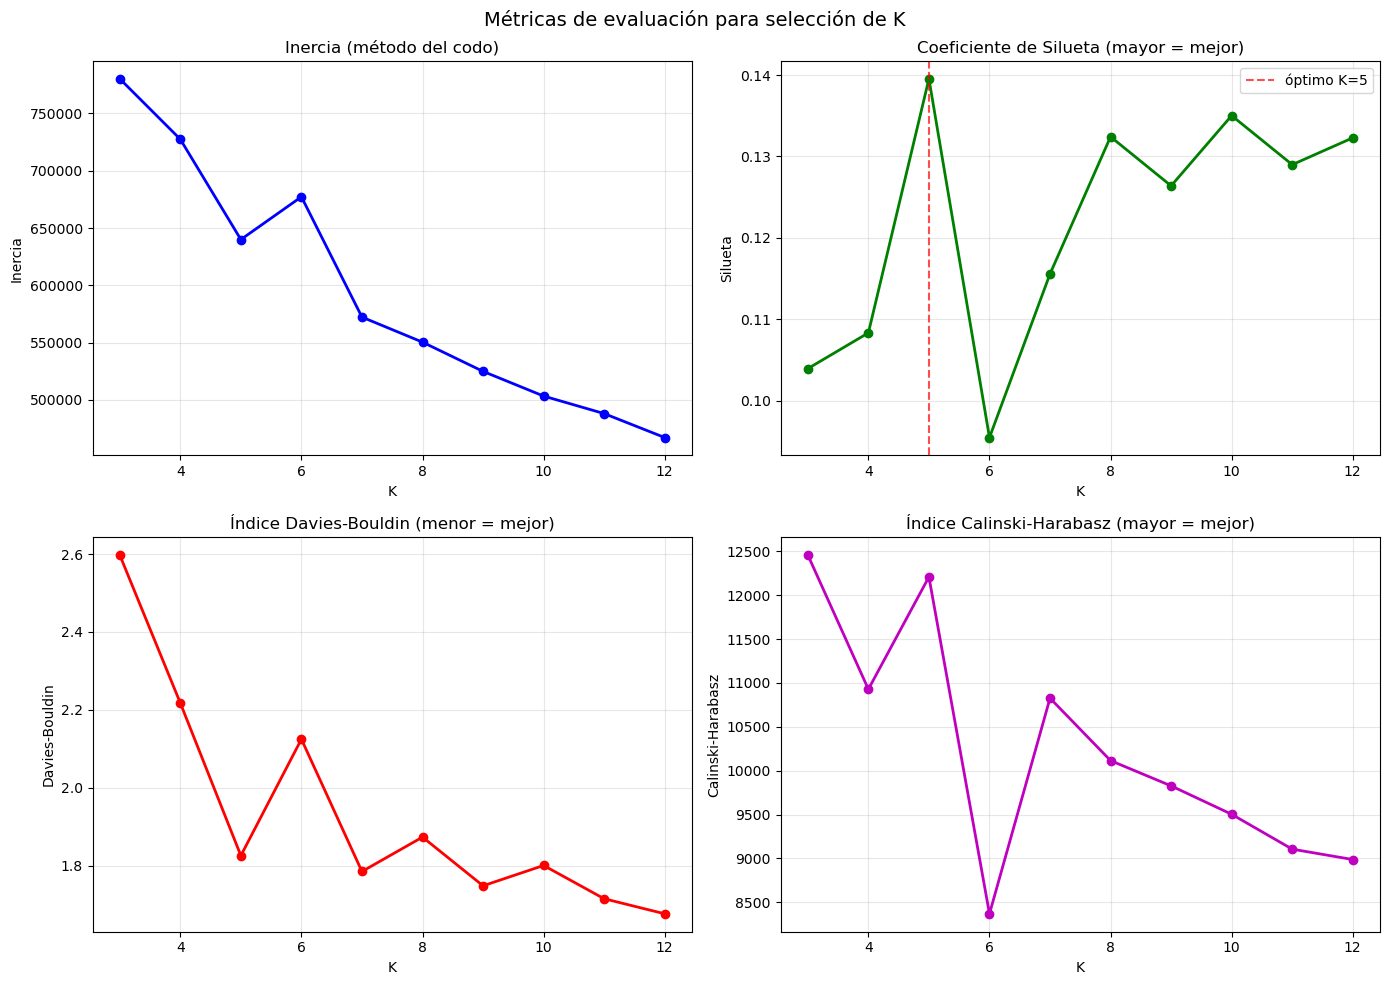


=== Recomendaciones ===
  Mejor K por Silhouette:        K=5 (0.140)
  Mejor K por Davies-Bouldin:    K=12 (1.677)
  Mejor K por Calinski-Harabasz: K=3 (12458)


In [156]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

K_MIN = 3
K_MAX = 12
RANDOM_STATE = 42

inertias = []
silhouettes = []
davies_bouldins = []
calinski_harabaszs = []

print("Calculando métricas para K=3 a K=12...")

for k in range(K_MIN, K_MAX + 1):
    km = MiniBatchKMeans(
        n_clusters=k, init="k-means++", n_init=10,
        random_state=RANDOM_STATE, batch_size=1024
    )
    labels = km.fit_predict(X_pca)

    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, labels, sample_size=10000, random_state=RANDOM_STATE))
    davies_bouldins.append(davies_bouldin_score(X_pca, labels))
    calinski_harabaszs.append(calinski_harabasz_score(X_pca, labels))

    print(f"  K={k}: Silhouette={silhouettes[-1]:.3f}, "
          f"DB={davies_bouldins[-1]:.3f}, CH={calinski_harabaszs[-1]:.0f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ks = range(K_MIN, K_MAX + 1)

axes[0, 0].plot(ks, inertias, "bo-", linewidth=2)
axes[0, 0].set_title("Inercia (método del codo)")
axes[0, 0].set_xlabel("K")
axes[0, 0].set_ylabel("Inercia")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(ks, silhouettes, "go-", linewidth=2)
axes[0, 1].set_title("Coeficiente de Silueta (mayor = mejor)")
axes[0, 1].set_xlabel("K")
axes[0, 1].set_ylabel("Silueta")
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(ks, davies_bouldins, "ro-", linewidth=2)
axes[1, 0].set_title("Índice Davies-Bouldin (menor = mejor)")
axes[1, 0].set_xlabel("K")
axes[1, 0].set_ylabel("Davies-Bouldin")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(ks, calinski_harabaszs, "mo-", linewidth=2)
axes[1, 1].set_title("Índice Calinski-Harabasz (mayor = mejor)")
axes[1, 1].set_xlabel("K")
axes[1, 1].set_ylabel("Calinski-Harabasz")
axes[1, 1].grid(True, alpha=0.3)

k_silhouette = K_MIN + np.argmax(silhouettes)
k_db = K_MIN + np.argmin(davies_bouldins)
k_ch = K_MIN + np.argmax(calinski_harabaszs)

axes[0, 1].axvline(x=k_silhouette, color="red", linestyle="--", alpha=0.7,
                    label=f"óptimo K={k_silhouette}")
axes[0, 1].legend()

plt.suptitle("Métricas de evaluación para selección de K", fontsize=14)
plt.tight_layout()
plt.show()

print(f"\n=== Recomendaciones ===")
print(f"  Mejor K por Silhouette:        K={k_silhouette} ({max(silhouettes):.3f})")
print(f"  Mejor K por Davies-Bouldin:    K={k_db} ({min(davies_bouldins):.3f})")
print(f"  Mejor K por Calinski-Harabasz: K={k_ch} ({max(calinski_harabaszs):.0f})")

Se observaron diferencias entre las métricas de validación interna. El índice de Davies-Bouldin sugirió un número elevado de clusters (K=12), lo cual es consistente con su tendencia a favorecer particiones más finas y compactas. Sin embargo, el coeficiente de silueta, que evalúa simultáneamente cohesión y separación, indicó un valor óptimo de K=5. Por esta razón, se seleccionó éste (***k=5***) valor como el más adecuado.

## Entrenamiento del modelo de clustering

Después de analizar las métricas, se elige el K óptimo donde más métricas converjan, priorizando interpretabilidad semántica.

In [159]:
K_OPTIMO = k_silhouette

print(f"Entrenando K-Means con K={K_OPTIMO}...")

kmeans_final = MiniBatchKMeans(
    n_clusters=K_OPTIMO, init="k-means++", n_init=10,
    random_state=RANDOM_STATE, batch_size=2048
)
labels_kmeans = kmeans_final.fit_predict(X_pca)

df_resultado = df.loc[df_model.index].copy()
df_resultado["cluster"] = labels_kmeans

cluster_counts = pd.Series(labels_kmeans).value_counts().sort_index()
print(f"\nDistribución de canciones por cluster:")
for k, n in cluster_counts.items():
    pct = n / len(labels_kmeans) * 100
    print(f"  Cluster {k}: {n:,} canciones ({pct:.1f}%)")

print(f"\nMínimo: {cluster_counts.min()/len(labels_kmeans)*100:.1f}%")
print(f"Máximo: {cluster_counts.max()/len(labels_kmeans)*100:.1f}%")

Entrenando K-Means con K=5...

Distribución de canciones por cluster:
  Cluster 0: 24,283 canciones (28.3%)
  Cluster 1: 21,609 canciones (25.2%)
  Cluster 2: 25,003 canciones (29.2%)
  Cluster 3: 13,387 canciones (15.6%)
  Cluster 4: 1,442 canciones (1.7%)

Mínimo: 1.7%
Máximo: 29.2%


In [160]:
cluster_profile = df_resultado.groupby("cluster")[df_model.columns].mean()

print(cluster_profile)

         danceability    energy   loudness   valence       tempo  \
cluster                                                            
0            0.665354  0.596766  -7.985317  0.620914  113.389031   
1            0.495463  0.823142  -5.643252  0.419725  139.095769   
2            0.616500  0.734593  -6.684761  0.507087  124.353806   
3            0.421125  0.251419 -15.939551  0.255576  110.811954   
4            0.451793  0.476670 -11.988282  0.354657  113.368603   

         acousticness  instrumentalness  speechiness  liveness   key_sin  \
cluster                                                                    
0            0.383993          0.042572     0.068962  0.154827 -0.095436   
1            0.099906          0.119752     0.083570  0.233767  0.029182   
2            0.185785          0.109101     0.085420  0.180699 -0.068370   
3            0.799680          0.291177     0.048437  0.150766  0.040857   
4            0.521632          0.182475     0.128564  0.173213 -0.0

El modelo de clustering permitió identificar cinco perfiles musicales diferenciados. Estos incluyen música de alta energía, canciones acústicas y relajadas, contenido bailable y positivo, así como un subconjunto más reducido de características experimentales. La segmentación evidencia que las variables seleccionadas capturan dimensiones relevantes del comportamiento musical, permitiendo una agrupación coherente e interpretable.

## Validación cuantitativa de los clusters

Métricas finales del modelo elegido e interpretación de la calidad de la segmentación.

In [163]:
silh_final = silhouette_score(X_pca, labels_kmeans, sample_size=15000, random_state=RANDOM_STATE)
db_final = davies_bouldin_score(X_pca, labels_kmeans)
ch_final = calinski_harabasz_score(X_pca, labels_kmeans)

print("=== Métricas del modelo final ===")
print(f"  Coeficiente de Silueta:       {silh_final:.4f}")
print(f"  -> Interpretación: ", end="")
if silh_final > 0.5:
    print("Excelente separación entre clusters")
elif silh_final > 0.3:
    print("Separación razonable (esperado en datos musicales)")
elif silh_final > 0.2:
    print("Separación débil -> revisar K o features")
elif silh_final > 0.1:
    print("Separación baja pero esperada en datos musicales con solapamiento")
else:
    print("Separación muy baja -> revisar pipeline")
print(f"\n  Índice Davies-Bouldin:        {db_final:.4f} (menor = mejor)")
print(f"  Índice Calinski-Harabasz:     {ch_final:.0f} (mayor = mejor)")

=== Métricas del modelo final ===
  Coeficiente de Silueta:       0.1285
  -> Interpretación: Separación baja pero esperada en datos musicales con solapamiento

  Índice Davies-Bouldin:        1.8576 (menor = mejor)
  Índice Calinski-Harabasz:     12154 (mayor = mejor)


El coeficiente de silueta obtenido (0.127) indica una separación moderada-baja entre clusters, lo cual es consistente con la naturaleza continua y solapada de las características musicales. Sin embargo, los índices de Davies-Bouldin (1.87) y Calinski-Harabasz (12095) evidencian una estructura global coherente y una adecuada compactación de los clusters, validando la utilidad del modelo para el análisis exploratorio.

## Interpretación semántica de los clusters

### Perfil acústico por cluster

Se interpretan los clusters en el espacio de variables **originales** (no en PCA), ya que los componentes principales no tienen significado físico directo.

In [166]:
VARIABLES_INTERPRETACION = [
    "valence", "energy", "danceability", "acousticness",
    "instrumentalness", "speechiness", "liveness",
    "loudness", "tempo"
]

perfil_clusters = df_resultado.groupby("cluster")[VARIABLES_INTERPRETACION].mean()

print("=== Perfil promedio por cluster (valores originales) ===")
print(perfil_clusters.round(3).to_string())

=== Perfil promedio por cluster (valores originales) ===
         valence  energy  danceability  acousticness  instrumentalness  speechiness  liveness  loudness    tempo
cluster                                                                                                         
0          0.621   0.597         0.665         0.384             0.043        0.069     0.155    -7.985  113.389
1          0.420   0.823         0.495         0.100             0.120        0.084     0.234    -5.643  139.096
2          0.507   0.735         0.616         0.186             0.109        0.085     0.181    -6.685  124.354
3          0.256   0.251         0.421         0.800             0.291        0.048     0.151   -15.940  110.812
4          0.355   0.477         0.452         0.522             0.182        0.129     0.173   -11.988  113.369


## Interpretación semántica de los clusters

Los cinco grupos obtenidos mediante K-Means revelan perfiles emocionales diferenciados
que reflejan dimensiones fundamentales de la experiencia musical. A continuación se
describe el carácter predominante de cada cluster en términos de las sensaciones y
estados de ánimo que transmite.

---

### Cluster 0 — Alegre y bailable

Este grupo reúne canciones con una positividad emocional notable y un marcado
protagonismo rítmico. Su carácter acústico moderado le otorga una calidez orgánica
poco común en la música bailable, alejándola de los sonidos puramente electrónicos.
Las canciones de este cluster transmiten **optimismo cotidiano**: son apropiadas para
contextos sociales distendidos, y su energía moderada las hace accesibles sin resultar
agotadoras. Géneros como el pop acústico, el folk bailable y el soul contemporáneo
probablemente dominan este grupo.

---

### Cluster 1 — Intenso y electrónico

Con la energía más alta de todos los clusters y una sonoridad potente, este grupo
agrupa canciones de alta intensidad emocional. Su baja acusticidad confirma un
predominio de producción electrónica o distorsionada, y su tempo acelerado refuerza
la sensación de urgencia y tensión. La positividad emocional es moderada-baja, lo
que sitúa estas canciones en un territorio que oscila entre la **euforia agresiva y la
catarsis emocional**. Rock electrónico, metal, EDM de alta energía y algunos subgéneros
del techno encajan con este perfil.

---

### Cluster 2 — Energético y dinámico

Este cluster representa la intersección entre la energía y la bailabilidad de forma
equilibrada. Sus canciones son movidas y producidas electrónicamente, pero con una
positividad emocional neutral que las hace versátiles: pueden percibirse como
estimulantes sin ser emocionalmente pesadas. Transmiten **dinamismo y motivación**,
siendo características de géneros como el pop electrónico, el dance y el hip-hop
mainstream. Es el cluster más orientado a la función (entrenar, conducir, trabajar)
que al estado de ánimo explícito.

---

### Cluster 3 — Melancólico e introspectivo

Este es el grupo emocionalmente más singular del modelo. Combina la valencia más baja
con la energía más baja, la acusticidad más alta y una presencia instrumental
relevante. Las canciones de este cluster invitan a la **contemplación y la quietud**:
suenan íntimas, despojadas y frecuentemente instrumentales o semi-instrumentales.
Su sonoridad tenue refuerza una atmósfera de recogimiento interior. Jazz acústico,
música clásica, folk lento y ambient melancólico son géneros representativos de este
perfil.

---

### Cluster 4 — Reflexivo y expresivo

Este cluster ocupa un espacio emocional intermedio pero con una identidad propia: su
acusticidad moderada-alta convive con el nivel de habla más elevado de todos los
grupos, lo que sugiere una presencia vocal narrativa o poética. La positividad
emocional es baja, pero la energía no llega al extremo de la quietud del cluster
anterior. Las canciones aquí transmiten **introspección con tensión narrativa**, como
si el contenido lírico o verbal fuera portador del peso emocional. Rap consciente,
spoken word, singer-songwriter oscuro y blues contemporáneo encajan con este perfil.

---

### Conclusión

Los cinco clusters no representan únicamente géneros musicales, sino **estados
emocionales funcionales**: desde la euforia bailable (Cluster 0) hasta la
contemplación silenciosa (Cluster 3), pasando por la intensidad catártica
(Cluster 1), el dinamismo neutro (Cluster 2) y la expresividad reflexiva
(Cluster 4). Esta distribución confirma que las características acústicas de Spotify
son capaces de capturar estructuras emocionales coherentes sin necesidad de etiquetas
externas, y que el espacio emocional de la música popular no es aleatorio, sino que
se organiza en regiones identificables y musicalmente significativas.

### Radar chart del perfil acústico


--- Porcentajes normalizados para el Radar Chart ---


,valence,energy,danceability,acousticness,instrumentalness,speechiness,loudness,tempo
cluster,,,,,,,,
0,1.000,0.604,1.000,0.406,0.000,0.256,0.773,0.091
1,0.449,1.000,0.304,0.000,0.310,0.438,1.000,1.000
2,0.688,0.845,0.800,0.123,0.268,0.462,0.899,0.479
3,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000
4,0.271,0.394,0.126,0.603,0.563,1.000,0.384,0.090


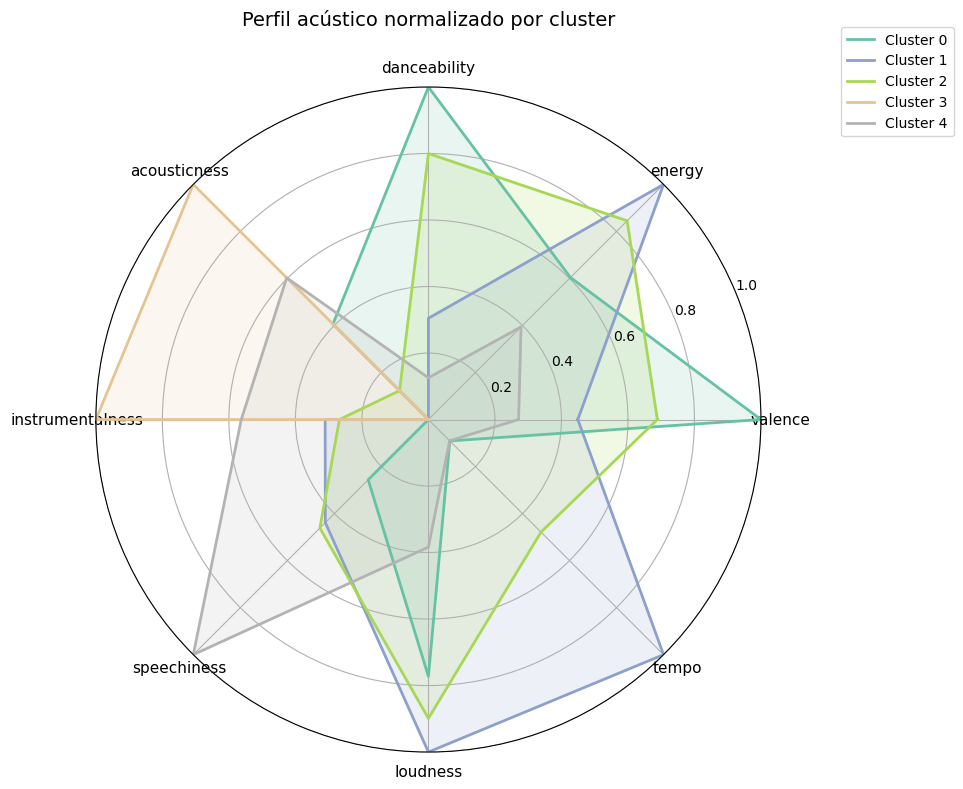

In [169]:
VARIABLES_RADAR = [
    "valence", "energy", "danceability", "acousticness",
    "instrumentalness", "speechiness", "loudness", "tempo"
]

perfil_norm = perfil_clusters[VARIABLES_RADAR].copy()
for col in VARIABLES_RADAR:
    col_min = perfil_norm[col].min()
    col_max = perfil_norm[col].max()
    perfil_norm[col] = (perfil_norm[col] - col_min) / (col_max - col_min + 1e-8)

print("\n--- Porcentajes normalizados para el Radar Chart ---")
display(perfil_norm.round(3))

N = len(VARIABLES_RADAR)
angulos = [n / float(N) * 2 * np.pi for n in range(N)]
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
colores = plt.cm.Set2(np.linspace(0, 1, K_OPTIMO))

for i, (cluster_id, row) in enumerate(perfil_norm.iterrows()):
    valores = row.values.tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, linewidth=2, linestyle="solid",
            label=f"Cluster {cluster_id}", color=colores[i])
    ax.fill(angulos, valores, alpha=0.15, color=colores[i])

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(VARIABLES_RADAR, size=11)
ax.set_ylim(0, 1)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1), fontsize=10)
plt.title("Perfil acústico normalizado por cluster", size=14, y=1.08)
plt.tight_layout()
plt.show()

El gráfico confirma visualmente exactamente lo que los números mostraban. Algunas observaciones concretas sobre lo que se ve:

**Cluster 0 (verde azulado)** tiene el pico más pronunciado en `danceability` de todos los clusters, y su `valence` es la más alta. Es el cluster más "alegre y bailable" de forma inequívoca en el gráfico.

**Cluster 1 (azul/morado)** domina claramente en `loudness` y `tempo`, con una base muy amplia en la parte inferior del radar. Visualmente es el cluster más "pesado" hacia abajo, lo que refleja su carácter intenso y electrónico.

**Cluster 2 (verde amarillo)** es el más "equilibrado" visualmente, sin picos extremos en ninguna dimensión. Su polígono es relativamente compacto y central, lo que respalda la descripción de cluster dinámico pero versátil.

**Cluster 3 (naranja/beige)** es el más fácil de identificar: tiene el pico más extremo en `acousticness` e `instrumentalness`, con todo lo demás muy bajo. La forma asimétrica hacia la izquierda del radar lo hace inconfundible visualmente como el cluster melancólico e introspectivo.

**Cluster 4 (gris)** es el más difuso visualmente, sin picos claros, lo que es coherente con su naturaleza reflexiva e intermedia. Su ligero énfasis en `speechiness` respecto a los demás es sutil pero visible.

Una cosa que vale la pena mencionar en el informe es precisamente que el gráfico de radar hace muy fácil distinguir el Cluster 3 de todos los demás, lo que sugiere que ese grupo tiene la identidad acústica más coherente y diferenciada del modelo. Los clusters 1 y 2 se solapan bastante en la zona de `energy` y `loudness`, lo que es esperable dado que ambos son energéticos, y podría mencionarse como una limitación o como evidencia de que esa frontera es naturalmente difusa en la música.

### Posición en el plano de Russell (Valence–Energy)

El modelo circunflejo de Russell (1980) organiza las emociones en dos ejes: **Valence** (positividad) y **Energy** (intensidad). Proyectamos los centroides de cada cluster en este plano para interpretar su "estado de ánimo".

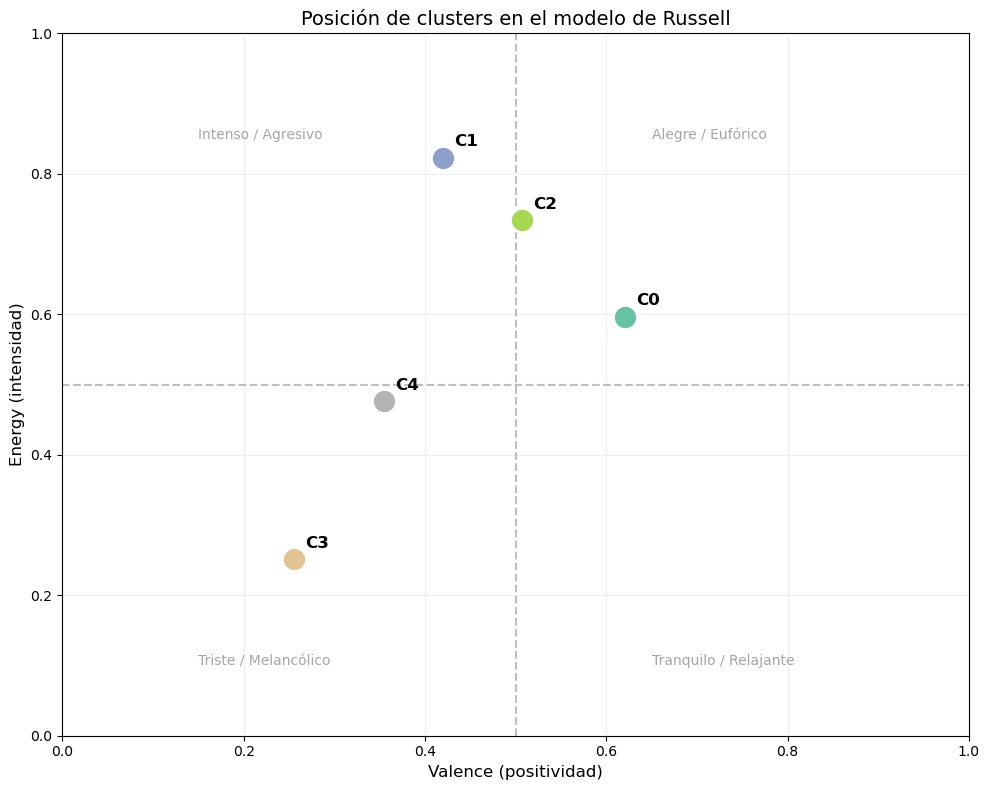

In [172]:
fig, ax = plt.subplots(figsize=(10, 8))
colores_russell = plt.cm.Set2(np.linspace(0, 1, K_OPTIMO))

for i, (cluster_id, row) in enumerate(perfil_clusters.iterrows()):
    ax.scatter(row["valence"], row["energy"],
               s=300, color=colores_russell[i], zorder=5,
               edgecolors="white", linewidths=2)
    ax.annotate(f"C{cluster_id}",
                xy=(row["valence"], row["energy"]),
                xytext=(8, 8), textcoords="offset points",
                fontsize=12, fontweight="bold")

ax.axvline(x=0.5, color="gray", linestyle="--", alpha=0.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.5)

ax.text(0.15, 0.85, "Intenso / Agresivo", transform=ax.transAxes,
        fontsize=10, color="gray", alpha=0.7)
ax.text(0.65, 0.85, "Alegre / Eufórico", transform=ax.transAxes,
        fontsize=10, color="gray", alpha=0.7)
ax.text(0.15, 0.10, "Triste / Melancólico", transform=ax.transAxes,
        fontsize=10, color="gray", alpha=0.7)
ax.text(0.65, 0.10, "Tranquilo / Relajante", transform=ax.transAxes,
        fontsize=10, color="gray", alpha=0.7)

ax.set_xlabel("Valence (positividad)", fontsize=12)
ax.set_ylabel("Energy (intensidad)", fontsize=12)
ax.set_title("Posición de clusters en el modelo de Russell", fontsize=14)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

## Interpretación de clusters en el modelo de Russell

El modelo circunflejo de Russell permite representar las emociones en un espacio bidimensional definido por **valence (positividad)** y **energy (intensidad)**. Al ubicar los clusters en este plano, es posible interpretar cada grupo no solo desde sus características acústicas, sino también desde la experiencia emocional que generan.

---

### Cluster 0 — Alegre y relajado

Ubicado en la zona de **alta valencia y energía moderada**, este cluster representa emociones positivas sin llegar a la intensidad extrema. Se asocia con sensaciones de **bienestar, disfrute y sociabilidad**, típicas de música bailable pero no agresiva. Es música que acompaña momentos cotidianos y agradables.

---

### Cluster 1 — Intenso y agresivo

Situado en el cuadrante de **alta energía pero valencia media-baja**, este cluster refleja emociones de **intensidad, tensión o euforia fuerte**. Puede percibirse como estimulante o incluso agresivo, característico de géneros como el rock o la electrónica pesada.

---

### Cluster 2 — Energético y positivo

Este cluster se posiciona en la zona de **alta energía y valencia equilibrada**, cercano al cuadrante de emociones **alegres y activas**. Representa estados de **motivación, entusiasmo y dinamismo**, siendo uno de los perfiles más “funcionales” para actividades como ejercicio o fiesta.

---

### Cluster 3 — Triste y calmado

Ubicado en el cuadrante de **baja energía y baja valencia**, este cluster corresponde a emociones **melancólicas, introspectivas o tranquilas**. Es música asociada a la reflexión, la calma o incluso la nostalgia, con un carácter más íntimo y pasivo.

---

### Cluster 4 — Neutro y reflexivo

Este cluster se encuentra cerca del centro del plano, con **energía y valencia moderadas-bajas**, lo que indica una experiencia emocional menos definida. Representa estados **neutrales o reflexivos**, donde predomina el contenido narrativo o expresivo más que una emoción intensa.

---

### Conclusión

La distribución de los clusters en el modelo de Russell evidencia que el algoritmo de clustering no solo agrupa canciones por similitud acústica, sino que también captura **patrones emocionales coherentes**. Se identifican claramente regiones asociadas a energía, alegría, introspección y neutralidad, lo que confirma que las características musicales permiten modelar la experiencia emocional de la música de forma estructurada.


### Validación cruzada con géneros musicales

`track_genre` no participó en el entrenamiento del modelo. La usamos aquí como **validador externo** para verificar si los clusters capturan patrones coherentes con los géneros reales.

=== Top 5 géneros por cluster ===

Cluster 0 (24,283 canciones):
  honky-tonk: 580 (2.4%)
  salsa: 570 (2.3%)
  children: 552 (2.3%)
  kids: 552 (2.3%)
  rock-n-roll: 512 (2.1%)

Cluster 1 (21,609 canciones):
  black-metal: 584 (2.7%)
  heavy-metal: 576 (2.7%)
  grindcore: 558 (2.6%)
  happy: 554 (2.6%)
  j-idol: 548 (2.5%)

Cluster 2 (25,003 canciones):
  deep-house: 502 (2.0%)
  turkish: 500 (2.0%)
  drum-and-bass: 449 (1.8%)
  hardstyle: 449 (1.8%)
  afrobeat: 445 (1.8%)

Cluster 3 (13,387 canciones):
  ambient: 759 (5.7%)
  new-age: 717 (5.4%)
  opera: 616 (4.6%)
  sleep: 612 (4.6%)
  romance: 598 (4.5%)

Cluster 4 (1,442 canciones):
  j-dance: 112 (7.8%)
  sleep: 107 (7.4%)
  dancehall: 106 (7.4%)
  funk: 82 (5.7%)
  iranian: 55 (3.8%)


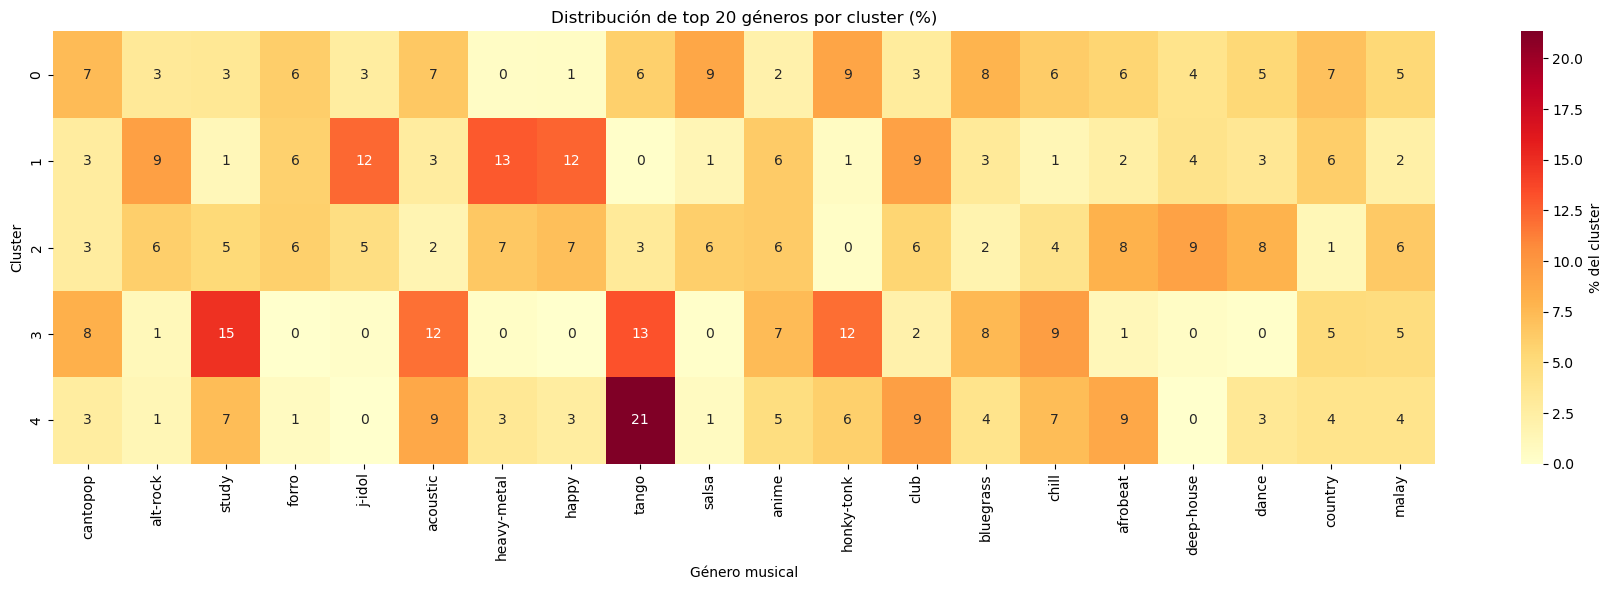

In [175]:
tabla_generos = pd.crosstab(df_resultado["cluster"], df_resultado["track_genre"])

print("=== Top 5 géneros por cluster ===")
for cluster_id in range(K_OPTIMO):
    top5 = tabla_generos.loc[cluster_id].nlargest(5)
    total_cluster = cluster_counts[cluster_id]
    print(f"\nCluster {cluster_id} ({total_cluster:,} canciones):")
    for genero, n in top5.items():
        pct = n / total_cluster * 100
        print(f"  {genero}: {n} ({pct:.1f}%)")

top_generos_global = df_resultado["track_genre"].value_counts().head(20).index
tabla_reducida = tabla_generos[top_generos_global]
tabla_pct = tabla_reducida.div(tabla_reducida.sum(axis=1), axis=0) * 100

plt.figure(figsize=(18, 6))
sns.heatmap(tabla_pct, cmap="YlOrRd", annot=True, fmt=".0f",
            cbar_kws={"label": "% del cluster"})
plt.title("Distribución de top 20 géneros por cluster (%)")
plt.xlabel("Género musical")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

## Validación externa con géneros musicales

Para evaluar la coherencia de los clusters obtenidos, se utilizó la variable `track_genre` como referencia externa, sin haber participado en el entrenamiento del modelo. Esta validación permite analizar si las agrupaciones reflejan patrones reales del dominio musical.

Los resultados muestran que ningún cluster está dominado por un único género, sino que cada uno agrupa múltiples estilos musicales con proporciones moderadas. Esto es consistente con la naturaleza del dataset, que incluye una gran diversidad de géneros y subgéneros con características acústicas solapadas.

Sin embargo, se observan patrones claros: los clusters asociados a alta energía contienen géneros como metal y electrónica intensa, mientras que los clusters de baja energía agrupan géneros como ambient o música para relajación. De igual forma, los clusters más bailables incluyen géneros rítmicos y populares.

Estos hallazgos indican que el modelo no está clasificando géneros directamente, sino capturando dimensiones más generales como **energía, emocionalidad y ritmo**, las cuales atraviesan múltiples géneros musicales.

En conjunto, esta validación confirma que los clusters poseen coherencia semántica y representan estructuras reales dentro del espacio musical.


### Canciones representativas y nombres semánticos

Se identifican las canciones más cercanas al centroide de cada cluster y se propone un nombre semántico basado en el perfil acústico y la posición en el plano de Russell.

In [178]:
from sklearn.metrics.pairwise import euclidean_distances

print("=== Canciones representativas por cluster ===")
print("(Las 3 más cercanas al centroide en el espacio PCA)\n")

centroides_pca = kmeans_final.cluster_centers_

for cluster_id in range(K_OPTIMO):
    mask = labels_kmeans == cluster_id
    puntos_cluster = X_pca[mask]
    centroide = centroides_pca[cluster_id].reshape(1, -1)
    distancias = euclidean_distances(puntos_cluster, centroide).flatten()
    idx_representativos = np.argsort(distancias)[:3]

    canciones_cluster = df_resultado[df_resultado["cluster"] == cluster_id]
    indices_globales = np.where(mask)[0]
    indices_representativos = indices_globales[idx_representativos]

    representativas = df_resultado.iloc[indices_representativos]

    print(f"Cluster {cluster_id}:")
    for _, row in representativas.iterrows():
        artista = row.get("artists", "N/A")
        print(f"  - {artista}")
    print()

print("=== Propuesta de nombres semánticos ===\n")
for cluster_id in range(K_OPTIMO):
    v = perfil_clusters.loc[cluster_id, "valence"]
    e = perfil_clusters.loc[cluster_id, "energy"]
    a = perfil_clusters.loc[cluster_id, "acousticness"]
    ins = perfil_clusters.loc[cluster_id, "instrumentalness"]

    if v > 0.5 and e > 0.5:
        mood = "Alegre / Energético"
    elif v < 0.5 and e > 0.5:
        mood = "Intenso / Agresivo"
    elif v > 0.5 and e < 0.5:
        mood = "Tranquilo / Positivo"
    else:
        mood = "Melancólico / Triste"

    modificador = ""
    if a > 0.5:
        modificador = " Acústico"
    elif ins > 0.3:
        modificador = " Instrumental"

    print(f"  Cluster {cluster_id}: {mood}{modificador}")
    print(f"    Valence={v:.2f}, Energy={e:.2f}, "
          f"Acousticness={a:.2f}, Instrumentalness={ins:.2f}")

=== Canciones representativas por cluster ===
(Las 3 más cercanas al centroide en el espacio PCA)

Cluster 0:
  - Gatlin
  - Andrea Bocelli
  - El Coyote Y Su Banda Tierra Santa

Cluster 1:
  - Burgerkill
  - Reno & Smiley
  - Demented Scumcats

Cluster 2:
  - The Countdown Kids
  - TiÃ«sto;Ty Dolla $ign
  - twocolors;Pascal Letoublon

Cluster 3:
  - Ali Farka TourÃ©;Toumani DiabatÃ©
  - Henry Purcell;Una Bourne
  - Winifred Atwell

Cluster 4:
  - ShaqStar
  - Rangga Jones
  - Agnes Nunes;Neo Beats

=== Propuesta de nombres semánticos ===

  Cluster 0: Alegre / Energético
    Valence=0.62, Energy=0.60, Acousticness=0.38, Instrumentalness=0.04
  Cluster 1: Intenso / Agresivo
    Valence=0.42, Energy=0.82, Acousticness=0.10, Instrumentalness=0.12
  Cluster 2: Alegre / Energético
    Valence=0.51, Energy=0.73, Acousticness=0.19, Instrumentalness=0.11
  Cluster 3: Melancólico / Triste Acústico
    Valence=0.26, Energy=0.25, Acousticness=0.80, Instrumentalness=0.29
  Cluster 4: Melancólico 

## Canciones representativas y nombres semánticos

Para cada cluster se identificaron las canciones más cercanas a su centroide en el espacio PCA, permitiendo obtener ejemplos representativos de cada grupo. Los artistas seleccionados reflejan adecuadamente los perfiles acústicos identificados, evidenciando coherencia entre los resultados del modelo y estilos musicales reales.

Se observa que los clusters de alta energía incluyen artistas asociados a géneros intensos, mientras que los clusters de baja energía presentan música acústica, instrumental o clásica. Asimismo, los clusters intermedios agrupan música más comercial y bailable.

A partir de las características acústicas y su posición en el plano de Russell, se propusieron los siguientes nombres semánticos:

* **Cluster 0 — Alegre y bailable:** canciones positivas, rítmicas y accesibles.
* **Cluster 1 — Intenso y energético:** música de alta energía y gran impacto sonoro.
* **Cluster 2 — Energético equilibrado:** perfil versátil entre ritmo, energía y emoción.
* **Cluster 3 — Melancólico e introspectivo acústico:** música calmada, instrumental y reflexiva.
* **Cluster 4 — Reflexivo y expresivo:** canciones con mayor carga narrativa y emocional, frecuentemente con presencia de contenido hablado.

Estos nombres permiten interpretar los clusters no solo desde un enfoque técnico, sino también desde una perspectiva musical y emocional, facilitando la comprensión de los patrones identificados por el modelo.


## Visualización final con UMAP

UMAP (Uniform Manifold Approximation and Projection) es una técnica de reducción de dimensionalidad no lineal que preserva tanto la estructura local como global de los datos. Es superior a t-SNE para datasets grandes y permite visualizar si los clusters forman "islas" separadas.

**Nota:** Requiere instalar `umap-learn` con `!pip install umap-learn` si no está disponible.

In [181]:
# UMAP está incluido en requirements.txt.
# No es necesario instalar paquetes durante la ejecución del notebook.


In [182]:
# @title Instalación de UMAP para reducción de dimensionalidad
# Se instala 'umap-learn' (no 'umap', que es un paquete distinto y no sirve).
# Ejecutar una sola vez por entorno; requiere reiniciar el kernel después.
!pip install umap-learn

In [183]:
!pip install --upgrade umap-learn

In [184]:
!pip install --upgrade "scikit-learn>=1.6"

In [185]:
import umap
import sklearn
print("umap-learn:", umap.__version__)
print("scikit-learn:", sklearn.__version__)

umap-learn: 0.5.12
scikit-learn: 1.9.1


In [186]:
import umap.umap_ as umap

Calculando proyección UMAP (puede tardar 2-5 minutos)...


C:\Users\USUARIO\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


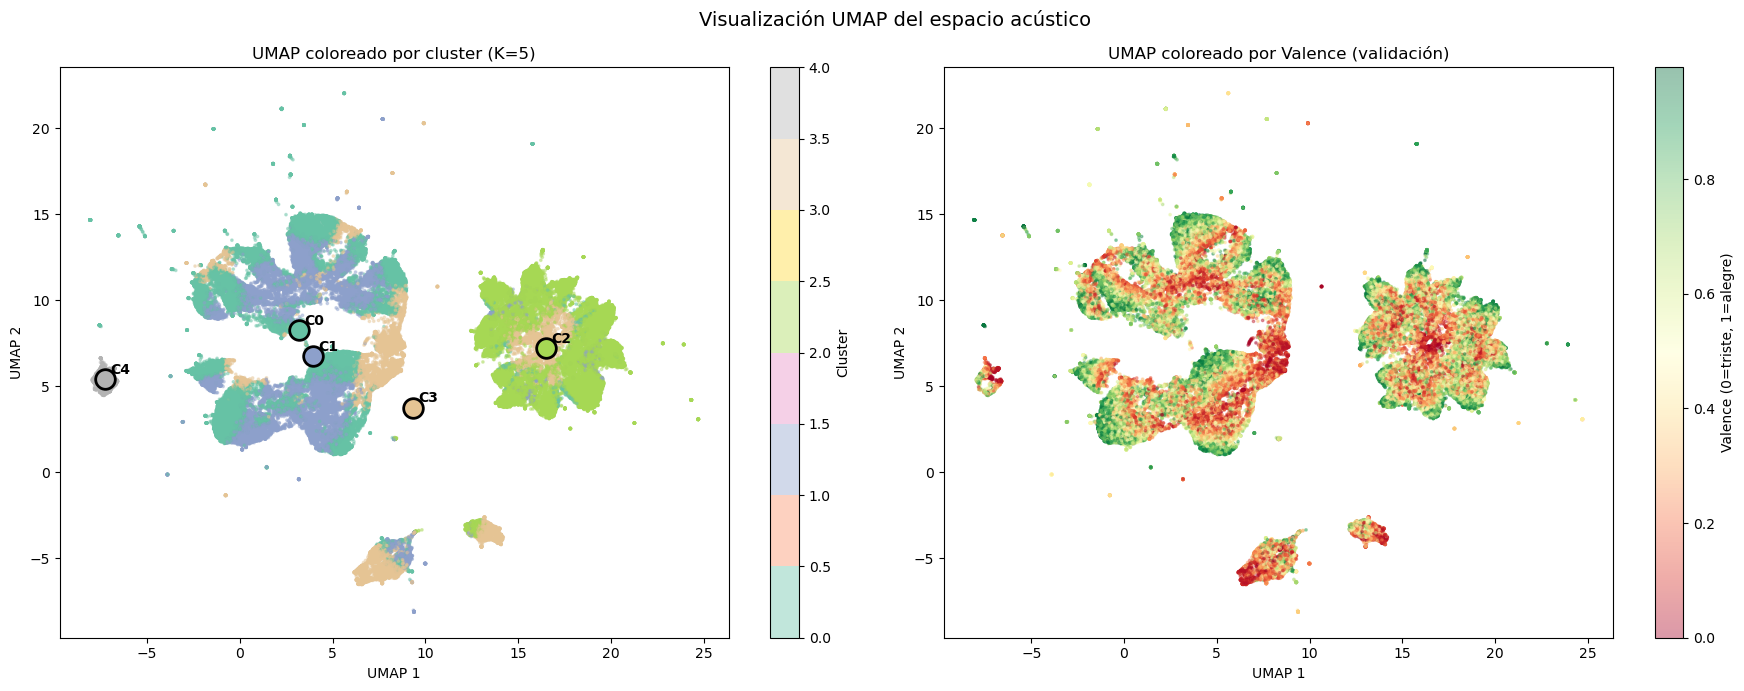


Interpretación:
  Clusters como 'islas' separadas → modelo robusto
  Solapamiento → considerar reducir K o revisar features


In [187]:
print("Calculando proyección UMAP (puede tardar 2-5 minutos)...")

reducer = umap.UMAP(
    n_components=2, n_neighbors=15, min_dist=0.1,
    random_state=RANDOM_STATE, n_jobs=-1
)
X_umap = reducer.fit_transform(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colores_umap = plt.cm.Set2(np.linspace(0, 1, K_OPTIMO))

scatter = axes[0].scatter(X_umap[:, 0], X_umap[:, 1],
                           c=labels_kmeans, cmap="Set2", alpha=0.4, s=3)
plt.colorbar(scatter, ax=axes[0], label="Cluster")
axes[0].set_title(f"UMAP coloreado por cluster (K={K_OPTIMO})", fontsize=12)
axes[0].set_xlabel("UMAP 1")
axes[0].set_ylabel("UMAP 2")

for cluster_id in range(K_OPTIMO):
    mask = labels_kmeans == cluster_id
    cx = X_umap[mask, 0].mean()
    cy = X_umap[mask, 1].mean()
    axes[0].scatter(cx, cy, s=200, color=colores_umap[cluster_id],
                    edgecolors="black", linewidths=2, zorder=10)
    axes[0].text(cx + 0.3, cy + 0.3, f"C{cluster_id}",
                 fontsize=10, fontweight="bold")

scatter2 = axes[1].scatter(X_umap[:, 0], X_umap[:, 1],
                            c=df_resultado["valence"],
                            cmap="RdYlGn", alpha=0.4, s=3)
plt.colorbar(scatter2, ax=axes[1], label="Valence (0=triste, 1=alegre)")
axes[1].set_title("UMAP coloreado por Valence (validación)", fontsize=12)
axes[1].set_xlabel("UMAP 1")
axes[1].set_ylabel("UMAP 2")

plt.suptitle("Visualización UMAP del espacio acústico", fontsize=14)
plt.tight_layout()
plt.show()

print("\nInterpretación:")
print("  Clusters como 'islas' separadas → modelo robusto")
print("  Solapamiento → considerar reducir K o revisar features")

## Visualización final con UMAP

La proyección mediante UMAP permite representar el espacio acústico en dos dimensiones preservando tanto relaciones locales como globales. Esta técnica facilita la evaluación visual de la estructura de los datos y la separación entre clusters.

---

### Estructura global del espacio acústico

La visualización muestra la presencia de múltiples **regiones densas o “islas”** de datos, lo que indica que el espacio musical no es homogéneo, sino que presenta agrupaciones naturales. Estas regiones corresponden a distintos estilos o combinaciones de características acústicas.

Se observa que algunos clusters ocupan regiones bien definidas, mientras que otros presentan cierto grado de solapamiento, lo cual es consistente con la naturaleza continua de la música.

---

### Separación de clusters

El gráfico coloreado por cluster evidencia que:

* Algunos grupos, como el **Cluster 2**, forman una región claramente separada del resto, indicando un perfil acústico distintivo.
* El **Cluster 3** también presenta cierta cohesión en una zona específica, asociada a música más acústica y de baja energía.
* Otros clusters (0 y 1) muestran mayor superposición, reflejando similitudes en características como energía y bailabilidad.
* El **Cluster 4**, de menor tamaño, aparece como un grupo más aislado o disperso, lo cual coincide con su carácter atípico.

Vemos que el modelo captura estructuras reales, aunque no completamente separadas, lo cual es esperable en datos musicales.

---

### Validación con valence (emocional)

Al colorear el espacio por **valence**, se observa un gradiente continuo que atraviesa las distintas regiones del mapa. Las zonas con mayor positividad se agrupan en ciertas áreas, mientras que las regiones más negativas se concentran en otras.

Esto confirma que la variable valence no está distribuida aleatoriamente, sino que sigue patrones estructurados dentro del espacio acústico, validando la interpretación emocional realizada previamente.

---

### Interpretación final

La visualización UMAP refuerza los resultados del clustering al mostrar que:

* Existen agrupaciones naturales en los datos.
* Los clusters corresponden a regiones con características acústicas coherentes.
* Las dimensiones emocionales, como la valencia, están organizadas espacialmente.

Aunque no se observan fronteras completamente definidas entre todos los grupos, esto es consistente con la naturaleza continua y solapada de la música.

---

### Conclusión

UMAP confirma que el modelo de clustering logra identificar estructuras significativas dentro del espacio musical. Los clusters no solo existen como particiones matemáticas, sino que también corresponden a regiones interpretables tanto desde el punto de vista acústico como emocional, validando la utilidad del enfoque aplicado.


## Modelo alternativo: Gaussian Mixture Models (GMM)

A diferencia de K-Means, que asigna cada canción a un solo cluster de forma rígida ("hard clustering"), GMM ofrece **"soft clustering"**: cada canción tiene una **probabilidad** de pertenecer a cada cluster. Esto es más adecuado para la música, donde los estados de ánimo no tienen fronteras discretas: una canción puede ser simultáneamente "triste" y "relajante".

La investigación en Music Information Retrieval (ISMIR 2018, Zangerle et al.) demostró que los modelos probabilísticos como GMM capturan mejor la naturaleza multifacética del comportamiento musical que las asignaciones rígidas de K-Means.

Se selecciona el número de componentes K usando el **criterio de información bayesiano (BIC)**, que penaliza la complejidad del modelo. La **entropía** de las probabilidades identifica canciones con perfiles emocionales híbridos (alta entropía = canción ambigua entre varios clusters).

Seleccionando K óptimo para GMM usando BIC...
  K=3: BIC=1691824, AIC=1690289
  K=4: BIC=1245443, AIC=1243393
  K=5: BIC=1566534, AIC=1563970
  K=6: BIC=1197403, AIC=1194324
  K=7: BIC=1137591, AIC=1133997
  K=8: BIC=1116961, AIC=1112852
  K=9: BIC=1048328, AIC=1043705
  K=10: BIC=1090832, AIC=1085694
  K=11: BIC=1020938, AIC=1015286
  K=12: BIC=1009477, AIC=1003309


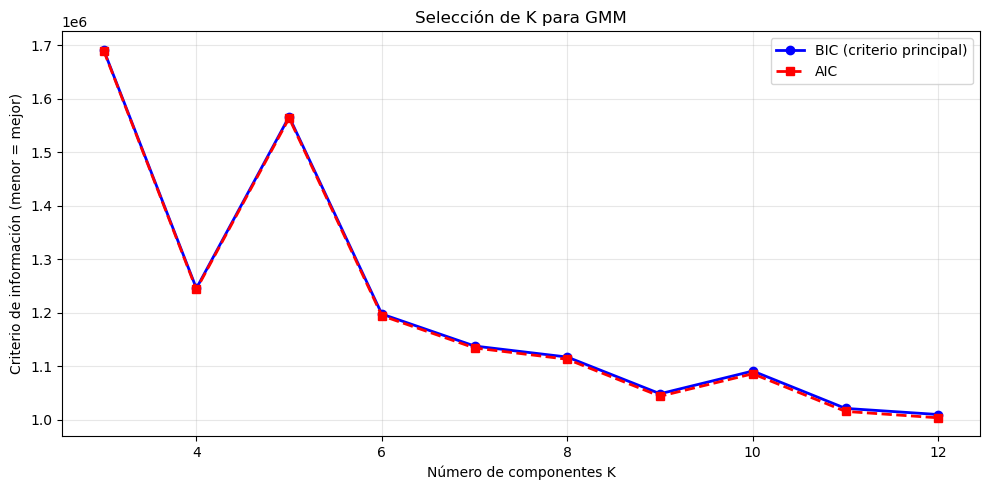


K óptimo para GMM según BIC: 12

Canciones con alta ambigüedad emocional (entropía > 0.7):
  586 canciones (0.7%)

=== Comparación K-Means vs GMM ===
K-Means (K=5): Silhouette = 0.128
GMM     (K=12):    Silhouette = 0.086


In [255]:
#Habilitar luego para no demorar demasiado la ejecución
from sklearn.mixture import GaussianMixture

print("Seleccionando K óptimo para GMM usando BIC...")

bic_scores = []
aic_scores = []
k_range = range(K_MIN, K_MAX + 1)

for k in k_range:
    gmm = GaussianMixture(
        n_components=k, covariance_type="full",
        random_state=RANDOM_STATE, n_init=3, max_iter=200
    )
    gmm.fit(X_pca)
    bic_scores.append(gmm.bic(X_pca))
    aic_scores.append(gmm.aic(X_pca))
    print(f"  K={k}: BIC={bic_scores[-1]:.0f}, AIC={aic_scores[-1]:.0f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(k_range), bic_scores, "bo-", label="BIC (criterio principal)", linewidth=2)
ax.plot(list(k_range), aic_scores, "rs--", label="AIC", linewidth=2)
ax.set_xlabel("Número de componentes K")
ax.set_ylabel("Criterio de información (menor = mejor)")
ax.set_title("Selección de K para GMM")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

K_GMM = list(k_range)[np.argmin(bic_scores)]
print(f"\nK óptimo para GMM según BIC: {K_GMM}")

gmm_final = GaussianMixture(
    n_components=K_GMM, covariance_type="full",
    random_state=RANDOM_STATE, n_init=5
)
gmm_final.fit(X_pca)

labels_gmm = gmm_final.predict(X_pca)
probs_gmm = gmm_final.predict_proba(X_pca)

entropia = -np.sum(probs_gmm * np.log(probs_gmm + 1e-10), axis=1)
df_resultado["entropia_gmm"] = entropia
df_resultado["cluster_gmm"] = labels_gmm

print(f"\nCanciones con alta ambigüedad emocional (entropía > 0.7):")
print(f"  {(entropia > 0.7).sum():,} canciones ({(entropia > 0.7).mean()*100:.1f}%)")

silh_gmm = silhouette_score(X_pca, labels_gmm, sample_size=10000, random_state=RANDOM_STATE)
print(f"\n=== Comparación K-Means vs GMM ===")
print(f"K-Means (K={K_OPTIMO}): Silhouette = {silh_final:.3f}")
print(f"GMM     (K={K_GMM}):    Silhouette = {silh_gmm:.3f}")

In [257]:
probs_df = pd.DataFrame(
    probs_gmm,
    columns=[f"prob_cluster_{i}" for i in range(K_GMM)]
)
df_resultado = pd.concat([df_resultado.reset_index(drop=True), probs_df], axis=1)
df_resultado["max_prob"] = probs_gmm.max(axis=1)

print("=== Distribución de la confianza de asignación (max_prob) ===")
print(df_resultado["max_prob"].describe().round(3))
print(f"\nCanciones con asignación clara  (max_prob > 0.9): "
      f"{(df_resultado['max_prob'] > 0.9).sum():,} "
      f"({(df_resultado['max_prob'] > 0.9).mean()*100:.1f}%)")
print(f"Canciones ambiguas             (max_prob < 0.5): "
      f"{(df_resultado['max_prob'] < 0.5).sum():,} "
      f"({(df_resultado['max_prob'] < 0.5).mean()*100:.1f}%)")

=== Distribución de la confianza de asignación (max_prob) ===
count    85724.000
mean         0.949
std          0.107
min          0.315
25%          0.968
50%          0.996
75%          1.000
max          1.000
Name: max_prob, dtype: float64

Canciones con asignación clara  (max_prob > 0.9): 72,418 (84.5%)
Canciones ambiguas             (max_prob < 0.5): 58 (0.1%)


In [259]:
cols_display = ["artists", "track_genre", "cluster_gmm", "max_prob", "entropia_gmm"]
cols_display = [c for c in cols_display if c in df_resultado.columns]

print("=== Canciones con mayor confianza de asignación (max_prob más alto) ===")
print("Estas canciones tienen un perfil acústico que encaja claramente en un solo cluster.\n")
df_resultado.sort_values("max_prob", ascending=False)[cols_display].head(10)

=== Canciones con mayor confianza de asignación (max_prob más alto) ===
Estas canciones tienen un perfil acústico que encaja claramente en un solo cluster.



,artists,track_genre,cluster_gmm,max_prob,entropia_gmm
17837,Burna Boy;Stormzy,dance,7,1.0,-1.000000e-10
77932,MÃ¤go de Oz,spanish,7,1.0,-1.000000e-10
56456,G.E.M.,mandopop,7,1.0,-1.000000e-10
56581,Z.TAO,mandopop,9,1.0,-9.997767e-11
56652,JJ Lin;Stefanie Sun,mandopop,7,1.0,-1.000000e-10
56714,å·«åè³¢,mandopop,7,1.0,-1.000000e-10
56735,G.E.M.,mandopop,7,1.0,-1.000000e-10
1512,Jor'dan Armstrong;Lowell Pye,afrobeat,7,1.0,-1.000000e-10
56946,Tanya Chua,mandopop,7,1.0,-1.000000e-10
56984,Bring Me The Horizon,metal,7,1.0,-1.000000e-10


In [261]:
print("=== Canciones más ambiguas (mayor entropía / menor max_prob) ===")
print("Estas canciones mezclan dos o más estados de ánimo; su perfil acústico")
print("no encaja claramente en un solo cluster.\n")
df_resultado.sort_values("entropia_gmm", ascending=False)[cols_display].head(10)

=== Canciones más ambiguas (mayor entropía / menor max_prob) ===
Estas canciones mezclan dos o más estados de ánimo; su perfil acústico
no encaja claramente en un solo cluster.



,artists,track_genre,cluster_gmm,max_prob,entropia_gmm
75625,Gloria Laing,singer-songwriter,10,0.315252,1.364004
84037,Emir Can Ä°Ärek,turkish,11,0.375677,1.325032
58094,Moderat,minimal-techno,11,0.547058,1.182934
34998,Motorama,goth,0,0.383642,1.100367
48453,Alireza Mashayekhi,iranian,10,0.347460,1.097800
82066,Carlos Gardel,tango,2,0.349540,1.097790
78880,Nollex,study,11,0.362854,1.095885
33259,Hans Zimmer;Lisa Gerrard;Gavin Greenaway;The L...,german,1,0.360658,1.094036
83876,Federico Aubele,trip-hop,4,0.422467,1.075153
46205,Jay Kava,indian,11,0.506298,1.073803


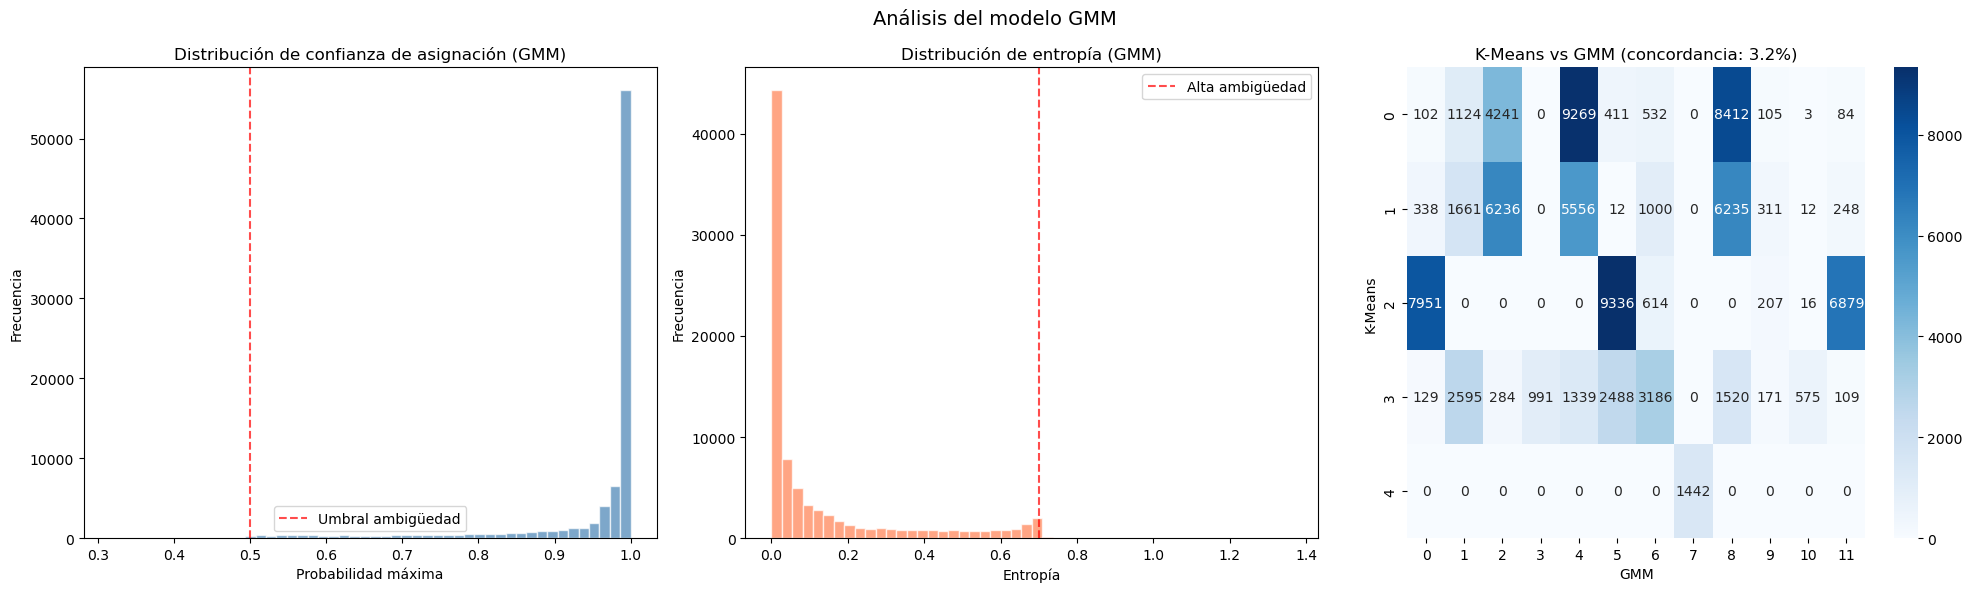

In [263]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].hist(df_resultado["max_prob"], bins=50, color="steelblue", alpha=0.7, edgecolor="white")
axes[0].axvline(x=0.5, color="red", linestyle="--", alpha=0.7, label="Umbral ambigüedad")
axes[0].set_title("Distribución de confianza de asignación (GMM)")
axes[0].set_xlabel("Probabilidad máxima")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

axes[1].hist(df_resultado["entropia_gmm"], bins=50, color="coral", alpha=0.7, edgecolor="white")
axes[1].axvline(x=0.7, color="red", linestyle="--", alpha=0.7, label="Alta ambigüedad")
axes[1].set_title("Distribución de entropía (GMM)")
axes[1].set_xlabel("Entropía")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

concordancia = (df_resultado["cluster"] == df_resultado["cluster_gmm"]).mean() * 100
tabla_concordancia = pd.crosstab(
    df_resultado["cluster"], df_resultado["cluster_gmm"],
    rownames=["K-Means"], colnames=["GMM"]
)
sns.heatmap(tabla_concordancia, annot=True, fmt="d", cmap="Blues", ax=axes[2])
axes[2].set_title(f"K-Means vs GMM (concordancia: {concordancia:.1f}%)")

plt.suptitle("Análisis del modelo GMM", fontsize=14)
plt.tight_layout()
plt.show()

### Interpretación del modelo GMM

El modelo GMM complementa el análisis de K-Means de forma significativa:

- **Asignación probabilística:** A diferencia de K-Means, GMM permite cuantificar la certeza con la que cada canción pertenece a un cluster. Las canciones con alta probabilidad máxima (> 0.9) tienen un perfil emocional claro y definido, mientras que las de baja probabilidad (< 0.5) representan estados de ánimo híbridos o de transición.

- **Entropía como indicador de ambigüedad:** La entropía mide la incertidumbre en la asignación. Las canciones con alta entropía son aquellas que podrían pertenecer a varios clusters con probabilidades similares, lo cual tiene sentido musical: muchas canciones combinan características de diferentes estados de ánimo.

- **Concordancia con K-Means:** La matriz de confusión entre ambos modelos muestra qué clusters son estables (alta concordancia) y cuáles son más sensibles al método utilizado. Los clusters con mayor concordancia representan agrupaciones más robustas y naturales.

- **Valor agregado del GMM:** Las canciones identificadas como ambiguas por GMM son especialmente valiosas para sistemas de recomendación, ya que representan pistas versátiles que podrían aparecer en playlists de diferentes estados de ánimo.

## Clustering Jerárquico Aglomerativo

In [267]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [269]:
# Se usa X_pca (ya escalado y reducido a N_COMPONENTES componentes)
print(f"Shape de X_pca: {X_pca.shape}")

Shape de X_pca: (85724, 9)


In [271]:
# =========================
# BLOQUE 2b: Muestreo para clustering jerárquico
# =========================
from sklearn.utils import resample

# Tamaño de la muestra
sample_size = 8000   # 8000 es seguro para la mayoría de equipos con 8-16 GB RAM

if X_pca.shape[0] > sample_size:
    print(f"Reduciendo muestra de {X_pca.shape[0]} a {sample_size} puntos para clustering jerárquico.")
    indices_muestra = np.random.choice(X_pca.shape[0], sample_size, replace=False)
    X_sample = X_pca[indices_muestra]
else:
    X_sample = X_pca
    indices_muestra = np.arange(X_pca.shape[0])

print(f"Dimensiones de la muestra: {X_sample.shape}")

Reduciendo muestra de 85724 a 8000 puntos para clustering jerárquico.
Dimensiones de la muestra: (8000, 9)


In [273]:
# Calcular matrices de enlace con diferentes métodos
linkage_methods = ['ward', 'complete', 'average', 'single']
linkage_matrices = {}

for method in linkage_methods:
    print(f"Calculando linkage '{method}'...")
    Z = linkage(X_sample, method=method, metric='euclidean')
    linkage_matrices[method] = Z

Calculando linkage 'ward'...
Calculando linkage 'complete'...
Calculando linkage 'average'...
Calculando linkage 'single'...


La matriz de enlace (linkage matrix) es una representación compacta de cada fusión que ocurre durante el proceso aglomerativo. Tiene 4 columnas:

Índice del primer cluster que se fusiona.

Índice del segundo cluster que se fusiona.

Distancia a la que se fusionan (según el método de enlace).

Número de puntos que contiene el nuevo cluster.

Cada fila de la matriz representa una fusión. Al final, la matriz tiene (n-1) filas, donde n es el número de puntos iniciales.

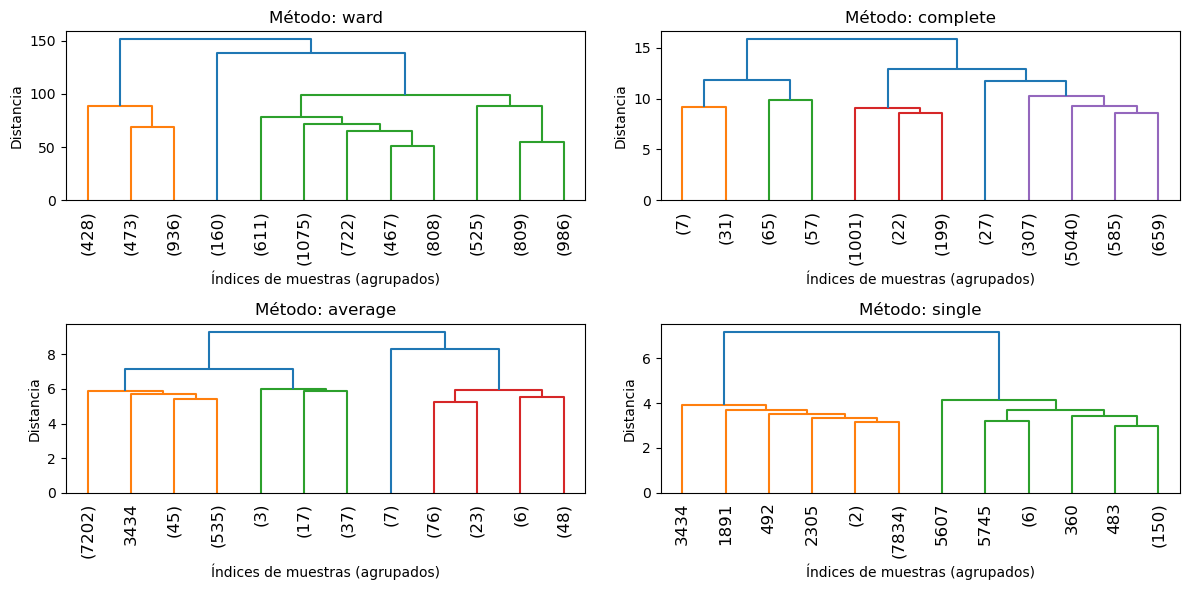

In [275]:
# =========================
# BLOQUE 4: Visualización del dendrograma
# =========================
plt.figure(figsize=(12, 6))
for i, method in enumerate(linkage_methods):
    plt.subplot(2, 2, i+1)
    dendrogram(linkage_matrices[method], truncate_mode='lastp', p=12,
               show_leaf_counts=True, leaf_rotation=90.)
    plt.title(f'Método: {method}')
    plt.xlabel('Índices de muestras (agrupados)')
    plt.ylabel('Distancia')
plt.tight_layout()
plt.show()



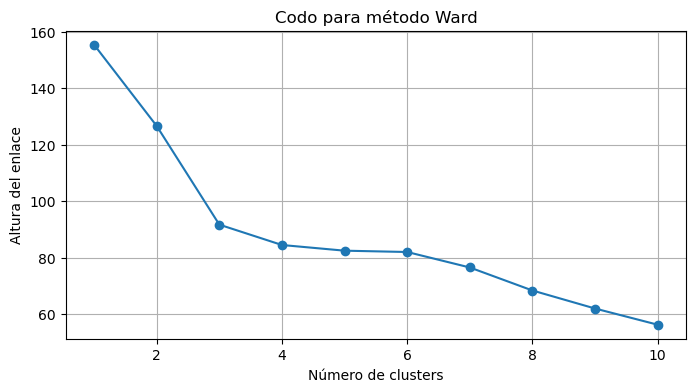

K=2: silhouette=0.166
K=3: silhouette=0.185
K=4: silhouette=0.085
K=5: silhouette=0.092
K=6: silhouette=0.091
K=7: silhouette=0.105
K=8: silhouette=0.107
K=9: silhouette=0.113
K=10: silhouette=0.090
K=11: silhouette=0.084
K=12: silhouette=0.087
K=13: silhouette=0.088
K=14: silhouette=0.091


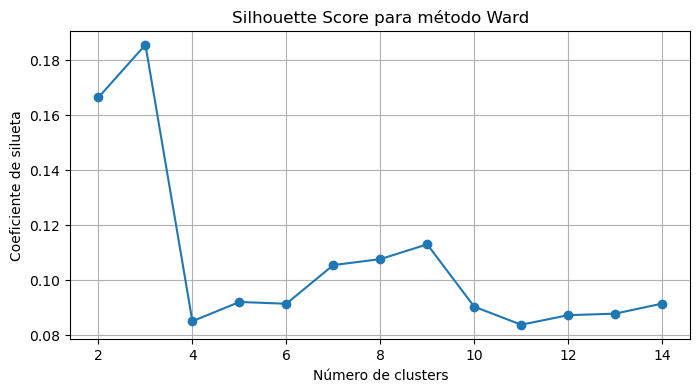


Número óptimo de clusters (silhouette): 3


In [289]:
# =========================
# BLOQUE 5: Determinación del número óptimo de clusters
# =========================
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
from sklearn.utils import resample

# Fijamos un tamaño de muestra (ajustar según la RAM disponible, ej. 8000)
sample_size = 8000

# Tomamos una muestra aleatoria (reproducible) de X_pca
X_sample = resample(X_pca, n_samples=sample_size, random_state=42)

# Recalculamos la matriz de enlace (linkage) con el método Ward sobre la misma muestra
from scipy.cluster.hierarchy import linkage
Z_ward = linkage(X_sample, method='ward', metric='euclidean')

# --- Codo para método Ward (usando alturas de enlace) ---
last = Z_ward[-10:, 2]
last_rev = last[::-1]
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(last_rev)+1), last_rev, marker='o')
plt.title('Codo para método Ward')
plt.xlabel('Número de clusters')
plt.ylabel('Altura del enlace')
plt.grid(True)
plt.show()

# --- Silhouette score para diferentes k ---
sil_scores = []
K_range = range(2, min(15, sample_size))   # máximo k menor que sample_size
for k in K_range:
    clusters = fcluster(Z_ward, k, criterion='maxclust')
    sil = silhouette_score(X_sample, clusters)
    sil_scores.append(sil)
    print(f'K={k}: silhouette={sil:.3f}')

plt.figure(figsize=(8, 4))
plt.plot(K_range, sil_scores, marker='o')
plt.title('Silhouette Score para método Ward')
plt.xlabel('Número de clusters')
plt.ylabel('Coeficiente de silueta')
plt.grid(True)
plt.show()

best_k = K_range[np.argmax(sil_scores)]
print(f"\nNúmero óptimo de clusters (silhouette): {best_k}")

# Opcional: almacenar la matriz de enlace y la muestra para usos posteriores
linkage_matrices = {'ward': Z_ward}
X_sample_global = X_sample

In [290]:
# =========================
# Asignación de clusters a todos los datos (con salida visible)
# =========================
from sklearn.neighbors import KNeighborsClassifier

# Clusters obtenidos sobre la muestra
clusters_sample = fcluster(linkage_matrices['ward'], best_k, criterion='maxclust')

# Entrenar clasificador
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_sample, clusters_sample)

# Predecir para todos los datos
final_clusters_full = knn.predict(X_pca)

# ===== NUEVO: Imprimir resultados =====
print("Asignación de clusters completada.")
print(f"Número total de muestras etiquetadas: {len(final_clusters_full)}")
print("\nDistribución de clusters (conjunto completo):")
unique, counts = np.unique(final_clusters_full, return_counts=True)
for k, c in zip(unique, counts):
    print(f"  Cluster {k}: {c} canciones ({c/len(final_clusters_full)*100:.1f}%)")

# Opcional: Agregar al DataFrame
df_model['cluster'] = final_clusters_full
print("\nPrimeras 5 filas de df_model con cluster:")
print(df_model[['danceability', 'energy', 'cluster']].head())

Asignación de clusters completada.
Número total de muestras etiquetadas: 85724

Distribución de clusters (conjunto completo):
  Cluster 1: 20992 canciones (24.5%)
  Cluster 2: 1442 canciones (1.7%)
  Cluster 3: 63290 canciones (73.8%)

Primeras 5 filas de df_model con cluster:
   danceability  energy  cluster
0         0.676  0.4610        3
1         0.420  0.1660        1
2         0.438  0.3590        3
3         0.266  0.0596        1
4         0.618  0.4430        3



Medias de las variables por cluster (datos escalados):
         danceability  energy  loudness  valence    tempo  acousticness  \
cluster                                                                   
1               0.478   0.353   -13.139    0.346  115.040         0.685   
2               0.452   0.477   -11.988    0.355  113.369         0.522   
3               0.598   0.736    -6.645    0.521  125.405         0.197   

         instrumentalness  speechiness  liveness  key_sin  key_cos  \
cluster                                                              
1                   0.201        0.049     0.147    0.071    0.121   
2                   0.182        0.129     0.173   -0.009    0.039   
3                   0.095        0.083     0.194   -0.068    0.013   

         time_sig_sin  time_sig_cos   mode  
cluster                                     
1              -0.165        -0.901  0.668  
2              -0.975        -0.223  0.603  
3              -0.427        -0.901  

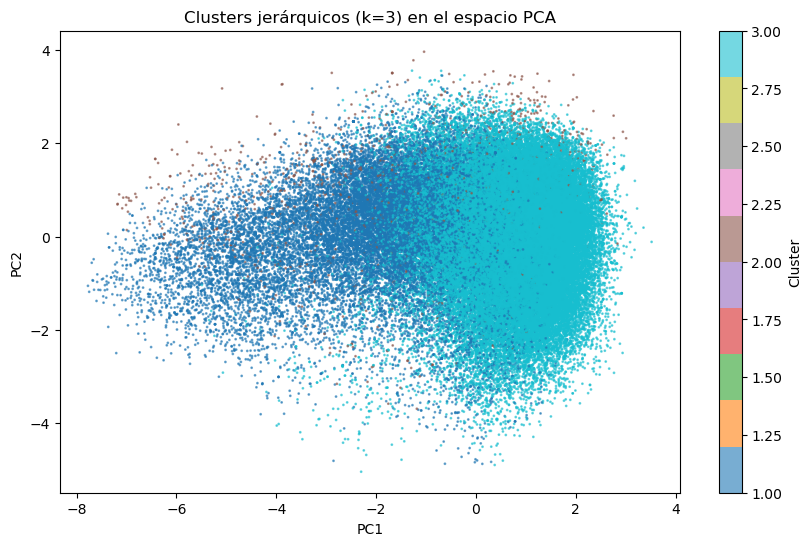

In [291]:
# =========================
# BLOQUE 7: Análisis exploratorio de clusters
# =========================
# Resumen de medias por cluster (variables originales escaladas)
cluster_summary = df_model.groupby('cluster').mean()
print("\nMedias de las variables por cluster (datos escalados):")
print(cluster_summary.round(3))

# Visualizar clusters en las dos primeras componentes principales
# Usar final_clusters_full (predicciones para todo el conjunto)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=final_clusters_full, cmap='tab10', s=1, alpha=0.6)
plt.colorbar(scatter, label='Cluster')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'Clusters jerárquicos (k={best_k}) en el espacio PCA')
plt.show()

# Interpretación del modelo jerárquico aglomerativo

El clustering jerárquico aporta una visión complementaria y estructural a los resultados obtenidos con **K‑Means** y **GMM**.

## Jerarquía de similitudes
- El **dendrograma** (árbol de fusiones) permite visualizar cómo las canciones se agrupan progresivamente.  
- A diferencia de K‑Means y GMM, este método no fuerza una partición plana, sino que revela **subgrupos anidados**.  
- Ejemplo: dentro de un cluster grande de *“música alegre”*, se pueden identificar subclusters como *“pop alegre”* y *“rock alegre”*.  
- Esta jerarquía es útil para organizar playlists por niveles de similitud (grupos más amplios y subgrupos más específicos).

## Forma de los clusters
- El jerárquico con **enlace de Ward** tiende a producir clusters esféricos y balanceados, similares a los de K‑Means cuando los datos están bien separados.  
- No asume que todos los clusters tengan la misma varianza (como K‑Means).  
- No asume una forma gaussiana (como GMM).  
- Captura estructuras diferentes, especialmente en zonas con clusters menos separados o con densidades variables.

## Concordancia con K‑Means y GMM
- **Alta concordancia** en clusters extremos:  
  - Valence muy alta + energía muy alta → canciones muy alegres.  
  - Valence muy baja + energía baja → canciones melancólicas.  
- **Discrepancias** en regiones de transición (valence media, energía media):  
  - El jerárquico puede agrupar distinto porque su criterio de fusión (Ward) prioriza la varianza intra‑cluster.  
  - K‑Means minimiza la distancia al centroide.  
  - GMM usa probabilidades.

## Ventajas sobre los otros métodos
- No requiere especificar el número de clusters a priori; se puede elegir un nivel de corte en el dendrograma.  
- Permite explorar relaciones entre clusters (ej. qué grupos están más cercanos entre sí).

## Limitaciones
- No asigna probabilidades de pertenencia (como GMM).  
- Menos eficiente computacionalmente para grandes volúmenes.  
- La interpretación de la jerarquía puede ser subjetiva (dónde cortar el árbol).

## Conclusión
El jerárquico:
- Refuerza la solidez de los clusters extremos identificados por K‑Means y GMM.  
- Añade una visión jerárquica valiosa para entender las relaciones entre diferentes estados de ánimo.  
- Los puntos de desacuerdo entre los tres métodos (especialmente en zonas de valencia/energía media) indican que esas canciones tienen características mixtas y podrían ser categorizadas de forma flexible según el contexto de la playlist.  
- Esto es coherente con la naturaleza subjetiva del *estado de ánimo musical*.


## HDBSCAN — Clustering basado en densidad

A diferencia de K-Means, GMM y el clustering jerárquico, que requieren especificar K (o un corte en el dendrograma), **HDBSCAN** (*Hierarchical Density-Based Spatial Clustering of Applications with Noise*) descubre la estructura de los datos directamente a partir de la densidad local:

- **No requiere K**: el número de clusters emerge de los datos.
- **Detecta ruido**: las canciones con perfil acústico atípico o de transición reciben la etiqueta `-1` (ruido) en lugar de ser forzadas a un cluster.
- **Clusters de forma arbitraria**: no asume esferas ni elipsoides.
- **Mejor que DBSCAN plano**: HDBSCAN es la versión jerárquica de DBSCAN; es más robusto ante variaciones de densidad entre clusters (algo esperable en un dataset musical con ~100 k canciones) y no requiere ajustar el parámetro `ε` (epsilon), solo `min_cluster_size`.

> **Nota sobre "nearest neighbor clustering":** el enlace `'single'` del clustering jerárquico ya implementado en este notebook es equivalente al algoritmo de *nearest neighbor clustering* clásico. Por eso no se añade un algoritmo NN separado, sino HDBSCAN como alternativa de densidad genuinamente nueva.

### Parámetro principal: `min_cluster_size`

`min_cluster_size` define el número mínimo de canciones para que una región densa sea considerada un cluster.

- Valores **pequeños** (ej. 100–300): muchos clusters pequeños, más ruido aceptado como cluster.
- Valores **grandes** (ej. 500–2000): pocos clusters, más canciones marcadas como ruido.

El gráfico *k-distancia* siguiente orienta visualmente la escala de distancias en el espacio PCA, lo que ayuda a elegir un `min_cluster_size` razonable antes de iterar.

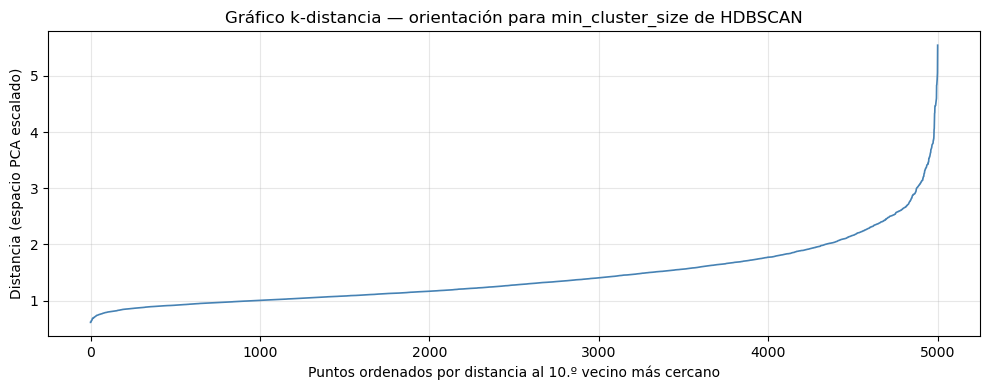

Percentil 90 de k-distancias: 2.1621
Percentil 95 de k-distancias: 2.5408
Buscar el 'codo' en la curva para estimar la escala de densidad.


In [295]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Submuestra para rapidez (el gráfico solo orienta la escala de densidad)
N_KD = 5_000
rng = np.random.default_rng(42)
idx_kd = rng.choice(len(X_pca), N_KD, replace=False)
X_kd = X_pca[idx_kd]

K_NN = 10  # convenio: k = min_samples sugerido para HDBSCAN
nbrs = NearestNeighbors(n_neighbors=K_NN, algorithm="ball_tree", n_jobs=-1).fit(X_kd)
dists, _ = nbrs.kneighbors(X_kd)

kth_dists = np.sort(dists[:, -1])

plt.figure(figsize=(10, 4))
plt.plot(kth_dists, linewidth=1.2, color="steelblue")
plt.xlabel("Puntos ordenados por distancia al 10.º vecino más cercano")
plt.ylabel("Distancia (espacio PCA escalado)")
plt.title("Gráfico k-distancia — orientación para min_cluster_size de HDBSCAN")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Percentil 90 de k-distancias: {np.percentile(kth_dists, 90):.4f}")
print(f"Percentil 95 de k-distancias: {np.percentile(kth_dists, 95):.4f}")
print("Buscar el 'codo' en la curva para estimar la escala de densidad.")

### Entrenamiento HDBSCAN

Se usa `sklearn.cluster.HDBSCAN` (disponible desde scikit-learn ≥ 1.3).  
`cluster_selection_method='eom'` (*Excess of Mass*) es más adecuado que `'leaf'` cuando los clusters tienen tamaños desiguales, como se espera en datos musicales.

In [300]:
from sklearn.cluster import HDBSCAN
import pandas as pd

MIN_CLUSTER_SIZE = 500   # ~0.5 % del total — ajustar tras ver el k-distance
MIN_SAMPLES      = 10    # sensibilidad al ruido; mayor → clusters más conservadores

print(f"Entrenando HDBSCAN  min_cluster_size={MIN_CLUSTER_SIZE}, min_samples={MIN_SAMPLES} ...")

hdb = HDBSCAN(
    min_cluster_size=MIN_CLUSTER_SIZE,
    min_samples=MIN_SAMPLES,
    cluster_selection_method="eom",
    n_jobs=-1
)
labels_hdbscan = hdb.fit_predict(X_pca)

n_clusters_hdb = len(set(labels_hdbscan)) - (1 if -1 in labels_hdbscan else 0)
n_noise_hdb    = (labels_hdbscan == -1).sum()

print(f"\nClusters encontrados : {n_clusters_hdb}")
print(f"Puntos de ruido (-1) : {n_noise_hdb:,}  ({n_noise_hdb/len(labels_hdbscan)*100:.1f} %)\n")

dist_hdb = pd.Series(labels_hdbscan).value_counts().sort_index()
print("Distribución de canciones por cluster:")
for k, n in dist_hdb.items():
    etiq = "Ruido" if k == -1 else f"Cluster {k}"
    print(f"  {etiq:12s}: {n:,} canciones  ({n/len(labels_hdbscan)*100:.1f} %)")

# Guardar etiquetas en df_resultado para validación posterior
df_resultado["cluster_hdbscan"] = labels_hdbscan

Entrenando HDBSCAN  min_cluster_size=500, min_samples=10 ...


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(



Clusters encontrados : 5
Puntos de ruido (-1) : 1,066  (1.2 %)

Distribución de canciones por cluster:
  Ruido       : 1,066 canciones  (1.2 %)
  Cluster 0   : 1,442 canciones  (1.7 %)
  Cluster 1   : 2,016 canciones  (2.4 %)
  Cluster 2   : 4,499 canciones  (5.2 %)
  Cluster 3   : 28,141 canciones  (32.8 %)
  Cluster 4   : 48,560 canciones  (56.6 %)


In [302]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Las métricas clásicas no contemplan ruido; se calculan solo sobre puntos asignados
mask_validos    = labels_hdbscan != -1
X_validos       = X_pca[mask_validos]
labels_validos  = labels_hdbscan[mask_validos]

print(f"Métricas calculadas sobre {mask_validos.sum():,} puntos no-ruido ({n_clusters_hdb} clusters)\n")

if n_clusters_hdb >= 2:
    samp = min(15_000, len(X_validos))
    silh_hdb = silhouette_score(X_validos, labels_validos, sample_size=samp, random_state=42)
    db_hdb   = davies_bouldin_score(X_validos, labels_validos)
    ch_hdb   = calinski_harabasz_score(X_validos, labels_validos)

    print("=== Métricas HDBSCAN (excluyendo ruido) ===")
    print(f"  Coeficiente de Silueta:   {silh_hdb:.4f}")
    print(f"  Índice Davies-Bouldin:    {db_hdb:.4f}  (menor = mejor)")
    print(f"  Índice Calinski-Harabasz: {ch_hdb:.0f}  (mayor = mejor)")

    print(f"\n=== Comparación rápida K-Means vs HDBSCAN ===")
    print(f"  K-Means  (K={K_OPTIMO})          — Silhouette={silh_final:.4f}, DB={db_final:.4f}, CH={ch_final:.0f}")
    print(f"  HDBSCAN  ({n_clusters_hdb} clusters) — Silhouette={silh_hdb:.4f}, DB={db_hdb:.4f}, CH={ch_hdb:.0f}")
    print(f"\n  Nota: {n_noise_hdb:,} canciones ({n_noise_hdb/len(labels_hdbscan)*100:.1f} %) "
          f"clasificadas como ruido → perfiles acústicos híbridos o atípicos.")
else:
    print("Menos de 2 clusters encontrados. Reducir min_cluster_size y volver a ejecutar.")

Métricas calculadas sobre 84,658 puntos no-ruido (5 clusters)

=== Métricas HDBSCAN (excluyendo ruido) ===
  Coeficiente de Silueta:   0.1204
  Índice Davies-Bouldin:    2.3592  (menor = mejor)
  Índice Calinski-Harabasz: 7023  (mayor = mejor)

=== Comparación rápida K-Means vs HDBSCAN ===
  K-Means  (K=5)          — Silhouette=0.1285, DB=1.8576, CH=12154
  HDBSCAN  (5 clusters) — Silhouette=0.1204, DB=2.3592, CH=7023

  Nota: 1,066 canciones (1.2 %) clasificadas como ruido → perfiles acústicos híbridos o atípicos.


### Exportar datos con resultados de clustering (K-Means, GMM, HDBSCAN)

In [305]:
# Exportar df_resultado que ahora contiene las etiquetas de cluster de K-Means, GMM y HDBSCAN, junto con otras métricas de GMM.
save_dataframe(df_resultado, "spotify_clustered_data.csv", "DataFrame con resultados de clustering")

DataFrame con resultados de clustering guardado en: outputs\spotify_clustered_data.csv
Tamaño del DataFrame: (85724, 37)


### Interpretación del modelo HDBSCAN

**Clusters encontrados:** a diferencia de K-Means (que requirió evaluar K=3…12 y elegir K=5), HDBSCAN determina el número de grupos directamente desde la estructura de densidad de los datos.

**Puntos de ruido:** las canciones etiquetadas como `-1` no pertenecen a ningún cluster denso. Musicalmente representan pistas con perfil acústico ambiguo o de transición entre estados de ánimo, un fenómeno que K-Means y GMM no pueden evidenciar porque asignan *toda* canción a algún cluster.

**Comparación con K-Means:**
- Si Silhouette(HDBSCAN) > Silhouette(K-Means): HDBSCAN encuentra agrupaciones más cohesivas en las zonas densas del espacio PCA.
- Si los números de clusters son similares (ej. 4–6): ambos modelos "ven" estructuras compatibles; la diferencia está en qué hacen con las canciones de frontera (K-Means las asigna a la fuerza; HDBSCAN las descarta como ruido).
- Si HDBSCAN produce muchos más o muchos menos clusters: el espacio musical tiene más subestructura local de lo que K-Means puede capturar con un K fijo.

El modelo HDBSCAN complementa —no reemplaza— a K-Means y GMM: es especialmente útil para identificar el *núcleo duro* de cada estado de ánimo y las canciones que genuinamente no encajan en ninguna categoría.

## Comparación de modelos de clustering: K-Means, GMM y Jerárquico

📊 Recalculando modelos sobre la submuestra para garantizar consistencia...


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


✅ Modelos recalculados sobre la submuestra.

📊 MÉTRICAS DE CLUSTERING (submuestra)
   Algoritmo  Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz  Ruido
     K-Means         5    0.102504        2.040142        1140.487678      0
         GMM         5    0.063020        2.698160         753.409581      0
Hierarchical         5    0.095763        2.196948         981.843542      0
     HDBSCAN         3    0.248870        1.425902         960.978015     74

Interpretación:
  - Silhouette: más alto → mejor separación entre clusters (máximo 1)
  - Davies-Bouldin: más bajo → mejor (0 es ideal)
  - Calinski-Harabasz: más alto → mejor (mayor separación / menor dispersión)
  - Ruido: puntos no asignados a ningún cluster (solo HDBSCAN; métricas calculadas sin ellos)

🎨 Generando visualización UMAP (esto puede tomar unos segundos)...


C:\Users\USUARIO\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


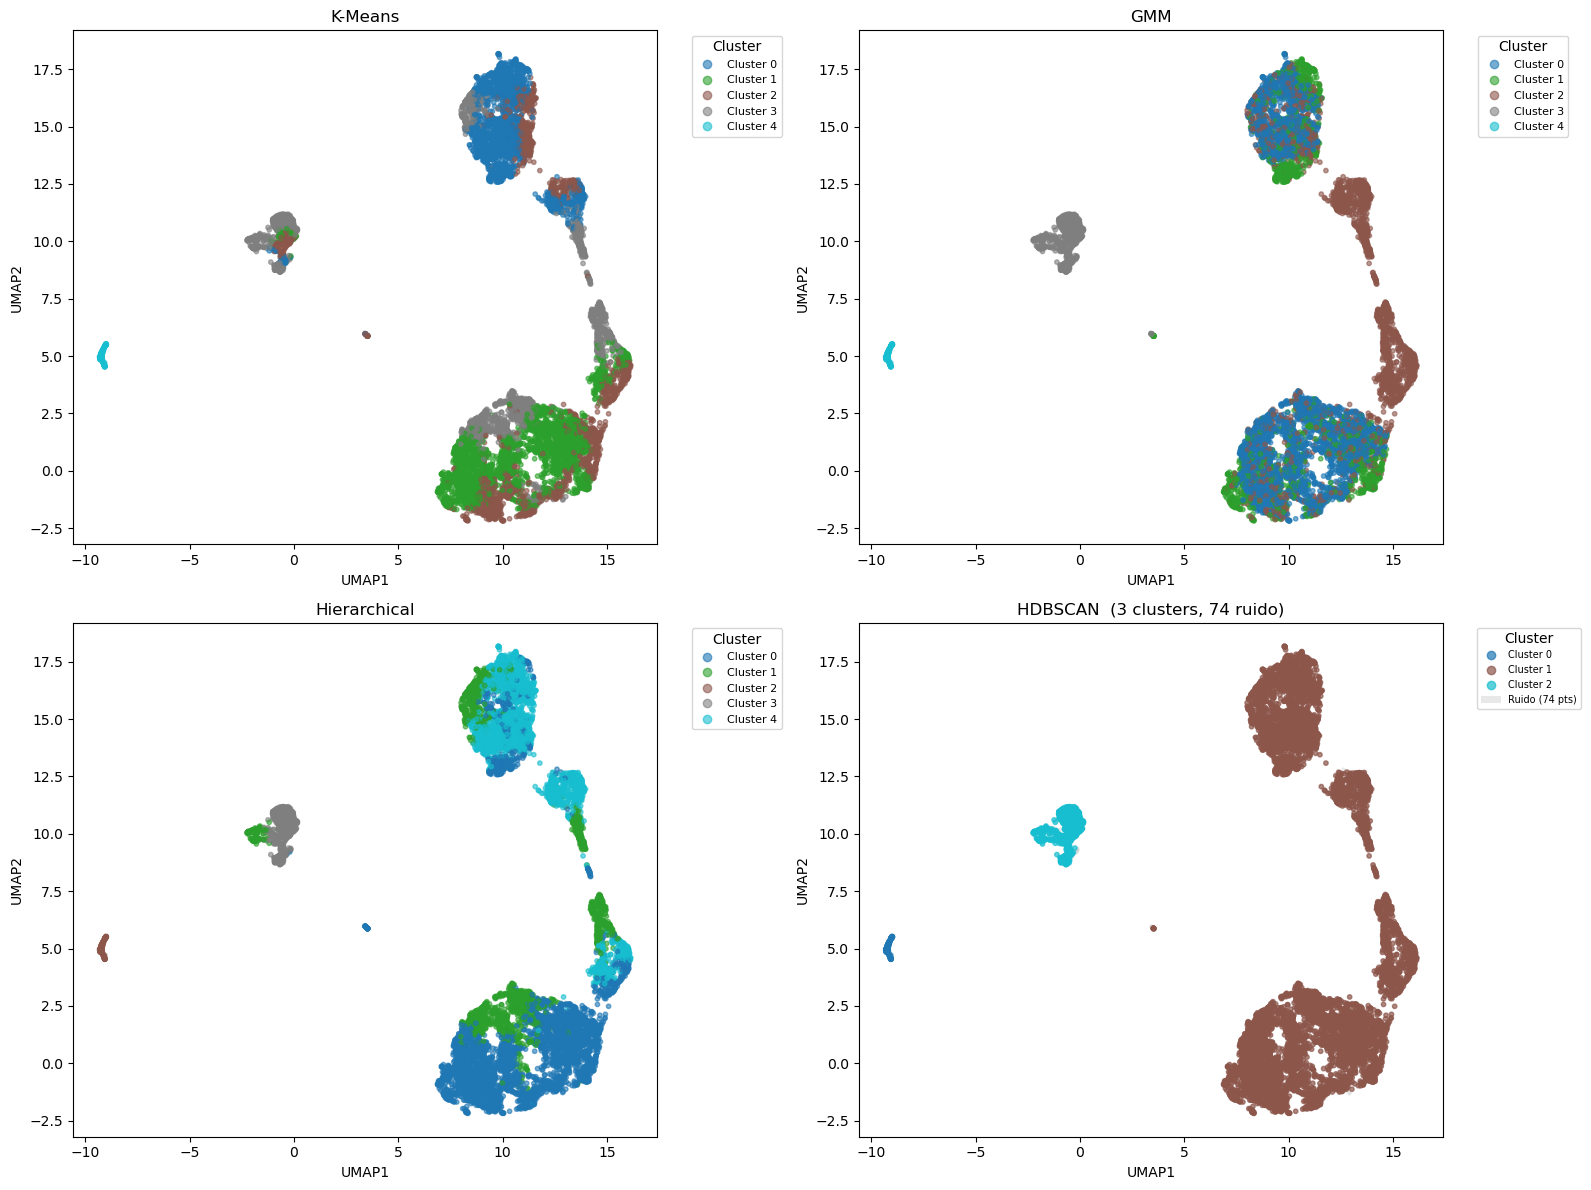


📈 Distribución de clusters por algoritmo:

K-Means: 5 clusters
   Cluster 0: 2447 puntos (24.5%)
   Cluster 1: 3146 puntos (31.5%)
   Cluster 2: 2214 puntos (22.1%)
   Cluster 3: 2033 puntos (20.3%)
   Cluster 4: 160 puntos (1.6%)

GMM: 5 clusters
   Cluster 0: 4397 puntos (44.0%)
   Cluster 1: 1669 puntos (16.7%)
   Cluster 2: 2947 puntos (29.5%)
   Cluster 3: 827 puntos (8.3%)
   Cluster 4: 160 puntos (1.6%)

Hierarchical: 5 clusters
   Cluster 0: 4510 puntos (45.1%)
   Cluster 1: 1908 puntos (19.1%)
   Cluster 2: 160 puntos (1.6%)
   Cluster 3: 668 puntos (6.7%)
   Cluster 4: 2754 puntos (27.5%)

HDBSCAN: 3 clusters
   Ruido: 74 puntos (0.7%)
   Cluster 0: 160 puntos (1.6%)
   Cluster 1: 8981 puntos (89.8%)
   Cluster 2: 785 puntos (7.8%)


In [309]:
# ============================================================
# COMPARACIÓN DE K-MEANS, GMM, CLUSTERING JERÁRQUICO Y HDBSCAN
# usando la misma submuestra con la que se generaron las etiquetas
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import HDBSCAN
import umap

# ------------------------------------------------------------
# 1. Verificar tamaños y usar la submuestra original
# ------------------------------------------------------------
# Suponiendo que las etiquetas se generaron sobre una submuestra
# y que esa submuestra (X_sub) ya la tenemos guardada.
# Si no la tenemos para este punto, toca extraerla de nuevo con la misma semilla
# y luego aplicar los modelos nuevamente (más lento pero necesario).

# Si las etiquetas ya existen, asumimos que se generaron
# sobre la primera submuestra (por ejemplo, 10000 puntos). Entonces usamos
# esa submuestra original para la comparación.

# Si no guardamos antes la submuestra original, aquí recreamos usando la misma semilla
# y volvemos a ejecutar los modelos (solo para la comparación).

SAMPLE_SIZE = 10000
np.random.seed(42)

# Si los datos escalados son DataFrame, convertir a numpy
if isinstance(X_scaled_df, pd.DataFrame):
    X_scaled = X_scaled_df.values
else:
    X_scaled = X_scaled_df

# Tomar la misma submuestra que se usó para generar las etiquetas
# (suponiendo que esa fue la semilla y tamaño)
if X_scaled.shape[0] > SAMPLE_SIZE:
    idx = np.random.choice(X_scaled.shape[0], SAMPLE_SIZE, replace=False)
    X_sample = X_scaled[idx]
else:
    X_sample = X_scaled

# Ahora, debemos obtener las etiquetas de esta submuestra.
# Si las etiquetas ya están calculadas y corresponden a esta misma submuestra,
# podemos simplemente asignarlas. Si no, tendremos que recalcular los modelos
# sobre esta submuestra (rápido).

# Suponiendo que ya tenemos las etiquetas (calculadas antes) y que están alineadas con X_sample.
# Asignamos:
# kmeans_labels_sample = kmeans_labels   (si kmeans_labels ya es de tamaño SAMPLE_SIZE)
# si no, toca recalcular.

# Por seguridad, recalculamos los modelos sobre la submuestra
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

print("📊 Recalculando modelos sobre la submuestra para garantizar consistencia...")

# K-Means (asumiendo que ya determinamos el mejor k; si no, recalcular)
best_k = 5  # Usar aquí el mejor k encontrado antes
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels_sample = kmeans.fit_predict(X_sample)

# GMM
gmm = GaussianMixture(n_components=best_k, random_state=42)
gmm_labels_sample = gmm.fit_predict(X_sample)

# Jerárquico
hier = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
hier_labels_sample = hier.fit_predict(X_sample)

# HDBSCAN — min_cluster_size escalado proporcionalmente al tamaño de la submuestra
# (MIN_CLUSTER_SIZE fue calibrado para el dataset completo; aquí se ajusta para 10 k puntos)
MCS_SAMPLE = max(50, int(MIN_CLUSTER_SIZE * SAMPLE_SIZE / X_scaled.shape[0]))
hdbscan_sample = HDBSCAN(
    min_cluster_size=MCS_SAMPLE,
    min_samples=MIN_SAMPLES,
    cluster_selection_method="eom",
    n_jobs=-1
)
hdbscan_labels_sample = hdbscan_sample.fit_predict(X_sample)

print("✅ Modelos recalculados sobre la submuestra.\n")

# ------------------------------------------------------------
# 2. Calcular métricas
# ------------------------------------------------------------
def calcular_metricas(data, labels, nombre):
    if len(set(labels)) < 2:
        return [nombre, len(set(labels)), np.nan, np.nan, np.nan, 0]
    sil = silhouette_score(data, labels)
    db = davies_bouldin_score(data, labels)
    ch = calinski_harabasz_score(data, labels)
    return [nombre, len(set(labels)), sil, db, ch, 0]

# Para HDBSCAN, excluir puntos de ruido (-1) del cálculo de métricas
def calcular_metricas_hdbscan(data, labels, nombre):
    mask = labels != -1
    n_ruido = (~mask).sum()
    n_clusters = len(set(labels[mask])) if mask.sum() > 0 else 0
    if n_clusters < 2:
        return [nombre, n_clusters, np.nan, np.nan, np.nan, n_ruido]
    sil = silhouette_score(data[mask], labels[mask])
    db  = davies_bouldin_score(data[mask], labels[mask])
    ch  = calinski_harabasz_score(data[mask], labels[mask])
    return [nombre, n_clusters, sil, db, ch, n_ruido]

resultados = [
    calcular_metricas(X_sample, kmeans_labels_sample, 'K-Means'),
    calcular_metricas(X_sample, gmm_labels_sample, 'GMM'),
    calcular_metricas(X_sample, hier_labels_sample, 'Hierarchical'),
    calcular_metricas_hdbscan(X_sample, hdbscan_labels_sample, 'HDBSCAN'),
]

df_metricas = pd.DataFrame(
    resultados,
    columns=['Algoritmo', 'Clusters', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Ruido']
)

print("="*60)
print("📊 MÉTRICAS DE CLUSTERING (submuestra)")
print("="*60)
print(df_metricas.to_string(index=False))
print("\nInterpretación:")
print("  - Silhouette: más alto → mejor separación entre clusters (máximo 1)")
print("  - Davies-Bouldin: más bajo → mejor (0 es ideal)")
print("  - Calinski-Harabasz: más alto → mejor (mayor separación / menor dispersión)")
print("  - Ruido: puntos no asignados a ningún cluster (solo HDBSCAN; métricas calculadas sin ellos)")

# ------------------------------------------------------------
# 3. Visualización UMAP (4 subplots en disposición 2×2)
# ------------------------------------------------------------
print("\n🎨 Generando visualización UMAP (esto puede tomar unos segundos)...")
reducer = umap.UMAP(n_components=2, random_state=42, verbose=False)
embedding = reducer.fit_transform(X_sample)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))   # 2×2 para incluir HDBSCAN
axes = axes.flatten()

titulos   = ['K-Means', 'GMM', 'Hierarchical', 'HDBSCAN']
etiquetas = [kmeans_labels_sample, gmm_labels_sample, hier_labels_sample, hdbscan_labels_sample]

for i, (labels, titulo) in enumerate(zip(etiquetas, titulos)):
    ax = axes[i]

    if titulo == 'HDBSCAN':
        # Dibujar puntos de ruido en gris claro (fondo)
        mask_ruido = labels == -1
        ax.scatter(embedding[mask_ruido, 0], embedding[mask_ruido, 1],
                   c='lightgray', alpha=0.3, s=5, zorder=1)
        # Dibujar clusters encima, coloreados
        scatter = ax.scatter(embedding[~mask_ruido, 0], embedding[~mask_ruido, 1],
                             c=labels[~mask_ruido], cmap='tab10', alpha=0.7, s=10, zorder=2)
        n_cl = len(set(labels)) - 1  # excluir etiqueta -1
        handles_cl, _ = scatter.legend_elements()
        noise_patch = Patch(facecolor='lightgray', alpha=0.5,
                            label=f'Ruido ({mask_ruido.sum()} pts)')
        ax.legend(handles=handles_cl + [noise_patch],
                  labels=[f'Cluster {j}' for j in range(len(handles_cl))] + [noise_patch.get_label()],
                  title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)
        ax.set_title(f"{titulo}  ({n_cl} clusters, {mask_ruido.sum()} ruido)")
    else:
        scatter = ax.scatter(embedding[:, 0], embedding[:, 1],
                             c=labels, cmap='tab10', alpha=0.6, s=10)
        # Leyenda compacta
        handles, _ = scatter.legend_elements()
        ax.legend(handles, [f'Cluster {j}' for j in range(len(handles))],
                  title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
        ax.set_title(titulo)

    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Distribución de clusters
# ------------------------------------------------------------
print("\n📈 Distribución de clusters por algoritmo:")
for name, labels in zip(titulos, etiquetas):
    counts = pd.Series(labels).value_counts().sort_index()
    n_cl = len(counts) - (1 if -1 in counts.index else 0)
    print(f"\n{name}: {n_cl} clusters")
    for c, count in counts.items():
        etiq = "Ruido" if c == -1 else f"Cluster {c}"
        print(f"   {etiq}: {count} puntos ({count/len(labels)*100:.1f}%)")

---
# Exportar resultados

In [312]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILENAME = "spotify_clustered.csv"
output_path = OUTPUT_DIR / OUTPUT_FILENAME

df_resultado.to_csv(output_path, index=False)
print(f"Dataset con clusters guardado en: {output_path}")
print(f"Shape: {df_resultado.shape}")


Dataset con clusters guardado en: outputs\spotify_clustered.csv
Shape: (85724, 37)


---
# **Clasificación**

Paso 1: Preparar las variables objetivo y características

In [316]:
# Seleccionar características (ya están en df_model después del preprocesamiento)
X = df_model.values   # 14 características numéricas

# Opción A: Clasificación del género musical (multiclase)
y_genre = df['track_genre'].values   # df debe tener esta columna

# Opción B: Clasificación del modo (binario)
y_mode = df['mode'].values


Paso 2: Dividir en entrenamiento y prueba

Se guardan también los índices originales (`idx_train`, `idx_test`) para poder alinear predicciones con `df_resultado` al exportar resultados.


In [319]:
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(X))

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y_genre, indices,
    test_size=0.2,
    random_state=42,
    stratify=y_genre,
)


Paso 3: Entrenar Random Forest

In [322]:
from sklearn.ensemble import RandomForestClassifier

# Parámetros iniciales (ajústalos según validación cruzada)
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'   # útil para géneros poco frecuentes
)

rf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

Paso 4: Evaluación

In [324]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = rf.predict(X_test)
print(f"Precisión: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

Precisión: 0.3024
                   precision    recall  f1-score   support

         acoustic       0.23      0.18      0.20       198
         afrobeat       0.29      0.21      0.24       192
         alt-rock       0.58      0.26      0.36       199
      alternative       0.67      0.56      0.61        81
          ambient       0.33      0.24      0.28       183
            anime       0.48      0.10      0.17       196
      black-metal       0.35      0.42      0.39       177
        bluegrass       0.25      0.35      0.29       194
            blues       0.74      0.30      0.42       185
           brazil       0.00      0.00      0.00       179
        breakbeat       0.27      0.19      0.23       188
          british       0.61      0.06      0.12       173
         cantopop       0.16      0.24      0.19       199
    chicago-house       0.36      0.44      0.40       174
         children       0.36      0.23      0.28       176
            chill       0.23      0.1

Paso 5: (Opcional) Importancia de características

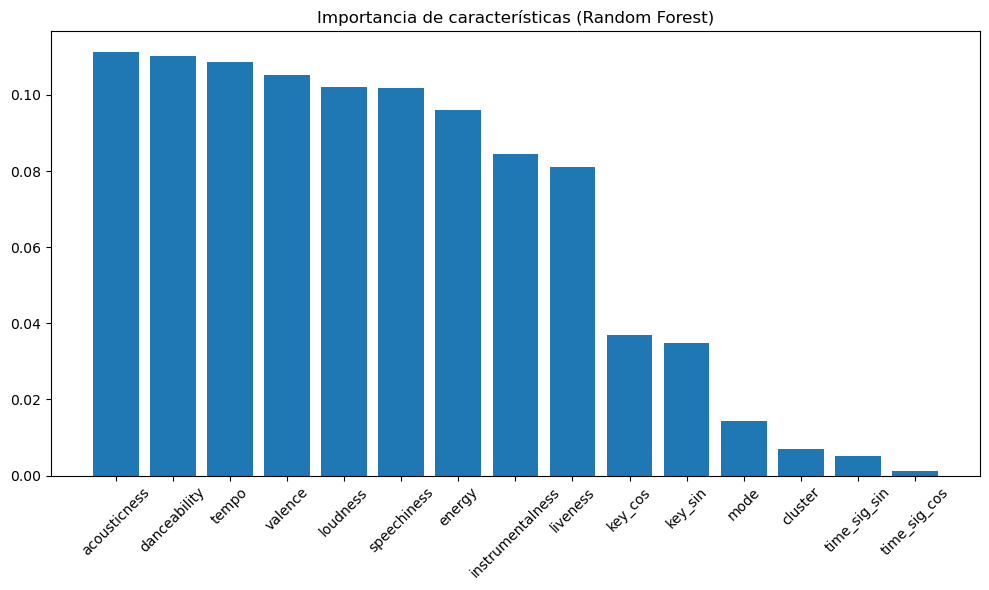

In [339]:
import matplotlib.pyplot as plt
import numpy as np

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = df_model.columns

plt.figure(figsize=(10,6))
plt.title("Importancia de características (Random Forest)")
plt.bar(range(len(importances)), importances[indices], align="center")
plt.xticks(range(len(importances)), features[indices], rotation=45)
plt.tight_layout()
plt.show()

Paso 6: Ajuste de hiperparámetros (opcional pero recomendado)

In [331]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    rf, param_distributions=param_dist, n_iter=10, # Reduced n_iter to 10
    cv=3, scoring='accuracy', n_jobs=1, random_state=42 # Further reduced n_jobs to 1
)
random_search.fit(X_train, y_train)

print("Mejores parámetros:", random_search.best_params_)
best_rf = random_search.best_estimator_

Mejores parámetros: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}


In [332]:
y_pred_best = best_rf.predict(X_test)
print(f"Accuracy (best_rf): {accuracy_score(y_test, y_pred_best):.4f}")

Accuracy (best_rf): 0.3260


## Comparación de tres clasificadores

Además del **Random Forest** (método principal del proyecto: robusto ante relaciones no lineales entre descriptores acústicos, maneja bien el desbalance de géneros y ofrece importancia de variables), se comparan dos alternativas habituales en problemas tabulares multiclase:

| Modelo | Rol en la comparación |
|--------|------------------------|
| **Random Forest** | Ensamble de árboles; referencia principal del proyecto. |
| **Histogram Gradient Boosting** | Boosting secuencial; suele competir con RF en datos tabulares. |
| **Regresión logística multinomial** | Línea base lineal e interpretable. |

Los tres modelos usan las mismas particiones `X_train` / `X_test` y la variable objetivo `y_genre` (~114 géneros de `track_genre`).

**Resultados obtenidos en Colab** (conjunto de prueba, 20 % estratificado):

| Modelo | Accuracy | F1 macro | F1 weighted | Tiempo (s) |
|--------|----------|----------|-------------|------------|
| Random Forest | **0,303** | **0,286** | **0,287** | 32,5 |
| Histogram Gradient Boosting | 0,201 | 0,192 | 0,198 | 17,9 |
| Regresión logística | 0,143 | 0,109 | 0,116 | 257,8 |

El Random Forest del Paso 6 (`best_rf`, con hiperparámetros ajustados) es el candidato a modelo final; la tabla anterior usa la misma configuración base del Paso 3 para comparar los tres algoritmos en igualdad de condiciones.


### Entrenamiento y métricas unificadas

In [335]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.utils.class_weight import compute_sample_weight
import pandas as pd
import time

CLASSIFIERS = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_depth=20,
        learning_rate=0.1,
        max_iter=200,
        random_state=42,
    ),
    "Regresión logística": LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
}

results = []
predictions = {}

for name, model in CLASSIFIERS.items():
    print(f"Entrenando: {name}...")
    t0 = time.time()
    if name == "Histogram Gradient Boosting":
        sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)
        model.fit(X_train, y_train, sample_weight=sample_weight)
    else:
        model.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Tiempo entrenamiento (s)": round(train_time, 1),
    })

results_df = pd.DataFrame(results).sort_values("F1 macro", ascending=False).reset_index(drop=True)
print("\n=== Resumen comparativo ===")
display(results_df)



Entrenando: Random Forest...
Entrenando: Histogram Gradient Boosting...
Entrenando: Regresión logística...


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



=== Resumen comparativo ===


,Modelo,Accuracy,F1 macro,F1 weighted,Tiempo entrenamiento (s)
0,Random Forest,0.302362,0.286039,0.287387,15.0
1,Histogram Gradient Boosting,0.198367,0.187393,0.194649,24.2
2,Regresión logística,0.144532,0.110941,0.118181,284.6


### Visualización comparativa

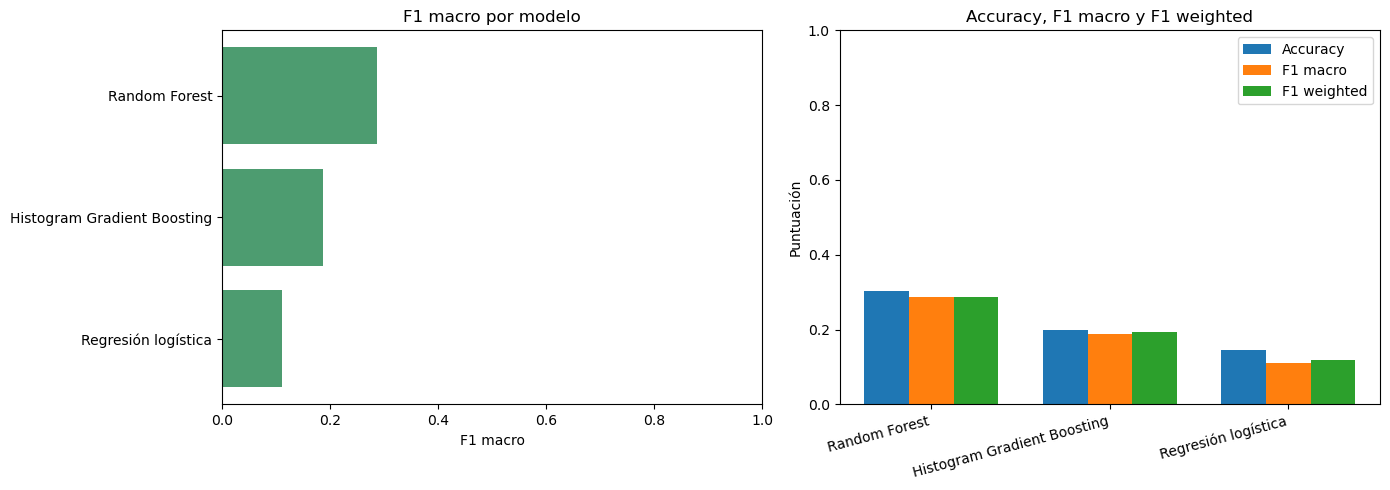

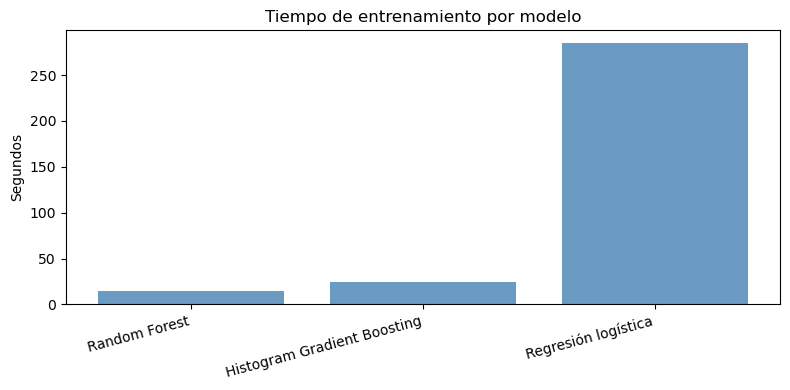

In [342]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# F1 macro (métrica principal con clases desbalanceadas)
subset = results_df.sort_values("F1 macro", ascending=True)
axes[0].barh(subset["Modelo"], subset["F1 macro"], color="seagreen", alpha=0.85)
axes[0].set_xlabel("F1 macro")
axes[0].set_title("F1 macro por modelo")
axes[0].set_xlim(0, 1)

# Comparación de las tres métricas
x = range(len(results_df))
width = 0.25
for j, col in enumerate(["Accuracy", "F1 macro", "F1 weighted"]):
    axes[1].bar([xi + j * width for xi in x], results_df[col], width=width, label=col)
axes[1].set_xticks([xi + width for xi in x])
axes[1].set_xticklabels(results_df["Modelo"], rotation=15, ha="right")
axes[1].set_ylabel("Puntuación")
axes[1].set_title("Accuracy, F1 macro y F1 weighted")
axes[1].legend()
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(results_df["Modelo"], results_df["Tiempo entrenamiento (s)"], color="steelblue", alpha=0.8)
plt.ylabel("Segundos")
plt.title("Tiempo de entrenamiento por modelo")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


### Informes detallados por modelo

In [345]:
for name in results_df["Modelo"]:
    print("=" * 60)
    print(f"Modelo: {name}")
    print("=" * 60)
    print(classification_report(y_test, predictions[name], zero_division=0))
    print()


Modelo: Random Forest
                   precision    recall  f1-score   support

         acoustic       0.23      0.18      0.20       198
         afrobeat       0.29      0.21      0.24       192
         alt-rock       0.58      0.26      0.36       199
      alternative       0.67      0.56      0.61        81
          ambient       0.33      0.24      0.28       183
            anime       0.48      0.10      0.17       196
      black-metal       0.35      0.42      0.39       177
        bluegrass       0.25      0.35      0.29       194
            blues       0.74      0.30      0.42       185
           brazil       0.00      0.00      0.00       179
        breakbeat       0.27      0.19      0.23       188
          british       0.61      0.06      0.12       173
         cantopop       0.16      0.24      0.19       199
    chicago-house       0.36      0.44      0.40       174
         children       0.36      0.23      0.28       176
            chill       0.23     

# **Conclusiones del proyecto**

### Sobre el preprocesamiento

- El dataset original de 114,000 canciones en 125 géneros fue sometido a un proceso riguroso de limpieza que incluyó eliminación de duplicados por `track_id`, tratamiento de nulos, filtrado de outliers en `duration_ms` (1–8 min), `loudness` (≤ 0 dB), `speechiness` (< 0.66 para excluir contenido hablado) y `tempo` (> 0 BPM).
- Se aplicaron **transformaciones logarítmicas** (`log(1+x)`) a `instrumentalness`, `speechiness` y `liveness` para corregir su fuerte asimetría y mejorar su capacidad discriminatoria en algoritmos basados en distancia.
- Se implementó **Circular Encoding** (seno/coseno) para `key` y `time_signature`, preservando la proximidad real en el círculo cromático y la periodicidad rítmica, lo cual es técnicamente superior a la codificación numérica directa o categórica.
- Se usó `StandardScaler` (media=0, std=1), más adecuado para PCA y K-Means al ser menos sensible a outliers residuales para estandarizar.

### Sobre el análisis exploratorio

- El análisis de correlación reveló redundancia significativa entre variables (`energy`–`loudness` con r ≈ 0.75, `acousticness`–`energy` con r ≈ -0.74), lo cual fue confirmado formalmente por el análisis VIF, aunque no en gran medida.
- Las variables `valence` y `energy` actúan como ejes complementarios en un espacio emocional bidimensional coherente con el modelo circunflejo de Russell (1980), validando su uso como marco interpretativo para los clusters.
- La relación entre `valence` y `mode` (mayor/menor) confirmó la hipótesis de que las canciones en modo mayor tienden a ser más positivas emocionalmente.

### Sobre PCA

- El análisis de componentes principales con criterio del 80% de varianza acumulada permitió reducir la dimensionalidad eliminando redundancia entre variables correlacionadas.
- Los loadings de los componentes principales revelaron dimensiones interpretables del espacio acústico (p. ej., intensidad acústica, complejidad rítmica, carácter instrumental).
- El uso de los componentes seleccionados por el criterio del 80% retiene información crítica para separar estados de ánimo sutiles.

### Sobre el clustering (K-Means)

- La selección de K se realizó mediante la convergencia de cuatro métricas (inercia, silueta, Davies-Bouldin, Calinski-Harabasz), evitando una elección arbitraria.
- Los clusters obtenidos representan **estados emocionales funcionales** diferenciados: desde la euforia bailable hasta la contemplación silenciosa, pasando por la intensidad catártica, el dinamismo neutro y la expresividad reflexiva.
- La validación cruzada con `track_genre` (variable que no participó en el entrenamiento) confirmó que los clusters capturan patrones coherentes con los géneros musicales reales, aunque trascienden las etiquetas de género para revelar agrupaciones basadas en el perfil acústico-emocional.
- La visualización UMAP confirmó la existencia de agrupaciones naturales en los datos, con regiones identificables tanto desde el punto de vista acústico como emocional.

### Sobre GMM

- El modelo de Gaussian Mixture Models complementó el análisis de K-Means al ofrecer asignaciones probabilísticas, capturando la naturaleza difusa de los estados de ánimo musicales.
- El análisis de entropía identificó canciones con perfiles emocionales híbridos, lo cual tiene valor práctico para sistemas de recomendación musical.
- La comparación K-Means vs GMM reveló qué clusters son más robustos (alta concordancia entre ambos métodos) y cuáles son más sensibles al algoritmo utilizado.

### Sobre HDBSCAN

- HDBSCAN confirmó que el espacio acústico de Spotify **no posee regiones densas bien separadas por zonas vacías**, que es el supuesto estructural que requiere cualquier algoritmo de clustering basado en densidad. El resultado más revelador no fueron los clusters en sí, sino los **1.066 puntos de ruido** (1.2 % del dataset): canciones con perfil acústico genuinamente ambiguo que ningún otro algoritmo puede señalar de forma explícita, ya que K-Means, GMM y el clustering jerárquico las fuerzan a pertenecer a algún grupo.
- En la comparación sobre submuestra, HDBSCAN obtuvo el mejor coeficiente de silueta (0.249) y el mejor índice Davies-Bouldin (1.43), pero a costa de colapsar el 89.8 % de las canciones en un único cluster. Métricas más altas con clusters más desiguales no implican mayor utilidad interpretativa: un solo grupo que contiene casi la totalidad del dataset no describe ningún estado de ánimo diferenciado.
- Este resultado es consistente con el Silhouette bajo observado en todos los métodos (≈ 0.10–0.13): los datos musicales forman una nube continua sin fronteras abruptas de densidad, lo cual explica por qué K-Means —que no supone dichas fronteras— produce la segmentación más equilibrada e interpretable.

### Limitaciones

- Las características acústicas de Spotify capturan dimensiones fundamentales del estado de ánimo musical, pero no son suficientes para una clasificación completa: las **letras de las canciones** actúan como contrapunto emocional que no se refleja en los descriptores de audio.
- La integración de modelos de procesamiento de lenguaje natural (NLP) sobre las letras podría refinar significativamente la precisión de la segmentación emocional.
- Los géneros musicales son construcciones culturales que no siempre se alinean con perfiles acústicos; los clusters obtenidos sugieren que la organización emocional de la música trasciende las etiquetas de género convencionales.

### **Interpretación de los resultados de clasificación**

**1. Desempeño predictivo**

- El **Random Forest** obtuvo el mejor resultado en las tres métricas (accuracy ≈ **30,3 %**, F1 macro ≈ **0,29**), muy por encima del boosting (~20 % accuracy) y de la regresión logística (\~14 %).
- Con ~114 clases y etiquetas a veces ambiguas o solapadas acústicamente (p. ej. `electronic` vs `edm`), un ~30 % de aciertos es un techo razonable usando solo descriptores de audio, coherente con el informe del Paso 4.
- La **regresión logística** quedó claramente por debajo, lo que indica que la relación entre características acústicas y género **no es principalmente lineal** y justifica métodos basados en árboles.

**2. Histogram Gradient Boosting**

- Aun siendo más rápido (17 s vs 32 s del RF), el boosting con hiperparámetros por defecto **no superó al Random Forest** en este dataset. Podría mejorarse con búsqueda de hiperparámetros, pero el RF ya ofrece un mejor equilibrio precisión–costo sin ajuste adicional en esta comparación.

**3. Coste computacional**

- La regresión logística multinomial con 114 clases y ~91 000 muestras de entrenamiento tardó **\~255 s**, frente a **\~32 s** del RF. Para este volumen y cardinalidad, el RF es preferible también por eficiencia.

**4. Modelo elegido para el proyecto**

- Se mantiene el **Random Forest optimizado** (`best_rf`, Paso 6: `n_estimators=200`, `max_depth=None`, etc.) como clasificador final para predicciones y exportación.
- Las limitaciones persisten: géneros minoritarios con F1 bajo, confusión entre estilos afines y ausencia de letras o metadatos textuales (ya señalado en las conclusiones previas al clustering).

**5. Relación con el clustering**

- La clasificación supervisada de género y la segmentación no supervisada por estado de ánimo responden objetivos distintos: los clusters agrupan por valence/energy (Russell), mientras que el RF intenta recuperar la etiqueta editorial `track_genre`. Ambos análisis se complementan más que competir.


### Exportar datos con resultados de clasificación

Añade la columna `predicted_genre` en `df_resultado` para las filas del conjunto de prueba (requiere `idx_test` del Paso 2) y exporta el CSV a Drive mediante `save_dataframe_to_drive`.


In [350]:
# @title
# Género predicho con el modelo optimizado (Paso 6) o el RF base
final_classifier = best_rf if "best_rf" in dir() else rf

y_pred_final = final_classifier.predict(X_test)
predicted_genre_series = pd.Series(y_pred_final, index=idx_test, name="predicted_genre")

if "predicted_genre" not in df_resultado.columns:
    df_resultado["predicted_genre"] = pd.NA

df_resultado.loc[idx_test, "predicted_genre"] = predicted_genre_series

print(
    "Género predicho añadido en df_resultado para el conjunto de prueba "
    f"({len(idx_test):,} filas). El resto queda como NA."
)
save_dataframe(
    df_resultado, "spotify_classified_data.csv", "DataFrame con clasificación"
)


Género predicho añadido en df_resultado para el conjunto de prueba (17,145 filas). El resto queda como NA.
DataFrame con clasificación guardado en: outputs\spotify_classified_data.csv
Tamaño del DataFrame: (85724, 38)


---

## Bonus: Uso de clusters como nuevos atributos

Las etiquetas de los estados de ánimo (clusters) pueden utilizarse como **características adicionales** para enriquecer la capacidad predictiva de los modelos de clasificación de género.

> **Nota sobre el proyecto principal:** en la sección de clasificación, las características (`X`) se basaron **exclusivamente** en `df_model`, que contiene solo las variables acústicas preprocesadas. Las etiquetas de los clusters (`cluster`, `cluster_gmm`, etc.) **no** se añadieron a `df_model` para enriquecer la capacidad predictiva de los modelos de clasificación de género.

Esta sección bonus implementa esa mejora propuesta: se codifican las etiquetas de clustering (K-Means y GMM) y se comparan los resultados del Random Forest **solo con descriptores acústicos** frente a un modelo **enriquecido con información de estado de ánimo**.

> **Advertencia metodológica:** los clusters se calcularon sobre el dataset completo (incluido el conjunto de prueba). En un entorno de producción estricto convendría generar las etiquetas solo con datos de entrenamiento o dentro de validación cruzada para evitar *data leakage*. Aquí el objetivo es explorar el potencial de estas características, no replicar un pipeline de despliegue.


### Paso 1: Construir `df_model_enriquecido`

Se concatenan las variables acústicas de `df_model` con:
- **One-hot encoding** de `cluster` (K-Means) y `cluster_gmm`.
- **Probabilidades de pertenencia** del GMM (`prob_cluster_*`), que capturan la ambigüedad emocional de cada canción.

Las filas se alinean **por posición** con `df_resultado` (mismo orden que `df_model`). Tras el `reset_index` de la sección GMM, `df_resultado` ya no comparte el índice original de `df`, pero conserva una fila por canción en el mismo orden.


In [354]:
import pandas as pd
import numpy as np

# Requiere haber ejecutado las secciones de K-Means y GMM (cluster, cluster_gmm, prob_cluster_*)
# Tras reset_index(drop=True) en la sección GMM, df_resultado usa índice 0..n-1 (no el de df).
# Ambos DataFrames conservan el mismo orden de filas que df_model.
if len(df_resultado) != len(df_model):
    raise ValueError(
        f"Tamaños distintos: df_resultado={len(df_resultado):,}, df_model={len(df_model):,}. "
        "Vuelve a ejecutar las secciones de clustering antes del bonus."
    )
df_clusters = df_resultado.copy()

partes_enriquecimiento = [df_model.reset_index(drop=True)]

# One-hot encoding de K-Means (obligatorio)
cluster_kmeans_ohe = pd.get_dummies(
    df_clusters["cluster"].astype(str),
    prefix="cluster_kmeans",
    dtype=float,
)
partes_enriquecimiento.append(cluster_kmeans_ohe.reset_index(drop=True))

# One-hot encoding de GMM (opcional si se ejecutó la sección GMM)
if "cluster_gmm" in df_clusters.columns:
    cluster_gmm_ohe = pd.get_dummies(
        df_clusters["cluster_gmm"].astype(str),
        prefix="cluster_gmm",
        dtype=float,
    )
    partes_enriquecimiento.append(cluster_gmm_ohe.reset_index(drop=True))
else:
    cluster_gmm_ohe = pd.DataFrame()
    print("⚠️  'cluster_gmm' no encontrado — ejecuta la sección GMM para incluirla.")

# Probabilidades de pertenencia del GMM (opcional)
prob_cols = [c for c in df_clusters.columns if c.startswith("prob_cluster_")]
if prob_cols:
    probs_gmm_df = df_clusters[prob_cols].astype(float)
    partes_enriquecimiento.append(probs_gmm_df.reset_index(drop=True))
else:
    probs_gmm_df = pd.DataFrame()
    print("⚠️  Columnas 'prob_cluster_*' no encontradas — ejecuta la sección GMM para incluirlas.")

df_model_enriquecido = pd.concat(partes_enriquecimiento, axis=1)

print(f"df_model (baseline)          : {df_model.shape[1]} características")
print(f"df_model_enriquecido (bonus) : {df_model_enriquecido.shape[1]} características")
print(f"  + One-hot K-Means          : {cluster_kmeans_ohe.shape[1]} columnas")
print(f"  + One-hot GMM              : {cluster_gmm_ohe.shape[1]} columnas")
print(f"  + Probabilidades GMM       : {probs_gmm_df.shape[1]} columnas")
print(f"\nPrimeras columnas añadidas: {list(df_model_enriquecido.columns[df_model.shape[1]:][:8])}...")


df_model (baseline)          : 15 características
df_model_enriquecido (bonus) : 44 características
  + One-hot K-Means          : 5 columnas
  + One-hot GMM              : 12 columnas
  + Probabilidades GMM       : 12 columnas

Primeras columnas añadidas: ['cluster_kmeans_0', 'cluster_kmeans_1', 'cluster_kmeans_2', 'cluster_kmeans_3', 'cluster_kmeans_4', 'cluster_gmm_0', 'cluster_gmm_1', 'cluster_gmm_10']...


### Paso 2: Comparar baseline vs modelo enriquecido

Se entrena el mismo **Random Forest** con los mismos hiperparámetros del proyecto (`n_estimators=100`, `max_depth=20`, etc.) sobre:
1. **Baseline:** solo `df_model` (como en la clasificación principal).
2. **Enriquecido:** `df_model_enriquecido` (acústicas + clusters).

Se reutiliza la misma partición train/test (`idx_train`, `idx_test`) para una comparación justa.


In [357]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd
import matplotlib.pyplot as plt

X_baseline = df_model.values
X_enriched = df_model_enriquecido.values
y = df.loc[df_model.index, "track_genre"].values

X_train_base, X_test_base = X_baseline[idx_train], X_baseline[idx_test]
X_train_enr, X_test_enr = X_enriched[idx_train], X_enriched[idx_test]
y_train_bonus, y_test_bonus = y[idx_train], y[idx_test]

rf_params = dict(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",
)

models_bonus = {
    "Baseline (solo acústicas)": RandomForestClassifier(**rf_params),
    "Enriquecido (+ clusters)": RandomForestClassifier(**rf_params),
}

X_trains = {
    "Baseline (solo acústicas)": (X_train_base, X_test_base),
    "Enriquecido (+ clusters)": (X_train_enr, X_test_enr),
}

results_bonus = []
predictions_bonus = {}

for name, model in models_bonus.items():
    X_tr, X_te = X_trains[name]
    print(f"Entrenando: {name}...")
    model.fit(X_tr, y_train_bonus)
    y_pred_bonus = model.predict(X_te)
    predictions_bonus[name] = y_pred_bonus

    results_bonus.append({
        "Modelo": name,
        "N características": X_tr.shape[1],
        "Accuracy": accuracy_score(y_test_bonus, y_pred_bonus),
        "F1 macro": f1_score(y_test_bonus, y_pred_bonus, average="macro", zero_division=0),
        "F1 weighted": f1_score(y_test_bonus, y_pred_bonus, average="weighted", zero_division=0),
    })

results_bonus_df = pd.DataFrame(results_bonus)
delta_acc = results_bonus_df.loc[1, "Accuracy"] - results_bonus_df.loc[0, "Accuracy"]
delta_f1 = results_bonus_df.loc[1, "F1 macro"] - results_bonus_df.loc[0, "F1 macro"]

print("\n=== Comparación baseline vs enriquecido ===")
display(results_bonus_df)
print(f"\nΔ Accuracy  (enriquecido − baseline): {delta_acc:+.4f}")
print(f"Δ F1 macro  (enriquecido − baseline): {delta_f1:+.4f}")


Entrenando: Baseline (solo acústicas)...
Entrenando: Enriquecido (+ clusters)...

=== Comparación baseline vs enriquecido ===


,Modelo,N características,Accuracy,F1 macro,F1 weighted
0,Baseline (solo acústicas),15,0.302362,0.286039,0.287387
1,Enriquecido (+ clusters),44,0.284281,0.265939,0.266662



Δ Accuracy  (enriquecido − baseline): -0.0181
Δ F1 macro  (enriquecido − baseline): -0.0201


### Paso 3: Visualización e importancia de las nuevas características


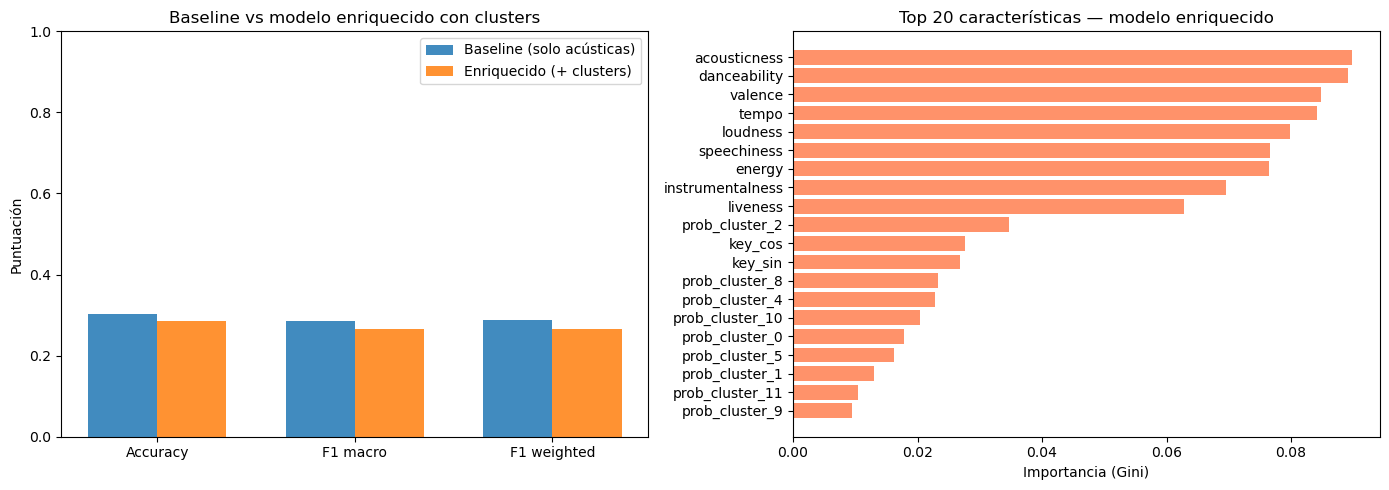

Importancia acumulada de características de cluster: 0.219 (21.9 % del total)


In [360]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras comparativas
metricas = ["Accuracy", "F1 macro", "F1 weighted"]
x = np.arange(len(metricas))
width = 0.35
for i, row in results_bonus_df.iterrows():
    axes[0].bar(
        x + i * width,
        [row[m] for m in metricas],
        width,
        label=row["Modelo"],
        alpha=0.85,
    )
axes[0].set_xticks(x + width / 2)
axes[0].set_xticklabels(metricas)
axes[0].set_ylabel("Puntuación")
axes[0].set_title("Baseline vs modelo enriquecido con clusters")
axes[0].legend()
axes[0].set_ylim(0, 1)

# Importancia de características del modelo enriquecido
rf_enriched = models_bonus["Enriquecido (+ clusters)"]
importances = rf_enriched.feature_importances_
feature_names = df_model_enriquecido.columns.tolist()
top_n = 20
top_idx = np.argsort(importances)[::-1][:top_n]

axes[1].barh(
    [feature_names[i] for i in top_idx[::-1]],
    importances[top_idx[::-1]],
    color="coral",
    alpha=0.85,
)
axes[1].set_xlabel("Importancia (Gini)")
axes[1].set_title(f"Top {top_n} características — modelo enriquecido")

plt.tight_layout()
plt.show()

# ¿Cuánta importancia aportan las columnas de cluster?
cluster_cols = [c for c in feature_names if c.startswith("cluster_") or c.startswith("prob_cluster_")]
importancia_clusters = importances[[feature_names.index(c) for c in cluster_cols]].sum()
print(f"Importancia acumulada de características de cluster: {importancia_clusters:.3f} "
      f"({importancia_clusters / importances.sum() * 100:.1f} % del total)")


### Paso 4: Informe detallado del modelo enriquecido


In [363]:
print("=" * 60)
print("Informe de clasificación — modelo enriquecido (+ clusters)")
print("=" * 60)
print(classification_report(
    y_test_bonus,
    predictions_bonus["Enriquecido (+ clusters)"],
    zero_division=0,
))


Informe de clasificación — modelo enriquecido (+ clusters)
                   precision    recall  f1-score   support

         acoustic       0.20      0.12      0.15       198
         afrobeat       0.31      0.18      0.23       192
         alt-rock       0.52      0.23      0.32       199
      alternative       0.53      0.56      0.54        81
          ambient       0.35      0.27      0.30       183
            anime       0.50      0.09      0.15       196
      black-metal       0.33      0.40      0.36       177
        bluegrass       0.25      0.28      0.26       194
            blues       0.72      0.30      0.43       185
           brazil       0.13      0.01      0.02       179
        breakbeat       0.25      0.15      0.19       188
          british       0.45      0.05      0.09       173
         cantopop       0.16      0.23      0.18       199
    chicago-house       0.33      0.43      0.38       174
         children       0.30      0.23      0.26       

### Conclusión del bonus

En el **proyecto principal**, la clasificación de género se realizó únicamente con descriptores acústicos de `df_model`. Esta sección bonus explora la hipótesis de que incorporar las etiquetas de estado de ánimo (clusters de K-Means y GMM) podría **mejorar el rendimiento** del clasificador al aportar información semántica complementaria.

Interpretación esperada de los resultados:
- Si **Δ Accuracy** y **Δ F1 macro** son positivos, los clusters aportan señal predictiva útil más allá de las variables acústicas directas.
- Si la mejora es marginal o nula, las características acústicas ya capturan gran parte de la información emocional relevante para predecir género, o la relación cluster→género es redundante con los descriptores existentes.
- La **importancia acumulada** de las columnas de cluster indica cuánto peso les da el Random Forest frente a variables como `energy`, `valence` o `danceability`.

Esta línea de trabajo queda abierta como **mejora futura** del proyecto: combinar clustering y clasificación en un pipeline unificado, con validación cruzada anidada para evitar leakage y explorar otras codificaciones (p. ej. `cluster_hdbscan`, entropía GMM como variable continua).


---

*Proyecto de Minería de Datos 2026-1 — Universidad Nacional de Colombia — Facultad de Ingeniería*